# Import Library

In [ ]:
import requests
import pandas as pd
import time
import re
import duckdb

from io import StringIO

# Scraping

In [ ]:
dataset_id = "z001-10646-3"

base_url = "https://ckan.surabaya.go.id/api/3/action"

package_url = f"{base_url}/package_show"
datastore_url = f"{base_url}/datastore_search"

In [ ]:
response = requests.get(
    package_url,
    params={"id": dataset_id}
)

response.raise_for_status()

data = response.json()

print("Status:", data["success"])

Status: True


In [ ]:
resources = data["result"]["resources"]

print("Jumlah resource:", len(resources))

Jumlah resource: 35


In [ ]:
resource_df = pd.DataFrame(resources)

display(
    resource_df[
        ["id", "name", "description", "format", "url"]
    ]
)

,id,name,description,format,url
0,bd6ff09a-ff90-4461-a159-346d4e526126,Jumlah sarana prasarana olahraga yang tersedia...,data 09-2023,CSV,https://ckan.surabaya.go.id/dataset/a7dbc9be-5...
1,eb0ef2c9-4d0e-4911-b83e-e308bc19962e,Jumlah sarana prasarana olahraga yang tersedia...,data 10-2023,CSV,https://ckan.surabaya.go.id/dataset/a7dbc9be-5...
2,e9110c8d-ca20-4e10-9110-167980311165,Jumlah sarana prasarana olahraga yang tersedia...,data 11-2023,CSV,https://ckan.surabaya.go.id/dataset/a7dbc9be-5...
3,f586cc30-01a5-4448-9e39-bd4d53843928,Jumlah sarana prasarana olahraga yang tersedia...,data 12-2023,CSV,https://ckan.surabaya.go.id/dataset/a7dbc9be-5...
4,a44bc092-daeb-4add-bec5-ad2107f943e0,Jumlah sarana prasarana olahraga yang tersedia...,data 01-2024,CSV,https://ckan.surabaya.go.id/dataset/a7dbc9be-5...
5,53c05103-7b6d-4180-9ae7-439f43836cfc,Jumlah sarana prasarana olahraga yang tersedia...,data 02-2024,CSV,https://ckan.surabaya.go.id/dataset/a7dbc9be-5...
6,2c7737a1-b67c-43be-94d5-d5032b9a1aa6,Jumlah sarana prasarana olahraga yang tersedia...,data 03-2024,CSV,https://ckan.surabaya.go.id/dataset/a7dbc9be-5...
7,b76e24b8-a832-47ec-a8e8-000a10110833,Jumlah sarana prasarana olahraga yang tersedia...,data 04-2024,CSV,https://ckan.surabaya.go.id/dataset/a7dbc9be-5...
8,d9dbaf6b-6962-40b8-948b-eeb591d5660d,Jumlah sarana prasarana olahraga yang tersedia...,data 05-2024,CSV,https://ckan.surabaya.go.id/dataset/a7dbc9be-5...
9,bb4775eb-8487-4994-af18-62c184cce439,Jumlah sarana prasarana olahraga yang tersedia...,data 06-2024,CSV,https://ckan.surabaya.go.id/dataset/a7dbc9be-5...


In [ ]:
resource_list = []

for i, r in enumerate(resources):
    resource_list.append({
        "index": i,
        "id": r.get("id"),
        "name": r.get("name"),
        "description": r.get("description"),
        "format": r.get("format"),
        "url": r.get("url")
    })

resource_check = pd.DataFrame(resource_list)

display(resource_check)

,index,id,name,description,format,url
0,0,bd6ff09a-ff90-4461-a159-346d4e526126,Jumlah sarana prasarana olahraga yang tersedia...,data 09-2023,CSV,https://ckan.surabaya.go.id/dataset/a7dbc9be-5...
1,1,eb0ef2c9-4d0e-4911-b83e-e308bc19962e,Jumlah sarana prasarana olahraga yang tersedia...,data 10-2023,CSV,https://ckan.surabaya.go.id/dataset/a7dbc9be-5...
2,2,e9110c8d-ca20-4e10-9110-167980311165,Jumlah sarana prasarana olahraga yang tersedia...,data 11-2023,CSV,https://ckan.surabaya.go.id/dataset/a7dbc9be-5...
3,3,f586cc30-01a5-4448-9e39-bd4d53843928,Jumlah sarana prasarana olahraga yang tersedia...,data 12-2023,CSV,https://ckan.surabaya.go.id/dataset/a7dbc9be-5...
4,4,a44bc092-daeb-4add-bec5-ad2107f943e0,Jumlah sarana prasarana olahraga yang tersedia...,data 01-2024,CSV,https://ckan.surabaya.go.id/dataset/a7dbc9be-5...
5,5,53c05103-7b6d-4180-9ae7-439f43836cfc,Jumlah sarana prasarana olahraga yang tersedia...,data 02-2024,CSV,https://ckan.surabaya.go.id/dataset/a7dbc9be-5...
6,6,2c7737a1-b67c-43be-94d5-d5032b9a1aa6,Jumlah sarana prasarana olahraga yang tersedia...,data 03-2024,CSV,https://ckan.surabaya.go.id/dataset/a7dbc9be-5...
7,7,b76e24b8-a832-47ec-a8e8-000a10110833,Jumlah sarana prasarana olahraga yang tersedia...,data 04-2024,CSV,https://ckan.surabaya.go.id/dataset/a7dbc9be-5...
8,8,d9dbaf6b-6962-40b8-948b-eeb591d5660d,Jumlah sarana prasarana olahraga yang tersedia...,data 05-2024,CSV,https://ckan.surabaya.go.id/dataset/a7dbc9be-5...
9,9,bb4775eb-8487-4994-af18-62c184cce439,Jumlah sarana prasarana olahraga yang tersedia...,data 06-2024,CSV,https://ckan.surabaya.go.id/dataset/a7dbc9be-5...


In [ ]:
index_dipakai = list(range(0, 15)) + list(range(16, 35))

In [ ]:
def scrape_resource(resource):

    resource_id = resource["id"]
    csv_url = resource["url"]

    # Coba ambil dari DataStore
    response = requests.get(
        datastore_url,
        params={
            "resource_id": resource_id,
            "limit": 10000
        }
    )

    if response.status_code == 200:

        result = response.json()["result"]

        df = pd.DataFrame(
            result["records"]
        )

        sumber = "DataStore"

    else:

        print(
            f"    DataStore gagal ({response.status_code}), "
            "ambil CSV langsung..."
        )

        csv_response = requests.get(csv_url)
        csv_response.raise_for_status()

        # CSV menggunakan separator ;
        df = pd.read_csv(
            StringIO(csv_response.text),
            sep=";"
        )

        sumber = "CSV"

    # Informasi sumber
    df["resource_id"] = resource_id
    df["sumber_data"] = sumber

    return df

In [ ]:
hasil_scrape = []

for i in index_dipakai:

    resource = resources[i]

    print(f"\n[{i}] {resource['description']}")

    try:
        df = scrape_resource(resource)

        hasil_scrape.append(df)

        print(
            f"    ✓ {len(df)} baris | "
            f"{df['sumber_data'].iloc[0]}"
        )

    except Exception as e:
        print(f"    ✗ Gagal: {e}")

    time.sleep(0.5)


[0] data 09-2023
    ✓ 36 baris | DataStore

[1] data 10-2023
    ✓ 27 baris | DataStore

[2] data 11-2023
    ✓ 36 baris | DataStore

[3] data 12-2023
    ✓ 46 baris | DataStore

[4] data 01-2024
    ✓ 25 baris | DataStore

[5] data 02-2024
    ✓ 25 baris | DataStore

[6] data 03-2024
    ✓ 20 baris | DataStore

[7] data 04-2024
    ✓ 25 baris | DataStore

[8] data 05-2024
    ✓ 40 baris | DataStore

[9] data 06-2024
    ✓ 38 baris | DataStore

[10] data 07-2024
    ✓ 38 baris | DataStore

[11] data 08-2024
    ✓ 40 baris | DataStore

[12] data 09-2024
    ✓ 44 baris | DataStore

[13] data 10-2024
    ✓ 40 baris | DataStore

[14] data 11-2024
    ✓ 45 baris | DataStore

[16] data 01-2025
    ✓ 32 baris | DataStore

[17] data 02-2025
    ✓ 32 baris | DataStore

[18] data 03-2025
    ✓ 32 baris | DataStore

[19] Data per: Tahun 2023 - Tahun 2025
    ✓ 621 baris | DataStore

[20] Data Bulan : 04-2025
    DataStore gagal (404), ambil CSV langsung...
    ✗ Gagal: Error tokenizing data. C 

In [ ]:
r20 = resources[20]

print(r20["url"])

https://ckan.surabaya.go.id/dataset/a7dbc9be-5c1e-457d-9305-db63781e412f/resource/5146aeab-08b2-41d7-a440-b501bdb51a45/download/data-z001-10646-3-4-2025.csv


In [ ]:
response_20 = requests.get(r20["url"])

print("Status:", response_20.status_code)
print("Content-Type:", response_20.headers.get("Content-Type"))
print(response_20.text[:1000])

Status: 200
Content-Type: text/csv
 "data_bulan";"data_tahun";"kecamatan";"kelurahan";"nama_fasilitas_olahraga";"jenis_olahraga";"alamatlokasi";"dilakukan_penambahan/pembanguna";"difasilitasi_dan_dipelihara";"tanggal_pemeliharaan_dan_perbai";"luas"
"4";"2025";"Kec. Pakal";"Kel. Benowo";"Lapangan Latihan A GBT";"Sepak Bola";"GELORA BUNG TOMO A";"Tidak";"Ya";"1";"6090"
"4";"2025";"Kec. Pakal";"Kel. Benowo";"Lapangan Latihan B GBT";"Sepak Bola";"GELORA BUNG TOMO B";"Tidak";"Ya";"1";"6090"
"4";"2025";"Kec. Pakal";"Kel. Benowo";"Lapangan Latihan C GBT";"Sepak Bola";"GELORA BUNG TOMO C";"Tidak";"Ya";"1";"6090"
"4";"2025";"Kec. Genteng";"Kel. Genteng";"Lapangan Futsal Taman Apsari";"Futsal";"Taman Apsari";"Tidak";"Ya";"1";"504"
"4";"2025";"Kec. Lakarsantri";"Kel. Jeruk";"Lapangan Futsal Jl. Raya Banjar Melati RT 2";"Futsal";"Jl. Raya Banjar Melati RT 2";"Tidak";"Ya";"1";"504"
"4";"2025";"Kec. Lakarsantri";"Kel. Lakarsantri";"Lapangan Futsal JL.RAYA LAKARSANTRI-MENGANTI";"Futsal";"JL.RAYA LAKA

In [ ]:
index_gagal = [20, 23, 24, 25, 26, 27, 28]

hasil_perbaikan = []

for i in index_gagal:

    resource = resources[i]

    print(f"\n[{i}] {resource['description']}")

    try:

        df = scrape_resource(resource)

        hasil_perbaikan.append(df)

        print(
            f"    ✓ {len(df)} baris | "
            f"{df['sumber_data'].iloc[0]}"
        )

    except Exception as e:

        print(f"    ✗ Gagal: {e}")

    time.sleep(0.5)


[20] Data Bulan : 04-2025
    DataStore gagal (404), ambil CSV langsung...
    ✓ 32 baris | CSV

[23] Data Bulan : 07-2025
    DataStore gagal (404), ambil CSV langsung...
    ✓ 35 baris | CSV

[24] Data Bulan : 08-2025
    DataStore gagal (404), ambil CSV langsung...
    ✓ 35 baris | CSV

[25] Data Bulan : 09-2025
    DataStore gagal (404), ambil CSV langsung...
    ✓ 35 baris | CSV

[26] Data Bulan : 10-2025
    DataStore gagal (404), ambil CSV langsung...
    ✓ 35 baris | CSV

[27] Data Bulan : 11-2025
    DataStore gagal (404), ambil CSV langsung...
    ✓ 35 baris | CSV

[28] Data Bulan : 12-2025
    DataStore gagal (404), ambil CSV langsung...
    ✓ 20 baris | CSV


# Preprocessing

## Konsistensi Kolom

In [ ]:
# Gabungkan seluruh hasil scraping
semua_hasil = hasil_scrape + hasil_perbaikan

print("Jumlah resource berhasil:", len(semua_hasil))

# Gabungkan seluruh DataFrame
df_raw = pd.concat(
    semua_hasil,
    ignore_index=True,
    sort=False
)

print("Ukuran data:", df_raw.shape)
display(df_raw.head())

Jumlah resource berhasil: 34
Ukuran data: (1737, 34)


,_id,data_bulan,data_tahun,kecamatan,kelurahan,nama_fasilitas_olahraga,jenis_olahraga,alamatlokasi,dilakukan_penambahan_pembanguna,difasilitasi_dan_dipelihara,...,"""data_bulan"";""data_tahun"";""kecamatan"";""kelurahan"";""nama_fasilitas_olahraga"";""jenis_olahraga"";""alamatlokasi"";""dilakukan_penambahan/pembanguna"";""difasilitasi_dan_dipelihara"";""tanggal_pemeliharaan_dan_perbai"";""luas""",deskripsi_pembangunan_atau_peningkatan_prasarana,tahun_dilakukan_pembangunan_atau_peningkatan_prasarana,deskripsi_pemeliharaan,tahun_dilakukan_pemeliharaan,deskripsi_pemanfaatan,tahun_dilakukan_pemanfaatan,kecamatan;kelurahan;nama_fasilitas_olahraga;jenis_olahraga;alamatlokasi;luas;deskripsi_pembangunan_atau_peningkatan_prasarana;tahun_dilakukan_pembangunan_atau_peningkatan_prasarana;deskripsi_pemeliharaan;tahun_dilakukan_pemeliharaan;deskripsi_pemanfaatan;tahun_dilakukan_pemanfaatan,"""data_bulan""",dilakukan_penambahan/pembanguna
0,1.0,9.0,2023.0,Kec. Pakal,Kel. Benowo,Gelora Bung Tomo,Sepak Bola,Jl. Jawar No 1,Tidak,Ya,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2.0,9.0,2023.0,Kec. Tambaksari,Kel. Ploso,Gelora 10 Nopember,Sepak Bola,Jl. Tambaksari Surabaya,Tidak,Ya,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3.0,9.0,2023.0,Kec. Tambaksari,Kel. Ploso,Gedung Koni Kodya Surabaya,Gedung Serbaguna,Jl. Bogen 1,Tidak,Ya,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,4.0,9.0,2023.0,Kec. Wonokromo,Kel. Darmo,Gelora Pancasila,Basket,Jl. Indragiri No. 6,Tidak,Ya,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,5.0,9.0,2023.0,Kec. Tambaksari,Kel. Ploso,Gelanggang Remaja,Gedung Serbaguna,"Jl. Bogen I No.53-Q, Ploso, Tambaksari",Tidak,Ya,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
# Cek jumlah kolom dan nama kolom tiap hasil scraping

for i, df in enumerate(semua_hasil):
    print(f"\nResource ke-{i}")
    print("Jumlah kolom:", len(df.columns))
    print("Kolom:", df.columns.tolist())


Resource ke-0
Jumlah kolom: 14
Kolom: ['_id', 'data_bulan', 'data_tahun', 'kecamatan', 'kelurahan', 'nama_fasilitas_olahraga', 'jenis_olahraga', 'alamatlokasi', 'dilakukan_penambahan_pembanguna', 'difasilitasi_dan_dipelihara', 'tanggal_pemeliharaan_dan_perbai', 'luas', 'resource_id', 'sumber_data']

Resource ke-1
Jumlah kolom: 14
Kolom: ['_id', 'data_bulan', 'data_tahun', 'kecamatan', 'kelurahan', 'nama_fasilitas_olahraga', 'jenis_olahraga', 'alamatlokasi', 'dilakukan_penambahan_pembanguna', 'difasilitasi_dan_dipelihara', 'tanggal_pemeliharaan_dan_perbai', 'luas', 'resource_id', 'sumber_data']

Resource ke-2
Jumlah kolom: 14
Kolom: ['_id', 'data_bulan', 'data_tahun', 'kecamatan', 'kelurahan', 'nama_fasilitas_olahraga', 'jenis_olahraga', 'alamatlokasi', 'dilakukan_penambahan_pembanguna', 'difasilitasi_dan_dipelihara', 'tanggal_pemeliharaan_dan_perbai', 'luas', 'resource_id', 'sumber_data']

Resource ke-3
Jumlah kolom: 14
Kolom: ['_id', 'data_bulan', 'data_tahun', 'kecamatan', 'keluraha

In [ ]:
for i, df in enumerate(semua_hasil):
    print(
        f"Resource {i:02d} | "
        f"shape={df.shape} | "
        f"kolom={len(df.columns)}"
    )

Resource 00 | shape=(36, 14) | kolom=14
Resource 01 | shape=(27, 14) | kolom=14
Resource 02 | shape=(36, 14) | kolom=14
Resource 03 | shape=(46, 14) | kolom=14
Resource 04 | shape=(25, 14) | kolom=14
Resource 05 | shape=(25, 14) | kolom=14
Resource 06 | shape=(20, 14) | kolom=14
Resource 07 | shape=(25, 14) | kolom=14
Resource 08 | shape=(40, 14) | kolom=14
Resource 09 | shape=(38, 14) | kolom=14
Resource 10 | shape=(38, 14) | kolom=14
Resource 11 | shape=(40, 14) | kolom=14
Resource 12 | shape=(44, 14) | kolom=14
Resource 13 | shape=(40, 14) | kolom=14
Resource 14 | shape=(45, 14) | kolom=14
Resource 15 | shape=(32, 14) | kolom=14
Resource 16 | shape=(32, 14) | kolom=14
Resource 17 | shape=(32, 14) | kolom=14
Resource 18 | shape=(621, 19) | kolom=19
Resource 19 | shape=(35, 3) | kolom=3
Resource 20 | shape=(35, 3) | kolom=3
Resource 21 | shape=(30, 15) | kolom=15
Resource 22 | shape=(30, 15) | kolom=15
Resource 23 | shape=(30, 3) | kolom=3
Resource 24 | shape=(36, 15) | kolom=15
Resou

In [ ]:
# Resource yang hasil scrape-nya masih 3 kolom
index_3kolom = [19, 20, 23]

hasil_final = []

for i, df in enumerate(semua_hasil):

    # Buang resource gabungan 2023-2025
    if i == 18:
        continue

    # Kalau masih 3 kolom, ambil ulang CSV-nya
    if len(df.columns) == 3:
        resource_id = df["resource_id"].iloc[0]

        resource_info = next(
            r for r in resources
            if r["id"] == resource_id
        )

        response = requests.get(resource_info["url"])
        response.raise_for_status()

        df = pd.read_csv(
            StringIO(response.text),
            sep=";",
            quotechar='"'
        )

        # Bersihkan nama kolom
        df.columns = (
            df.columns
            .str.strip()
            .str.replace('"', '', regex=False)
        )

        # Tambahkan kembali informasi teknis
        df["resource_id"] = resource_id
        df["sumber_data"] = "CSV"

    hasil_final.append(df)

print("Jumlah resource yang akan digabung:", len(hasil_final))

Jumlah resource yang akan digabung: 33


In [ ]:
rename_columns = {
    "alamat_lokasi": "alamatlokasi",

    "dilakukan_penambahan_pembangunan":
        "dilakukan_penambahan_pembanguna",

    "tanggal_pemeliharaan_dan_perbaikan":
        "tanggal_pemeliharaan_dan_perbai",

    '"data_bulan"': "data_bulan",
    '" data_bulan"': "data_bulan",

    "data_bulan ": "data_bulan",
    "data_tahun ": "data_tahun"
}

for i in range(len(hasil_final)):
    hasil_final[i] = hasil_final[i].rename(
        columns=rename_columns
    )

In [ ]:
df_final = pd.concat(
    hasil_final,
    ignore_index=True,
    sort=False
)

print("Ukuran dataset final:", df_final.shape)
print("\nJumlah kolom:", len(df_final.columns))

display(df_final.head())

Ukuran dataset final: (1116, 22)

Jumlah kolom: 22


,_id,data_bulan,data_tahun,kecamatan,kelurahan,nama_fasilitas_olahraga,jenis_olahraga,alamatlokasi,dilakukan_penambahan_pembanguna,difasilitasi_dan_dipelihara,...,resource_id,sumber_data,dilakukan_penambahan/pembanguna,deskripsi_pembangunan_atau_peningkatan_prasarana,tahun_dilakukan_pembangunan_atau_peningkatan_prasarana,deskripsi_pemeliharaan,tahun_dilakukan_pemeliharaan,deskripsi_pemanfaatan,tahun_dilakukan_pemanfaatan,"""data_bulan"""
0,1.0,9.0,2023.0,Kec. Pakal,Kel. Benowo,Gelora Bung Tomo,Sepak Bola,Jl. Jawar No 1,Tidak,Ya,...,bd6ff09a-ff90-4461-a159-346d4e526126,DataStore,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2.0,9.0,2023.0,Kec. Tambaksari,Kel. Ploso,Gelora 10 Nopember,Sepak Bola,Jl. Tambaksari Surabaya,Tidak,Ya,...,bd6ff09a-ff90-4461-a159-346d4e526126,DataStore,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3.0,9.0,2023.0,Kec. Tambaksari,Kel. Ploso,Gedung Koni Kodya Surabaya,Gedung Serbaguna,Jl. Bogen 1,Tidak,Ya,...,bd6ff09a-ff90-4461-a159-346d4e526126,DataStore,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,4.0,9.0,2023.0,Kec. Wonokromo,Kel. Darmo,Gelora Pancasila,Basket,Jl. Indragiri No. 6,Tidak,Ya,...,bd6ff09a-ff90-4461-a159-346d4e526126,DataStore,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,5.0,9.0,2023.0,Kec. Tambaksari,Kel. Ploso,Gelanggang Remaja,Gedung Serbaguna,"Jl. Bogen I No.53-Q, Ploso, Tambaksari",Tidak,Ya,...,bd6ff09a-ff90-4461-a159-346d4e526126,DataStore,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
kolom_final = [
    "data_bulan",
    "data_tahun",
    "kecamatan",
    "kelurahan",
    "nama_fasilitas_olahraga",
    "jenis_olahraga",
    "alamatlokasi",
    "luas",
    "dilakukan_penambahan_pembanguna",
    "difasilitasi_dan_dipelihara",
    "tanggal_pemeliharaan_dan_perbai",
    "deskripsi_pembangunan_atau_peningkatan_prasarana",
    "tahun_dilakukan_pembangunan_atau_peningkatan_prasarana",
    "deskripsi_pemeliharaan",
    "tahun_dilakukan_pemeliharaan",
    "deskripsi_pemanfaatan",
    "tahun_dilakukan_pemanfaatan",
    "resource_id",
    "sumber_data"
]

# Hanya ambil kolom yang memang tersedia
kolom_final = [
    col for col in kolom_final
    if col in df_final.columns
]

df_final = df_final[kolom_final]

print("Ukuran akhir:", df_final.shape)
display(df_final.head())

Ukuran akhir: (1116, 19)


,data_bulan,data_tahun,kecamatan,kelurahan,nama_fasilitas_olahraga,jenis_olahraga,alamatlokasi,luas,dilakukan_penambahan_pembanguna,difasilitasi_dan_dipelihara,tanggal_pemeliharaan_dan_perbai,deskripsi_pembangunan_atau_peningkatan_prasarana,tahun_dilakukan_pembangunan_atau_peningkatan_prasarana,deskripsi_pemeliharaan,tahun_dilakukan_pemeliharaan,deskripsi_pemanfaatan,tahun_dilakukan_pemanfaatan,resource_id,sumber_data
0,9.0,2023.0,Kec. Pakal,Kel. Benowo,Gelora Bung Tomo,Sepak Bola,Jl. Jawar No 1,60000.0,Tidak,Ya,1.0,NaN,NaN,NaN,NaN,NaN,NaN,bd6ff09a-ff90-4461-a159-346d4e526126,DataStore
1,9.0,2023.0,Kec. Tambaksari,Kel. Ploso,Gelora 10 Nopember,Sepak Bola,Jl. Tambaksari Surabaya,49400.0,Tidak,Ya,1.0,NaN,NaN,NaN,NaN,NaN,NaN,bd6ff09a-ff90-4461-a159-346d4e526126,DataStore
2,9.0,2023.0,Kec. Tambaksari,Kel. Ploso,Gedung Koni Kodya Surabaya,Gedung Serbaguna,Jl. Bogen 1,11000.0,Tidak,Ya,1.0,NaN,NaN,NaN,NaN,NaN,NaN,bd6ff09a-ff90-4461-a159-346d4e526126,DataStore
3,9.0,2023.0,Kec. Wonokromo,Kel. Darmo,Gelora Pancasila,Basket,Jl. Indragiri No. 6,4432.0,Tidak,Ya,1.0,NaN,NaN,NaN,NaN,NaN,NaN,bd6ff09a-ff90-4461-a159-346d4e526126,DataStore
4,9.0,2023.0,Kec. Tambaksari,Kel. Ploso,Gelanggang Remaja,Gedung Serbaguna,"Jl. Bogen I No.53-Q, Ploso, Tambaksari",4200.0,Tidak,Ya,1.0,NaN,NaN,NaN,NaN,NaN,NaN,bd6ff09a-ff90-4461-a159-346d4e526126,DataStore


In [ ]:
print("=== DATASET FINAL ===")
print("Baris  :", df_final.shape[0])
print("Kolom  :", df_final.shape[1])

print("\n=== PERIODE ===")
if "data_bulan" in df_final.columns:
    print(df_final["data_bulan"].value_counts(dropna=False).sort_index())

print("\n=== DUPLIKAT ===")
print("Duplikat:", df_final.duplicated().sum())

print("\n=== MISSING VALUE ===")
display(
    pd.DataFrame({
        "kolom": df_final.columns,
        "missing": df_final.isna().sum(),
        "persentase": (
            df_final.isna().mean() * 100
        ).round(2)
    })
)

=== DATASET FINAL ===
Baris  : 1116
Kolom  : 19

=== PERIODE ===
data_bulan
1.0      57
2.0      57
3.0      52
4.0      25
5.0      75
6.0      73
7.0      38
8.0      40
9.0      80
10.0     67
11.0     81
12.0     46
NaN     425
Name: count, dtype: int64

=== DUPLIKAT ===
Duplikat: 0

=== MISSING VALUE ===


,kolom,missing,persentase
data_bulan,data_bulan,425,38.08
data_tahun,data_tahun,198,17.74
kecamatan,kecamatan,0,0.00
kelurahan,kelurahan,19,1.70
nama_fasilitas_olahraga,nama_fasilitas_olahraga,0,0.00
jenis_olahraga,jenis_olahraga,0,0.00
alamatlokasi,alamatlokasi,0,0.00
luas,luas,21,1.88
dilakukan_penambahan_pembanguna,dilakukan_penambahan_pembanguna,495,44.35
difasilitasi_dan_dipelihara,difasilitasi_dan_dipelihara,198,17.74


## Kolom Periode

In [ ]:
cek_periode = (
    df_final
    .groupby("resource_id")
    .agg(
        jumlah_baris=("resource_id", "size"),
        missing_bulan=("data_bulan", lambda x: x.isna().sum()),
        missing_tahun=("data_tahun", lambda x: x.isna().sum())
    )
    .reset_index()
)

display(cek_periode)

,resource_id,jumlah_baris,missing_bulan,missing_tahun
0,0149d588-14de-49f1-b3e6-3497b9a09f3b,36,36,36
1,0fe16fa3-a06e-46ee-9e3d-8f94a326c20d,30,30,30
2,2960aea8-e746-46e9-ab9e-5dd03ff066a3,32,0,0
3,298a229a-1dac-4dac-936e-06a70695a58f,36,36,36
4,2c7737a1-b67c-43be-94d5-d5032b9a1aa6,20,0,0
5,436c33da-00bb-43f9-a31f-d0e2d43a7ddb,35,0,0
6,4d0f81c0-de73-4866-9c1e-0ba36159f0a9,35,35,0
7,4e6f431f-b5ae-460a-8cfd-cff62e8a8534,45,0,0
8,5146aeab-08b2-41d7-a440-b501bdb51a45,32,32,0
9,53c05103-7b6d-4180-9ae7-439f43836cfc,25,0,0


In [ ]:
df_final[
    df_final["data_bulan"].isna() |
    df_final["data_tahun"].isna()
][[
    "resource_id",
    "data_bulan",
    "data_tahun",
    "nama_fasilitas_olahraga"
]].head(20)

,resource_id,data_bulan,data_tahun,nama_fasilitas_olahraga
691,0fe16fa3-a06e-46ee-9e3d-8f94a326c20d,NaN,NaN,Lapangan Futsal Pondok Benowo Indah RW 8
692,0fe16fa3-a06e-46ee-9e3d-8f94a326c20d,NaN,NaN,Lapangan Futsal Taman Apsari
693,0fe16fa3-a06e-46ee-9e3d-8f94a326c20d,NaN,NaN,Lapangan Futsal BELAKANG KELURAHAN KANDANGAN
694,0fe16fa3-a06e-46ee-9e3d-8f94a326c20d,NaN,NaN,Lapangan Futsal DARMO INDAH ASRI RW. 3 RT. 1
695,0fe16fa3-a06e-46ee-9e3d-8f94a326c20d,NaN,NaN,Lapangan Futsal JL.RAYA LAKARSANTRI-MENGANTI
696,0fe16fa3-a06e-46ee-9e3d-8f94a326c20d,NaN,NaN,Lapangan Futsal Jl.DUKUH LEMPUNG Gang . No. . ...
697,0fe16fa3-a06e-46ee-9e3d-8f94a326c20d,NaN,NaN,Lapangan Volley Manukan Luhur
698,0fe16fa3-a06e-46ee-9e3d-8f94a326c20d,NaN,NaN,Lapangan Bola Volley Jl. PAKAL AMD
699,0fe16fa3-a06e-46ee-9e3d-8f94a326c20d,NaN,NaN,Lapangan Tenis Sambiroto
700,0fe16fa3-a06e-46ee-9e3d-8f94a326c20d,NaN,NaN,Lapangan Futsal Jl. Simomulyo Baru


In [ ]:
mapping_resource = []

for i, r in enumerate(resources):
    mapping_resource.append({
        "resource_index": i,
        "resource_id": r["id"],
        "name": r["name"],
        "description": r["description"]
    })

df_mapping = pd.DataFrame(mapping_resource)

display(df_mapping)

,resource_index,resource_id,name,description
0,0,bd6ff09a-ff90-4461-a159-346d4e526126,Jumlah sarana prasarana olahraga yang tersedia...,data 09-2023
1,1,eb0ef2c9-4d0e-4911-b83e-e308bc19962e,Jumlah sarana prasarana olahraga yang tersedia...,data 10-2023
2,2,e9110c8d-ca20-4e10-9110-167980311165,Jumlah sarana prasarana olahraga yang tersedia...,data 11-2023
3,3,f586cc30-01a5-4448-9e39-bd4d53843928,Jumlah sarana prasarana olahraga yang tersedia...,data 12-2023
4,4,a44bc092-daeb-4add-bec5-ad2107f943e0,Jumlah sarana prasarana olahraga yang tersedia...,data 01-2024
5,5,53c05103-7b6d-4180-9ae7-439f43836cfc,Jumlah sarana prasarana olahraga yang tersedia...,data 02-2024
6,6,2c7737a1-b67c-43be-94d5-d5032b9a1aa6,Jumlah sarana prasarana olahraga yang tersedia...,data 03-2024
7,7,b76e24b8-a832-47ec-a8e8-000a10110833,Jumlah sarana prasarana olahraga yang tersedia...,data 04-2024
8,8,d9dbaf6b-6962-40b8-948b-eeb591d5660d,Jumlah sarana prasarana olahraga yang tersedia...,data 05-2024
9,9,bb4775eb-8487-4994-af18-62c184cce439,Jumlah sarana prasarana olahraga yang tersedia...,data 06-2024


In [ ]:
mapping_periode = []

for i, r in enumerate(resources):
    teks = f"{r.get('name', '')} {r.get('description', '')}"

    # Cari pola MM-YYYY
    match = re.search(r'(\d{2})[-](\d{4})', teks)

    if match:
        bulan = int(match.group(1))
        tahun = int(match.group(2))
    else:
        bulan = None
        tahun = None

    mapping_periode.append({
        "resource_index": i,
        "resource_id": r["id"],
        "bulan": bulan,
        "tahun": tahun
    })

df_mapping_periode = pd.DataFrame(mapping_periode)

display(df_mapping_periode)

,resource_index,resource_id,bulan,tahun
0,0,bd6ff09a-ff90-4461-a159-346d4e526126,9.0,2023.0
1,1,eb0ef2c9-4d0e-4911-b83e-e308bc19962e,10.0,2023.0
2,2,e9110c8d-ca20-4e10-9110-167980311165,11.0,2023.0
3,3,f586cc30-01a5-4448-9e39-bd4d53843928,12.0,2023.0
4,4,a44bc092-daeb-4add-bec5-ad2107f943e0,1.0,2024.0
5,5,53c05103-7b6d-4180-9ae7-439f43836cfc,2.0,2024.0
6,6,2c7737a1-b67c-43be-94d5-d5032b9a1aa6,3.0,2024.0
7,7,b76e24b8-a832-47ec-a8e8-000a10110833,4.0,2024.0
8,8,d9dbaf6b-6962-40b8-948b-eeb591d5660d,5.0,2024.0
9,9,bb4775eb-8487-4994-af18-62c184cce439,6.0,2024.0


In [ ]:
df_final = df_final.merge(
    df_mapping_periode[
        ["resource_id", "bulan", "tahun"]
    ],
    on="resource_id",
    how="left"
)

In [ ]:
df_final["data_bulan"] = df_final["data_bulan"].fillna(
    df_final["bulan"]
)

df_final["data_tahun"] = df_final["data_tahun"].fillna(
    df_final["tahun"]
)

In [ ]:
df_final = df_final.drop(
    columns=["bulan", "tahun"]
)

In [ ]:
print("=== PERIODE SETELAH PERBAIKAN ===")

print(
    "Missing data_bulan:",
    df_final["data_bulan"].isna().sum()
)

print(
    "Missing data_tahun:",
    df_final["data_tahun"].isna().sum()
)

=== PERIODE SETELAH PERBAIKAN ===
Missing data_bulan: 0
Missing data_tahun: 0


In [ ]:
print("\n=== DISTRIBUSI BULAN ===")

display(
    df_final["data_bulan"]
    .value_counts()
    .sort_index()
)


=== DISTRIBUSI BULAN ===


,count
data_bulan,
1.0,87
2.0,87
3.0,82
4.0,93
5.0,111
6.0,109
7.0,73
8.0,75
9.0,115


In [ ]:
print("\n=== DISTRIBUSI TAHUN ===")

display(
    df_final["data_tahun"]
    .value_counts()
    .sort_index()
)


=== DISTRIBUSI TAHUN ===


,count
data_tahun,
2023.0,145
2024.0,380
2025.0,393
2026.0,198


In [ ]:
df_final["periode"] = pd.to_datetime(
    df_final["data_tahun"].astype(int).astype(str)
    + "-"
    + df_final["data_bulan"].astype(int).astype(str)
    + "-01"
)

df_final["periode"] = df_final["periode"].dt.strftime("%Y-%m")

In [ ]:
print(
    df_final["periode"]
    .value_counts()
    .sort_index()
)

periode
2023-09    36
2023-10    27
2023-11    36
2023-12    46
2024-01    25
2024-02    25
2024-03    20
2024-04    25
2024-05    40
2024-06    38
2024-07    38
2024-08    40
2024-09    44
2024-10    40
2024-11    45
2025-01    32
2025-02    32
2025-03    32
2025-04    32
2025-05    35
2025-06    35
2025-07    35
2025-08    35
2025-09    35
2025-10    35
2025-11    35
2025-12    20
2026-01    30
2026-02    30
2026-03    30
2026-04    36
2026-05    36
2026-06    36
Name: count, dtype: int64


In [ ]:
# Membuat daftar seluruh bulan yang seharusnya ada
periode_lengkap = pd.period_range(
    start=df_final["periode"].min(),
    end=df_final["periode"].max(),
    freq="M"
).astype(str)

# Periode yang tersedia di dataset
periode_ada = sorted(df_final["periode"].unique())

# Cari periode yang hilang
periode_hilang = sorted(
    set(periode_lengkap) - set(periode_ada)
)

print("Periode yang hilang:")
print(periode_hilang)

Periode yang hilang:
['2024-12']


## Info Dataset

In [ ]:
print("=== INFO DATASET ===")
df_final.info()

=== INFO DATASET ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1116 entries, 0 to 1115
Data columns (total 20 columns):
 #   Column                                                  Non-Null Count  Dtype  
---  ------                                                  --------------  -----  
 0   data_bulan                                              1116 non-null   float64
 1   data_tahun                                              1116 non-null   float64
 2   kecamatan                                               1116 non-null   object 
 3   kelurahan                                               1097 non-null   object 
 4   nama_fasilitas_olahraga                                 1116 non-null   object 
 5   jenis_olahraga                                          1116 non-null   object 
 6   alamatlokasi                                            1116 non-null   object 
 7   luas                                                    1095 non-null   object 
 8   dilakukan_penamba

In [ ]:
print("=== DESCRIBE NUMERIK ===")
display(df_final.describe())

=== DESCRIBE NUMERIK ===


,data_bulan,data_tahun,tanggal_pemeliharaan_dan_perbai,tahun_dilakukan_pemeliharaan,tahun_dilakukan_pemanfaatan
count,1116.000000,1116.000000,918.0,198.0,198.0
mean,6.560932,2024.577061,1.0,2026.0,2026.0
std,3.381943,0.927107,0.0,0.0,0.0
min,1.000000,2023.000000,1.0,2026.0,2026.0
25%,4.000000,2024.000000,1.0,2026.0,2026.0
50%,6.000000,2025.000000,1.0,2026.0,2026.0
75%,10.000000,2025.000000,1.0,2026.0,2026.0
max,12.000000,2026.000000,1.0,2026.0,2026.0


In [ ]:
print("=== DESCRIBE SEMUA KOLOM ===")
display(df_final.describe(include="all").T)

=== DESCRIBE SEMUA KOLOM ===


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
data_bulan,1116.0,NaN,NaN,NaN,6.560932,3.381943,1.0,4.0,6.0,10.0,12.0
data_tahun,1116.0,NaN,NaN,NaN,2024.577061,0.927107,2023.0,2024.0,2025.0,2025.0,2026.0
kecamatan,1116,33,Kec. Pakal,118,NaN,NaN,NaN,NaN,NaN,NaN,NaN
kelurahan,1097,121,,111,NaN,NaN,NaN,NaN,NaN,NaN,NaN
nama_fasilitas_olahraga,1116,661,Lapangan Futsal Jl. Sememi Jaya,9,NaN,NaN,NaN,NaN,NaN,NaN,NaN
jenis_olahraga,1116,46,Futsal,545,NaN,NaN,NaN,NaN,NaN,NaN,NaN
alamatlokasi,1116,468,Klakahrejo Gang Sekolahan RT 001 RW 002,16,NaN,NaN,NaN,NaN,NaN,NaN,NaN
luas,1095.0,122.0,504.0,378.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
dilakukan_penambahan_pembanguna,621,2,Tidak,574,NaN,NaN,NaN,NaN,NaN,NaN,NaN
difasilitasi_dan_dipelihara,918,2,Ya,871,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
print("=== MISSING VALUE ===")

missing = pd.DataFrame({
    "jumlah_missing": df_final.isna().sum(),
    "persentase_missing": (df_final.isna().mean() * 100).round(2)
})

missing = missing.sort_values(
    "jumlah_missing",
    ascending=False
)

display(missing)

=== MISSING VALUE ===


,jumlah_missing,persentase_missing
tahun_dilakukan_pembangunan_atau_peningkatan_prasarana,948,84.95
deskripsi_pembangunan_atau_peningkatan_prasarana,948,84.95
tahun_dilakukan_pemeliharaan,918,82.26
deskripsi_pemeliharaan,918,82.26
deskripsi_pemanfaatan,918,82.26
tahun_dilakukan_pemanfaatan,918,82.26
dilakukan_penambahan_pembanguna,495,44.35
tanggal_pemeliharaan_dan_perbai,198,17.74
difasilitasi_dan_dipelihara,198,17.74
luas,21,1.88


In [ ]:
print("=== JENIS OLAHRAGA ===")
display(
    df_final["jenis_olahraga"]
    .value_counts(dropna=False)
)

=== JENIS OLAHRAGA ===


,count
jenis_olahraga,
Futsal,545
Sepak Bola,144
Bola Volley,132
Bola Basket,57
Bulutangkis,37
Basket,36
Volley,32
504.0,14
Tenis,14


In [ ]:
print("=== KECAMATAN ===")
display(
    df_final["kecamatan"]
    .value_counts(dropna=False)
)

=== KECAMATAN ===


,count
kecamatan,
Kec. Pakal,118
Kec. Benowo,109
Kec. Rungkut,90
Kec. Jambangan,66
Kec. Tandes,63
Kec. Sambikerep,60
Kec. Gubeng,59
Kec. Lakarsantri,54
Kec. Krembangan,49


In [ ]:
print("=== NAMA FASILITAS ===")
print(
    "Jumlah fasilitas unik:",
    df_final["nama_fasilitas_olahraga"].nunique()
)

display(
    df_final["nama_fasilitas_olahraga"]
    .value_counts()
    .head(30)
)

=== NAMA FASILITAS ===
Jumlah fasilitas unik: 661


,count
nama_fasilitas_olahraga,
Lapangan Futsal Jl. Sememi Jaya,9
Lapangan Sepak Bola Made,9
Lintasan Atletik Lapangan Thor,9
Lapangan Futsal Pondok Benowo Indah RW 8,8
Lapangan Sepak Bola Klakahrejo Gang Sekolahan RT 001 RW 002,8
Lapangan Tembak Kedung Cowek,8
Gelora 10 Nopember,7
Lapangan Futsal Bangkingan RW II,7
Lapangan Futsal Taman Apsari,7


In [ ]:
print("=== LUAS ===")
print("Tipe data:", df_final["luas"].dtype)
print("Jumlah unik:", df_final["luas"].nunique())

display(
    df_final["luas"]
    .value_counts(dropna=False)
    .head(50)
)

=== LUAS ===
Tipe data: object
Jumlah unik: 122


,count
luas,
504.0,378
200.0,122
5000.0,88
686.0,51
459.0,33
242.0,31
NaN,21
510.0,18
98.0,15


## Fixing Kolom Jenis Olahraga

In [ ]:
# Nilai jenis olahraga yang berupa angka
mask_jenis_angka = pd.to_numeric(
    df_final["jenis_olahraga"],
    errors="coerce"
).notna()

display(
    df_final.loc[
        mask_jenis_angka,
        [
            "periode",
            "kecamatan",
            "kelurahan",
            "nama_fasilitas_olahraga",
            "jenis_olahraga",
            "luas",
            "alamatlokasi"
        ]
    ]
)

,periode,kecamatan,kelurahan,nama_fasilitas_olahraga,jenis_olahraga,luas,alamatlokasi
240,2024-05,Kec. Pakal,Kel. Pakal,Lapangan Futsal Taman Cahaya,1016.75,1016.75,TAMAN CAHAYA JL. RAYA PAKAL
241,2024-05,Kec. Pakal,Kel. Babat Jerawat,Lapangan Futsal Pondok Benowo Indah Blok R,504.0,504.0,Jl. Pondok Benowo Indah Blok R
242,2024-05,Kec. Jambangan,Kel. Jambangan,Lapangan Bola Volley Jambangan Sentra PKL,242.0,242.0,JL. Jambangan Sentra PKL
243,2024-05,Kec. Gubeng,Kel. Airlangga,Lapangan Softball,2500.0,2500.0,Jl. Dharmawangsa
244,2024-05,Kec. Sukolilo,Kel. Klampis Ngasem,Lapangan Bola Basket Semalang Indah RT 9,364.0,364.0,SEMALANG INDAH RT.9
245,2024-05,Kec. Rungkut,Kel. Wonorejo (Rungkut),Lapangan Bola Basket Peruma Nirwana Exclusive,686.0,686.0,Taman Wonorejo Permai RT 1 Perum Nirwana Exclu...
246,2024-05,Kec. Tambaksari,Kel. Ploso,Gelora 10 Nopember,49400.0,49400.0,Jl. Tambaksari Surabaya
247,2024-05,Kec. Jambangan,Kel. Karah,Kolam Renang Jambangan,12280.0,12280.0,Jl. Ketintang madya VII
248,2024-05,Kec. Pakal,Kel. Pakal,SIRKUIT BALAP MOTOR & DRAG RACE,9000.0,9000.0,GELORA BUNG TOMO SURABAYA
249,2024-05,Kec. Benowo,Kel. Kandangan,Lapangan Sepak Bola Klakahrejo,5000.0,5000.0,Klakahrejo Gang Sekolahan RT 001 RW 002


In [ ]:
display(
    df_final[
        df_final["kecamatan"].astype(str).str.strip() == "41"
    ]
)

,data_bulan,data_tahun,kecamatan,kelurahan,nama_fasilitas_olahraga,jenis_olahraga,alamatlokasi,luas,dilakukan_penambahan_pembanguna,difasilitasi_dan_dipelihara,tanggal_pemeliharaan_dan_perbai,deskripsi_pembangunan_atau_peningkatan_prasarana,tahun_dilakukan_pembangunan_atau_peningkatan_prasarana,deskripsi_pemeliharaan,tahun_dilakukan_pemeliharaan,deskripsi_pemanfaatan,tahun_dilakukan_pemanfaatan,resource_id,sumber_data,periode


In [ ]:
luas_numeric = pd.to_numeric(
    df_final["luas"],
    errors="coerce"
)

print("Jumlah nilai yang bisa dikonversi:", luas_numeric.notna().sum())
print("Jumlah yang tidak bisa dikonversi:",
      df_final["luas"].notna().sum() - luas_numeric.notna().sum())

display(
    df_final.loc[
        luas_numeric.isna() & df_final["luas"].notna(),
        ["luas"]
    ].drop_duplicates()
)

Jumlah nilai yang bisa dikonversi: 1094
Jumlah yang tidak bisa dikonversi: 1


,luas
207,-


In [ ]:
display(
    df_final["jenis_olahraga"]
    .astype(str)
    .str.strip()
    .value_counts()
)

,count
jenis_olahraga,
Futsal,545
Sepak Bola,144
Bola Volley,132
Bola Basket,57
Bulutangkis,37
Basket,36
Volley,32
504.0,14
Tenis,14


In [ ]:
kolom_cek = [
    "data_bulan",
    "data_tahun",
    "kecamatan",
    "kelurahan",
    "nama_fasilitas_olahraga",
    "jenis_olahraga",
    "alamatlokasi",
    "luas",
    "dilakukan_penambahan_pembanguna",
    "difasilitasi_dan_dipelihara",
    "tanggal_pemeliharaan_dan_perbai",
    "periode",
    "resource_id"
]

display(
    df_final.loc[mask_jenis_angka, kolom_cek]
)

,data_bulan,data_tahun,kecamatan,kelurahan,nama_fasilitas_olahraga,jenis_olahraga,alamatlokasi,luas,dilakukan_penambahan_pembanguna,difasilitasi_dan_dipelihara,tanggal_pemeliharaan_dan_perbai,periode,resource_id
240,5.0,2024.0,Kec. Pakal,Kel. Pakal,Lapangan Futsal Taman Cahaya,1016.75,TAMAN CAHAYA JL. RAYA PAKAL,1016.75,Tidak,Ya,1.0,2024-05,d9dbaf6b-6962-40b8-948b-eeb591d5660d
241,5.0,2024.0,Kec. Pakal,Kel. Babat Jerawat,Lapangan Futsal Pondok Benowo Indah Blok R,504.0,Jl. Pondok Benowo Indah Blok R,504.0,Tidak,Ya,1.0,2024-05,d9dbaf6b-6962-40b8-948b-eeb591d5660d
242,5.0,2024.0,Kec. Jambangan,Kel. Jambangan,Lapangan Bola Volley Jambangan Sentra PKL,242.0,JL. Jambangan Sentra PKL,242.0,Tidak,Ya,1.0,2024-05,d9dbaf6b-6962-40b8-948b-eeb591d5660d
243,5.0,2024.0,Kec. Gubeng,Kel. Airlangga,Lapangan Softball,2500.0,Jl. Dharmawangsa,2500.0,Tidak,Ya,1.0,2024-05,d9dbaf6b-6962-40b8-948b-eeb591d5660d
244,5.0,2024.0,Kec. Sukolilo,Kel. Klampis Ngasem,Lapangan Bola Basket Semalang Indah RT 9,364.0,SEMALANG INDAH RT.9,364.0,Tidak,Ya,1.0,2024-05,d9dbaf6b-6962-40b8-948b-eeb591d5660d
245,5.0,2024.0,Kec. Rungkut,Kel. Wonorejo (Rungkut),Lapangan Bola Basket Peruma Nirwana Exclusive,686.0,Taman Wonorejo Permai RT 1 Perum Nirwana Exclu...,686.0,Tidak,Ya,1.0,2024-05,d9dbaf6b-6962-40b8-948b-eeb591d5660d
246,5.0,2024.0,Kec. Tambaksari,Kel. Ploso,Gelora 10 Nopember,49400.0,Jl. Tambaksari Surabaya,49400.0,Tidak,Ya,1.0,2024-05,d9dbaf6b-6962-40b8-948b-eeb591d5660d
247,5.0,2024.0,Kec. Jambangan,Kel. Karah,Kolam Renang Jambangan,12280.0,Jl. Ketintang madya VII,12280.0,Tidak,Ya,1.0,2024-05,d9dbaf6b-6962-40b8-948b-eeb591d5660d
248,5.0,2024.0,Kec. Pakal,Kel. Pakal,SIRKUIT BALAP MOTOR & DRAG RACE,9000.0,GELORA BUNG TOMO SURABAYA,9000.0,Tidak,Ya,1.0,2024-05,d9dbaf6b-6962-40b8-948b-eeb591d5660d
249,5.0,2024.0,Kec. Benowo,Kel. Kandangan,Lapangan Sepak Bola Klakahrejo,5000.0,Klakahrejo Gang Sekolahan RT 001 RW 002,5000.0,Tidak,Ya,1.0,2024-05,d9dbaf6b-6962-40b8-948b-eeb591d5660d


In [ ]:
mask_jenis_angka = pd.to_numeric(
    df_final["jenis_olahraga"],
    errors="coerce"
).notna()

print("Jumlah jenis olahraga yang berupa angka:",
      mask_jenis_angka.sum())

display(
    df_final.loc[
        mask_jenis_angka,
        [
            "periode",
            "kecamatan",
            "kelurahan",
            "nama_fasilitas_olahraga",
            "jenis_olahraga",
            "luas",
            "alamatlokasi"
        ]
    ].to_string(index=True)
)

Jumlah jenis olahraga yang berupa angka: 40


'     periode              kecamatan                kelurahan                             nama_fasilitas_olahraga jenis_olahraga     luas                                                   alamatlokasi\n240  2024-05             Kec. Pakal               Kel. Pakal                        Lapangan Futsal Taman Cahaya        1016.75  1016.75                                    TAMAN CAHAYA JL. RAYA PAKAL\n241  2024-05             Kec. Pakal       Kel. Babat Jerawat          Lapangan Futsal Pondok Benowo Indah Blok R          504.0    504.0                                 Jl. Pondok Benowo Indah Blok R\n242  2024-05         Kec. Jambangan           Kel. Jambangan           Lapangan Bola Volley Jambangan Sentra PKL          242.0    242.0                                       JL. Jambangan Sentra PKL\n243  2024-05            Kec. Gubeng           Kel. Airlangga                                   Lapangan Softball         2500.0   2500.0                                               Jl. Dharmawa

In [ ]:
print(df_final[
    [
        "nama_fasilitas_olahraga",
        "jenis_olahraga",
        "luas",
        "alamatlokasi"
    ]
].head(20).to_string(index=False))

                                    nama_fasilitas_olahraga          jenis_olahraga     luas                                alamatlokasi
                                           Gelora Bung Tomo              Sepak Bola  60000.0                              Jl. Jawar No 1
                                         Gelora 10 Nopember              Sepak Bola  49400.0                     Jl. Tambaksari Surabaya
                                 Gedung Koni Kodya Surabaya        Gedung Serbaguna  11000.0                                 Jl. Bogen 1
                                           Gelora Pancasila                  Basket   4432.0                         Jl. Indragiri No. 6
                                          Gelanggang Remaja        Gedung Serbaguna   4200.0      Jl. Bogen I No.53-Q, Ploso, Tambaksari
                            Sirkuit Balap Motor & Drag Race Balap Motor & Drag Race   9000.0                            Gelora Bung Tomo
                             Lintasan Atl

In [ ]:
print(
    df_final["jenis_olahraga"]
    .value_counts(dropna=False)
    .to_string()
)

jenis_olahraga
Futsal                             545
Sepak Bola                         144
Bola Volley                        132
Bola Basket                         57
Bulutangkis                         37
Basket                              36
Volley                              32
504.0                               14
Tenis                               14
Gedung Serbaguna                     9
Hockey                               9
Menembak                             8
Atletik                              7
Softball                             7
Tennis                               6
Basket 3 on 3                        6
242.0                                5
Tenis Lapangan                       5
Balap Motor & Drag Race              4
Renang                               4
686.0                                3
Sepak                                3
200.0                                3
Berenang                             2
5000.0                               2
Jogging Tr

In [ ]:
mask_kec_angka = pd.to_numeric(
    df_final["kecamatan"],
    errors="coerce"
).notna()

print("Jumlah kecamatan berupa angka:",
      mask_kec_angka.sum())

display(
    df_final.loc[
        mask_kec_angka,
        [
            "periode",
            "kecamatan",
            "kelurahan",
            "nama_fasilitas_olahraga",
            "jenis_olahraga",
            "luas"
        ]
    ]
)

Jumlah kecamatan berupa angka: 0


,periode,kecamatan,kelurahan,nama_fasilitas_olahraga,jenis_olahraga,luas


In [ ]:
mask_luas_invalid = (
    df_final["luas"].notna() &
    pd.to_numeric(df_final["luas"], errors="coerce").isna()
)

display(
    df_final.loc[
        mask_luas_invalid,
        [
            "periode",
            "kecamatan",
            "kelurahan",
            "nama_fasilitas_olahraga",
            "jenis_olahraga",
            "luas",
            "alamatlokasi"
        ]
    ]
)

,periode,kecamatan,kelurahan,nama_fasilitas_olahraga,jenis_olahraga,luas,alamatlokasi
207,2024-03,Kec. Wiyung,Kel. Balas Klumprik,Lapangan Futsal Pondok Manggala,Futsal,-,PONDOK MANGGALA RT. 2


In [ ]:
mask_jenis_angka = pd.to_numeric(
    df_final["jenis_olahraga"],
    errors="coerce"
).notna()

print(
    df_final.loc[mask_jenis_angka, "periode"]
    .value_counts()
    .sort_index()
)

periode
2024-05    40
Name: count, dtype: int64


In [ ]:
def perbaiki_jenis_olahraga(row):
    nilai = pd.to_numeric(row["jenis_olahraga"], errors="coerce")

    if pd.notna(nilai):
        nama = str(row["nama_fasilitas_olahraga"]).lower()

        if "futsal" in nama:
            return "Futsal"
        elif "volley" in nama:
            return "Bola Volley"
        elif "softball" in nama:
            return "Softball"
        elif "basket" in nama:
            return "Bola Basket"
        elif "sepak bola" in nama:
            return "Sepak Bola"
        elif "atletik" in nama:
            return "Atletik"
        elif "renang" in nama or "kolam renang" in nama:
            return "Renang"
        elif "tenis" in nama:
            return "Tenis"
        elif "hockey" in nama:
            return "Hockey"
        elif "tembak" in nama:
            return "Menembak"
        elif "drag race" in nama or "balap motor" in nama:
            return "Balap Motor & Drag Race"

    return row["jenis_olahraga"]


df_final["jenis_olahraga"] = df_final.apply(
    perbaiki_jenis_olahraga,
    axis=1
)

In [ ]:
mask_jenis_angka = pd.to_numeric(
    df_final["jenis_olahraga"],
    errors="coerce"
).notna()

print("Jumlah jenis olahraga berupa angka:",
      mask_jenis_angka.sum())

Jumlah jenis olahraga berupa angka: 1


In [ ]:
mapping_jenis = {
    "Basket": "Bola Basket",
    "Volley": "Bola Volley",
    "Voli": "Bola Volley",
    "Tennis": "Tenis",
    "Tenis Lapangan": "Tenis",
    "Berenang": "Renang"
}

df_final["jenis_olahraga"] = (
    df_final["jenis_olahraga"]
    .replace(mapping_jenis)
)

In [ ]:
mask_jenis_angka = pd.to_numeric(
    df_final["jenis_olahraga"],
    errors="coerce"
).notna()

display(
    df_final.loc[
        mask_jenis_angka,
        [
            "periode",
            "kecamatan",
            "kelurahan",
            "nama_fasilitas_olahraga",
            "jenis_olahraga",
            "luas",
            "alamatlokasi"
        ]
    ]
)

,periode,kecamatan,kelurahan,nama_fasilitas_olahraga,jenis_olahraga,luas,alamatlokasi
246,2024-05,Kec. Tambaksari,Kel. Ploso,Gelora 10 Nopember,49400.0,49400.0,Jl. Tambaksari Surabaya


In [ ]:
display(
    df_final[
        df_final["periode"] == "2024-05"
    ][
        [
            "nama_fasilitas_olahraga",
            "jenis_olahraga",
            "luas",
            "alamatlokasi"
        ]
    ].head(50)
)

,nama_fasilitas_olahraga,jenis_olahraga,luas,alamatlokasi
240,Lapangan Futsal Taman Cahaya,Futsal,1016.75,TAMAN CAHAYA JL. RAYA PAKAL
241,Lapangan Futsal Pondok Benowo Indah Blok R,Futsal,504.0,Jl. Pondok Benowo Indah Blok R
242,Lapangan Bola Volley Jambangan Sentra PKL,Bola Volley,242.0,JL. Jambangan Sentra PKL
243,Lapangan Softball,Softball,2500.0,Jl. Dharmawangsa
244,Lapangan Bola Basket Semalang Indah RT 9,Bola Basket,364.0,SEMALANG INDAH RT.9
245,Lapangan Bola Basket Peruma Nirwana Exclusive,Bola Basket,686.0,Taman Wonorejo Permai RT 1 Perum Nirwana Exclu...
246,Gelora 10 Nopember,49400.0,49400.0,Jl. Tambaksari Surabaya
247,Kolam Renang Jambangan,Renang,12280.0,Jl. Ketintang madya VII
248,SIRKUIT BALAP MOTOR & DRAG RACE,Balap Motor & Drag Race,9000.0,GELORA BUNG TOMO SURABAYA
249,Lapangan Sepak Bola Klakahrejo,Sepak Bola,5000.0,Klakahrejo Gang Sekolahan RT 001 RW 002


In [ ]:
mask = (
    (df_final["periode"] == "2024-05") &
    (df_final["nama_fasilitas_olahraga"] == "Gelora 10 Nopember") &
    (pd.to_numeric(df_final["jenis_olahraga"], errors="coerce").notna())
)

df_final.loc[mask, "jenis_olahraga"] = "Sepak Bola"

In [ ]:
mask_jenis_angka = pd.to_numeric(
    df_final["jenis_olahraga"],
    errors="coerce"
).notna()

print(
    "Jumlah jenis olahraga berupa angka:",
    mask_jenis_angka.sum()
)

Jumlah jenis olahraga berupa angka: 0


## Fixing Kolom Luas

In [ ]:
mask_luas_invalid = (
    df_final["luas"].notna() &
    pd.to_numeric(df_final["luas"], errors="coerce").isna()
)

print("Jumlah luas tidak valid:", mask_luas_invalid.sum())

display(
    df_final.loc[
        mask_luas_invalid,
        [
            "periode",
            "kecamatan",
            "kelurahan",
            "nama_fasilitas_olahraga",
            "jenis_olahraga",
            "luas",
            "alamatlokasi"
        ]
    ]
)

Jumlah luas tidak valid: 1


,periode,kecamatan,kelurahan,nama_fasilitas_olahraga,jenis_olahraga,luas,alamatlokasi
207,2024-03,Kec. Wiyung,Kel. Balas Klumprik,Lapangan Futsal Pondok Manggala,Futsal,-,PONDOK MANGGALA RT. 2


In [ ]:
df_final["luas"] = (
    df_final["luas"]
    .replace("-", pd.NA)
)

df_final["luas"] = pd.to_numeric(
    df_final["luas"],
    errors="coerce"
)

In [ ]:
print("Tipe data luas:", df_final["luas"].dtype)

print(
    "Jumlah luas missing:",
    df_final["luas"].isna().sum()
)

print(
    "Jumlah luas tidak valid:",
    (
        df_final["luas"].notna() &
        pd.to_numeric(df_final["luas"], errors="coerce").isna()
    ).sum()
)

Tipe data luas: float64
Jumlah luas missing: 22
Jumlah luas tidak valid: 0


In [ ]:
mask_jenis_angka = pd.to_numeric(
    df_final["jenis_olahraga"],
    errors="coerce"
).notna()

print(
    "Jumlah jenis olahraga berupa angka:",
    mask_jenis_angka.sum()
)

Jumlah jenis olahraga berupa angka: 0


In [ ]:
jenis_counts = (
    df_final["jenis_olahraga"]
    .value_counts(dropna=False)
)

display(jenis_counts.to_frame("jumlah"))

,jumlah
jenis_olahraga,
Futsal,563
Bola Volley,175
Sepak Bola,147
Bola Basket,99
Bulutangkis,37
Tenis,25
Hockey,9
Gedung Serbaguna,9
Menembak,8


In [ ]:
kategori_aneh = [
    "Sepak",
    "Gedung Serbaguna",
    "Balap Motor & Drag Race",
    "Sirkuit Balap Motor & Drag Race",
    "Lapangan Serbaguna",
    "Sepak Bola Made",
    "Gelanggang Remaja",
    "Gelanggang Olahraga"
]

display(
    df_final[
        df_final["jenis_olahraga"].isin(kategori_aneh)
    ][[
        "periode",
        "kecamatan",
        "kelurahan",
        "nama_fasilitas_olahraga",
        "jenis_olahraga",
        "luas",
        "alamatlokasi"
    ]].sort_values(["jenis_olahraga", "periode"])
)

,periode,kecamatan,kelurahan,nama_fasilitas_olahraga,jenis_olahraga,luas,alamatlokasi
5,2023-09,Kec. Pakal,Kel. Benowo,Sirkuit Balap Motor & Drag Race,Balap Motor & Drag Race,9000.0,Gelora Bung Tomo
41,2023-10,Kec. Pakal,Kel. Benowo,Sirkuit Balap Motor & Drag Race,Balap Motor & Drag Race,9000.0,Gelora Bung Tomo
67,2023-11,Kec. Pakal,Kel. Benowo,Sirkuit Balap Motor & Drag Race,Balap Motor & Drag Race,9000.0,Gelora Bung Tomo
114,2023-12,Kec. Pakal,Kel. Benowo,Sirkuit Balap Motor & Drag Race,Balap Motor & Drag Race,9000.0,Gelora Bung Tomo
248,2024-05,Kec. Pakal,Kel. Pakal,SIRKUIT BALAP MOTOR & DRAG RACE,Balap Motor & Drag Race,9000.0,GELORA BUNG TOMO SURABAYA
2,2023-09,Kec. Tambaksari,Kel. Ploso,Gedung Koni Kodya Surabaya,Gedung Serbaguna,11000.0,Jl. Bogen 1
4,2023-09,Kec. Tambaksari,Kel. Ploso,Gelanggang Remaja,Gedung Serbaguna,4200.0,"Jl. Bogen I No.53-Q, Ploso, Tambaksari"
36,2023-10,Kec. Tambaksari,Kel. Ploso,Gelanggang Remaja,Gedung Serbaguna,4200.0,"Jl. Bogen I No.53-Q, Ploso, Tambaksari"
38,2023-10,Kec. Tambaksari,Kel. Ploso,Gedung Koni Kodya Surabaya,Gedung Serbaguna,11000.0,Jl. Bogen 1
64,2023-11,Kec. Tambaksari,Kel. Ploso,Gedung Koni Kodya Surabaya,Gedung Serbaguna,11000.0,Jl. Bogen 1


In [ ]:
mapping_jenis_final = {
    "Sirkuit Balap Motor & Drag Race": "Balap Motor & Drag Race",
    "Sepak": "Sepak Bola",
    "Sepak Bola Made": "Sepak Bola",
    "Gelanggang Remaja": "Gedung Serbaguna",
    "Gelanggang Olahraga": "Gedung Serbaguna",
    "Lapangan Serbaguna": "Gedung Serbaguna"
}

df_final["jenis_olahraga"] = (
    df_final["jenis_olahraga"]
    .replace(mapping_jenis_final)
)

In [ ]:
display(
    df_final["jenis_olahraga"]
    .value_counts()
    .to_frame("jumlah")
)

,jumlah
jenis_olahraga,
Futsal,563
Bola Volley,175
Sepak Bola,151
Bola Basket,99
Bulutangkis,37
Tenis,25
Gedung Serbaguna,12
Hockey,9
Softball,8


# Fixxing Kolom Kecamatan

In [ ]:
print("Missing kecamatan:", df_final["kecamatan"].isna().sum())

display(
    df_final[
        df_final["kecamatan"].isna()
    ][[
        "periode",
        "kecamatan",
        "kelurahan",
        "nama_fasilitas_olahraga",
        "jenis_olahraga",
        "luas",
        "alamatlokasi"
    ]]
)

Missing kecamatan: 0


,periode,kecamatan,kelurahan,nama_fasilitas_olahraga,jenis_olahraga,luas,alamatlokasi


In [ ]:
df_final["kecamatan"].value_counts().sort_index()

,count
kecamatan,
,41
Kec. Asemrowo,9
Kec. Benowo,109
Kec. Bubutan,5
Kec. Bulak,29
Kec. Dukuh Pakis,6
Kec. Gayungan,14
Kec. Genteng,16
Kec. Gubeng,59


In [ ]:
print("Jumlah kecamatan:", df_final["kecamatan"].nunique())
print("\nDaftar kecamatan:")
print(sorted(df_final["kecamatan"].unique()))

Jumlah kecamatan: 33

Daftar kecamatan:
['', 'Kec. Asemrowo', 'Kec. Benowo', 'Kec. Bubutan', 'Kec. Bulak', 'Kec. Dukuh Pakis', 'Kec. Gayungan', 'Kec. Genteng', 'Kec. Gubeng', 'Kec. Gunung Anyar', 'Kec. Gununganyar', 'Kec. Jambangan', 'Kec. Karangpilang', 'Kec. Kenjeran', 'Kec. Krembangan', 'Kec. Lakarsantri', 'Kec. Mulyorejo', 'Kec. Pabean Cantian', 'Kec. Pakal', 'Kec. Rungkut', 'Kec. Sambikerep', 'Kec. Sawahan', 'Kec. Semampir', 'Kec. Simokerto', 'Kec. Sukolilo', 'Kec. Sukomanunggal', 'Kec. Tambaksari', 'Kec. Tandes', 'Kec. Tegalsari', 'Kec. Tenggilis Mejoyo', 'Kec. Wiyung', 'Kec. Wonocolo', 'Kec. Wonokromo']


In [ ]:
df_final[
    df_final["kecamatan"].str.strip() == ""
][[
    "periode",
    "kecamatan",
    "kelurahan",
    "nama_fasilitas_olahraga",
    "jenis_olahraga",
    "luas",
    "alamatlokasi"
]]

,periode,kecamatan,kelurahan,nama_fasilitas_olahraga,jenis_olahraga,luas,alamatlokasi
75,2023-11,,Kel. Benowo,Rehabilitasi Ringan Bangunan Tidak Bertingkat ...,Sepak Bola,2600.000000,Gelora Bung Tomo (Distribusi Instalasi Listrik...
76,2023-11,,Kel. Benowo,Rehabilitasi Ringan Bangunan Tidak Bertingkat ...,Sepak Bola,2300.000000,Gelora Bung Tomo (Instalasi Listrik GBT)
77,2023-11,,Kel. Benowo,Rehabilitasi Ringan Bangunan Tidak Bertingkat ...,Sepak Bola,152.527381,Gelora Bung Tomo (Paket 4)
78,2023-11,,Kel. Benowo,Rehabilitasi Ringan Bangunan Tidak Bertingkat ...,Sepak Bola,306.000000,Gelora Bung Tomo (Paket 3)
79,2023-11,,Kel. Benowo,Rehabilitasi Ringan Bangunan Khusus (30%) (GBT...,Futsal,64.480000,Gelora Bung Tomo (Indoor GBT)
80,2023-11,,Kel. Ploso,Rehabilitasi Ringan Bangunan Tidak Bertingkat ...,Judo,196.000000,Gelanggang Remaja
81,2023-11,,Kel. Sambikerep,Rehabilitasi Ringan Bangunan Tidak Bertingkat ...,Futsal,220.200000,JL SAMBIROTO 4C
82,2023-11,,Kel. Wonocolo,Rehabilitasi Ringan Bangunan Tidak Bertingkat ...,Futsal,400.000000,LAPANGAN FUTSAL WONOCOLO
99,2023-12,,Kel. Ploso,Gelanggang Remaja,Gedung Serbaguna,NaN,"Jl. Bogen I No.53-Q, Ploso, Tambaksari"
100,2023-12,,Kel. Airlangga,Lapangan Hockey Dharmawangsa,Hockey,NaN,Jl. Dharmawangsa 2


In [ ]:
df_kosong = df_final[
    df_final["kecamatan"].str.strip() == ""
].copy()

nama_kosong = df_kosong["nama_fasilitas_olahraga"].unique()

df_cocok = df_final[
    df_final["nama_fasilitas_olahraga"].isin(nama_kosong)
][[
    "periode",
    "kecamatan",
    "kelurahan",
    "nama_fasilitas_olahraga",
    "jenis_olahraga",
    "luas",
    "alamatlokasi"
]].sort_values([
    "nama_fasilitas_olahraga",
    "periode"
])

display(df_cocok)

,periode,kecamatan,kelurahan,nama_fasilitas_olahraga,jenis_olahraga,luas,alamatlokasi
4,2023-09,Kec. Tambaksari,Kel. Ploso,Gelanggang Remaja,Gedung Serbaguna,4200.000000,"Jl. Bogen I No.53-Q, Ploso, Tambaksari"
36,2023-10,Kec. Tambaksari,Kel. Ploso,Gelanggang Remaja,Gedung Serbaguna,4200.000000,"Jl. Bogen I No.53-Q, Ploso, Tambaksari"
98,2023-11,Kec. Tambaksari,Kel. Ploso,Gelanggang Remaja,Gedung Serbaguna,4200.000000,"Jl. Bogen I No.53-Q, Ploso, Tambaksari"
99,2023-12,,Kel. Ploso,Gelanggang Remaja,Gedung Serbaguna,NaN,"Jl. Bogen I No.53-Q, Ploso, Tambaksari"
174,2024-02,Kec. Tambaksari,Kel. Ploso,Gelanggang Remaja,Gedung Serbaguna,4200.000000,"Jl. Bogen I No.53-Q, Ploso, Tambaksari"
...,...,...,...,...,...,...,...
77,2023-11,,Kel. Benowo,Rehabilitasi Ringan Bangunan Tidak Bertingkat ...,Sepak Bola,152.527381,Gelora Bung Tomo (Paket 4)
75,2023-11,,Kel. Benowo,Rehabilitasi Ringan Bangunan Tidak Bertingkat ...,Sepak Bola,2600.000000,Gelora Bung Tomo (Distribusi Instalasi Listrik...
80,2023-11,,Kel. Ploso,Rehabilitasi Ringan Bangunan Tidak Bertingkat ...,Judo,196.000000,Gelanggang Remaja
78,2023-11,,Kel. Benowo,Rehabilitasi Ringan Bangunan Tidak Bertingkat ...,Sepak Bola,306.000000,Gelora Bung Tomo (Paket 3)


In [ ]:
df_kosong = df_final[
    df_final["kecamatan"].str.strip() == ""
].copy()

# Cari kecamatan yang pernah muncul untuk kombinasi
# nama fasilitas + kelurahan yang sama
referensi_kecamatan = (
    df_final[
        df_final["kecamatan"].str.strip() != ""
    ]
    .groupby([
        "nama_fasilitas_olahraga",
        "kelurahan"
    ])["kecamatan"]
    .agg(lambda x: x.mode().iloc[0] if not x.mode().empty else None)
    .reset_index()
    .rename(columns={"kecamatan": "kecamatan_referensi"})
)

# Gabungkan dengan data yang kosong
cek_kecamatan = df_kosong.merge(
    referensi_kecamatan,
    on=["nama_fasilitas_olahraga", "kelurahan"],
    how="left"
)

display(
    cek_kecamatan[[
        "periode",
        "kelurahan",
        "nama_fasilitas_olahraga",
        "jenis_olahraga",
        "alamatlokasi",
        "kecamatan_referensi"
    ]]
)

,periode,kelurahan,nama_fasilitas_olahraga,jenis_olahraga,alamatlokasi,kecamatan_referensi
0,2023-11,Kel. Benowo,Rehabilitasi Ringan Bangunan Tidak Bertingkat ...,Sepak Bola,Gelora Bung Tomo (Distribusi Instalasi Listrik...,NaN
1,2023-11,Kel. Benowo,Rehabilitasi Ringan Bangunan Tidak Bertingkat ...,Sepak Bola,Gelora Bung Tomo (Instalasi Listrik GBT),NaN
2,2023-11,Kel. Benowo,Rehabilitasi Ringan Bangunan Tidak Bertingkat ...,Sepak Bola,Gelora Bung Tomo (Paket 4),NaN
3,2023-11,Kel. Benowo,Rehabilitasi Ringan Bangunan Tidak Bertingkat ...,Sepak Bola,Gelora Bung Tomo (Paket 3),NaN
4,2023-11,Kel. Benowo,Rehabilitasi Ringan Bangunan Khusus (30%) (GBT...,Futsal,Gelora Bung Tomo (Indoor GBT),NaN
5,2023-11,Kel. Ploso,Rehabilitasi Ringan Bangunan Tidak Bertingkat ...,Judo,Gelanggang Remaja,NaN
6,2023-11,Kel. Sambikerep,Rehabilitasi Ringan Bangunan Tidak Bertingkat ...,Futsal,JL SAMBIROTO 4C,NaN
7,2023-11,Kel. Wonocolo,Rehabilitasi Ringan Bangunan Tidak Bertingkat ...,Futsal,LAPANGAN FUTSAL WONOCOLO,NaN
8,2023-12,Kel. Ploso,Gelanggang Remaja,Gedung Serbaguna,"Jl. Bogen I No.53-Q, Ploso, Tambaksari",Kec. Tambaksari
9,2023-12,Kel. Airlangga,Lapangan Hockey Dharmawangsa,Hockey,Jl. Dharmawangsa 2,Kec. Gubeng


In [ ]:
cek_ada_referensi = cek_kecamatan[
    cek_kecamatan["kecamatan_referensi"].notna()
].copy()

print("Baris yang punya referensi:", len(cek_ada_referensi))

display(
    cek_ada_referensi[[
        "periode",
        "kelurahan",
        "nama_fasilitas_olahraga",
        "kecamatan_referensi"
    ]]
)

Baris yang punya referensi: 14


,periode,kelurahan,nama_fasilitas_olahraga,kecamatan_referensi
8,2023-12,Kel. Ploso,Gelanggang Remaja,Kec. Tambaksari
9,2023-12,Kel. Airlangga,Lapangan Hockey Dharmawangsa,Kec. Gubeng
10,2023-12,Kel. Babat Jerawat,Lapangan Futsal Pondok Benowo Indah RW 8,Kec. Pakal
16,2023-12,Kel. Karangpoh,Lapangan Futsal RW 06 Kel. Karangpoh (Gadel),Kec. Tandes
18,2023-12,Kel. Airlangga,Lapangan Olahraga Tenis Dharmawangsa,Kec. Gubeng
19,2023-12,Kel. Darmo,Lintasan Atletik Lapangan Thor,Kec. Wonokromo
20,2023-12,Kel. Ploso,Gelora 10 Nopember,Kec. Tambaksari
21,2023-12,Kel. Darmo,Gelora Pancasila,Kec. Wonokromo
22,2023-12,Kel. Karah,Kolam Renang Jambangan,Kec. Jambangan
29,2023-12,Kel. Babat Jerawat,Lapangan Futsal Babat Jerawat RW 10,Kec. Pakal


In [ ]:
# Mapping spesifik untuk 14 baris yang sudah teridentifikasi
mapping_kecamatan = {
    ("Kel. Ploso", "Gelanggang Remaja"): "Kec. Tambaksari",
    ("Kel. Airlangga", "Lapangan Hockey Dharmawangsa"): "Kec. Gubeng",
    ("Kel. Babat Jerawat", "Lapangan Futsal Pondok Benowo Indah RW 8"): "Kec. Pakal",
    ("Kel. Karangpoh", "Lapangan Futsal RW 06 Kel. Karangpoh (Gadel)"): "Kec. Tandes",
    ("Kel. Airlangga", "Lapangan Olahraga Tenis Dharmawangsa"): "Kec. Gubeng",
    ("Kel. Darmo", "Lintasan Atletik Lapangan Thor"): "Kec. Wonokromo",
    ("Kel. Ploso", "Gelora 10 Nopember"): "Kec. Tambaksari",
    ("Kel. Darmo", "Gelora Pancasila"): "Kec. Wonokromo",
    ("Kel. Karah", "Kolam Renang Jambangan"): "Kec. Jambangan",
    ("Kel. Babat Jerawat", "Lapangan Futsal Babat Jerawat RW 10"): "Kec. Pakal",
    ("Kel. Waru Gunung", "Lapangan Futsal Warugunung RW 2"): "Kec. Karangpilang",
    ("Kel. Kalirungkut", "Lapangan Futsal Jl. Kalirungkut RW 13"): "Kec. Rungkut",
}

In [ ]:
df_final.loc[
    (df_final["kecamatan"].str.strip() == "") &
    (df_final["periode"] == "2024-11") &
    (df_final["nama_fasilitas_olahraga"] == "Lapangan Hockey Dharmawangsa"),
    "kecamatan"
] = "Kec. Gubeng"

df_final.loc[
    (df_final["kecamatan"].str.strip() == "") &
    (df_final["periode"] == "2024-11") &
    (df_final["nama_fasilitas_olahraga"] == "Lapangan Sepak Bola Raya Lontar RW 01 RT 02"),
    "kecamatan"
] = "Kec. Sambikerep"

In [ ]:
for (kelurahan, nama_fasilitas), kecamatan in mapping_kecamatan.items():
    mask = (
        (df_final["kecamatan"].str.strip() == "") &
        (df_final["kelurahan"] == kelurahan) &
        (df_final["nama_fasilitas_olahraga"] == nama_fasilitas)
    )

    df_final.loc[mask, "kecamatan"] = kecamatan

In [ ]:
print("Kecamatan kosong setelah perbaikan:",
      (df_final["kecamatan"].str.strip() == "").sum())

Kecamatan kosong setelah perbaikan: 27


In [ ]:
df_masih_kosong = df_final[
    df_final["kecamatan"].str.strip() == ""
].copy()

print("Jumlah masih kosong:", len(df_masih_kosong))

display(
    df_masih_kosong[[
        "periode",
        "kecamatan",
        "kelurahan",
        "nama_fasilitas_olahraga",
        "jenis_olahraga",
        "luas",
        "alamatlokasi"
    ]]
)

Jumlah masih kosong: 27


,periode,kecamatan,kelurahan,nama_fasilitas_olahraga,jenis_olahraga,luas,alamatlokasi
75,2023-11,,Kel. Benowo,Rehabilitasi Ringan Bangunan Tidak Bertingkat ...,Sepak Bola,2600.000000,Gelora Bung Tomo (Distribusi Instalasi Listrik...
76,2023-11,,Kel. Benowo,Rehabilitasi Ringan Bangunan Tidak Bertingkat ...,Sepak Bola,2300.000000,Gelora Bung Tomo (Instalasi Listrik GBT)
77,2023-11,,Kel. Benowo,Rehabilitasi Ringan Bangunan Tidak Bertingkat ...,Sepak Bola,152.527381,Gelora Bung Tomo (Paket 4)
78,2023-11,,Kel. Benowo,Rehabilitasi Ringan Bangunan Tidak Bertingkat ...,Sepak Bola,306.000000,Gelora Bung Tomo (Paket 3)
79,2023-11,,Kel. Benowo,Rehabilitasi Ringan Bangunan Khusus (30%) (GBT...,Futsal,64.480000,Gelora Bung Tomo (Indoor GBT)
80,2023-11,,Kel. Ploso,Rehabilitasi Ringan Bangunan Tidak Bertingkat ...,Judo,196.000000,Gelanggang Remaja
81,2023-11,,Kel. Sambikerep,Rehabilitasi Ringan Bangunan Tidak Bertingkat ...,Futsal,220.200000,JL SAMBIROTO 4C
82,2023-11,,Kel. Wonocolo,Rehabilitasi Ringan Bangunan Tidak Bertingkat ...,Futsal,400.000000,LAPANGAN FUTSAL WONOCOLO
102,2023-12,,Kel. Bulak,Lapangan Futsal Jl. Bulak Cumpat Utara III,Futsal,NaN,Jl. Bulak Cumpat Utara III
121,2023-12,,Kel. Dupak,Rehabilitasi Ringan Bangunan Tidak Bertingkat ...,Bola Basket,56.000000,DUPAK BANGUNSARI RT 05 RW 04


In [ ]:
# Cari referensi berdasarkan alamat
for idx, row in df_masih_kosong.iterrows():
    alamat = str(row["alamatlokasi"]).strip()

    kandidat = df_final[
        (df_final["kecamatan"].str.strip() != "") &
        (df_final["alamatlokasi"].astype(str).str.strip() == alamat)
    ][[
        "periode",
        "kecamatan",
        "kelurahan",
        "nama_fasilitas_olahraga",
        "jenis_olahraga",
        "alamatlokasi"
    ]].drop_duplicates()

    print("=" * 100)
    print(f"INDEX: {idx}")
    print(f"Periode : {row['periode']}")
    print(f"Kelurahan : {row['kelurahan']}")
    print(f"Nama : {row['nama_fasilitas_olahraga']}")
    print(f"Alamat : {row['alamatlokasi']}")

    if len(kandidat) > 0:
        print("\nREFERENSI:")
        display(kandidat)
    else:
        print("\nTidak ditemukan alamat yang sama.")

INDEX: 75
Periode : 2023-11
Kelurahan : Kel. Benowo
Nama : Rehabilitasi Ringan Bangunan Tidak Bertingkat (30%) (PEMBAGIAN DISTRIBUSI INSTALASI LISTRIK GBT)
Alamat : Gelora Bung Tomo (Distribusi Instalasi Listrik GBT)

Tidak ditemukan alamat yang sama.
INDEX: 76
Periode : 2023-11
Kelurahan : Kel. Benowo
Nama : Rehabilitasi Ringan Bangunan Tidak Bertingkat (30%) (INSTALASI LISTRIK GBT)
Alamat : Gelora Bung Tomo (Instalasi Listrik GBT)

Tidak ditemukan alamat yang sama.
INDEX: 77
Periode : 2023-11
Kelurahan : Kel. Benowo
Nama : Rehabilitasi Ringan Bangunan Tidak Bertingkat (30%) (PAKET 4)
Alamat : Gelora Bung Tomo (Paket 4)

Tidak ditemukan alamat yang sama.
INDEX: 78
Periode : 2023-11
Kelurahan : Kel. Benowo
Nama : Rehabilitasi Ringan Bangunan Tidak Bertingkat (30%) (Paket 3)
Alamat : Gelora Bung Tomo (Paket 3)

Tidak ditemukan alamat yang sama.
INDEX: 79
Periode : 2023-11
Kelurahan : Kel. Benowo
Nama : Rehabilitasi Ringan Bangunan Khusus (30%) (GBT INDOOR)
Alamat : Gelora Bung Tomo (Ind

,periode,kecamatan,kelurahan,nama_fasilitas_olahraga,jenis_olahraga,alamatlokasi
484,2024-11,Kec. Wonocolo,Kel. Bendul Merisi,Lapangan Futsal Jl. Bendul Merisi,Futsal,Jl. Bendul Merisi
908,2025-04,Kec. Wonocolo,Kel. Bendul Merisi,Lapangan Futsal Jl. Bendul Merisi,Futsal,Jl. Bendul Merisi


INDEX: 134
Periode : 2023-12
Kelurahan : Kel. Kandangan
Nama : Lapangan Futsal Gang 1 RT 01 RW 02
Alamat : Jl. - Gang 1 RT. 01 RW. 02

REFERENSI:


,periode,kecamatan,kelurahan,nama_fasilitas_olahraga,jenis_olahraga,alamatlokasi
224,2024-04,Kec. Benowo,Kel. Kandangan,Lapangan Futsal Klakahrejo Gang 1,Futsal,Jl. - Gang 1 RT. 01 RW. 02


INDEX: 135
Periode : 2023-12
Kelurahan : Kel. Bendul Merisi
Nama : Lapangan Basket Kawasan Kelurahan Bendul Merisi
Alamat : Lapangan Basket Kawasan Kelurahan Bendul Merisi

REFERENSI:


...

INDEX: 143
Periode : 2023-12
Kelurahan : Kel. Perak Barat
Nama : Lapangan Basket Jl. Ikan Dorang Baru RT 10
Alamat : JL. Ikan Dorang Baru RT 10

REFERENSI:


,periode,kecamatan,kelurahan,nama_fasilitas_olahraga,jenis_olahraga,alamatlokasi
354,2024-07,Kec. Krembangan,Kel. Perak Barat,Lapangan Bola Basket Ikan Dorang Baru,Bola Basket,JL. Ikan Dorang Baru RT 10
1104,2025-12,Kec. Krembangan,Kel. Perak Barat,Lapangan Bola Basket JL. Ikan Dorang Baru RT 10,Bola Basket,JL. Ikan Dorang Baru RT 10


INDEX: 520
Periode : 2024-11
Kelurahan : 
Nama : Lapangan Tenis Dharmawangsa
Alamat : Jl. Dharmawangsa Tenis

REFERENSI:


,periode,kecamatan,kelurahan,nama_fasilitas_olahraga,jenis_olahraga,alamatlokasi
949,2025-07,Kec. Gubeng,Kel. Airlangga,Lapangan Tenis Dharmawangsa,Tenis,Jl. Dharmawangsa Tenis


INDEX: 523
Periode : 2024-11
Kelurahan : 
Nama : Lapangan Futsal Tengger Raya No. 1 RW 03 RT 01
Alamat : Jl. Tengger Raya No. 1 RW 03 RT 01

Tidak ditemukan alamat yang sama.
INDEX: 524
Periode : 2024-11
Kelurahan : 
Nama : Lapangan Basket Jl. Mulyorejo No. 21 BLK RW 01 RT 06
Alamat : Jl. Mulyorejo No. 21 BLK RW 01 RT 06

Tidak ditemukan alamat yang sama.


In [ ]:
mapping_missing_kecamatan = {
    133: "Kec. Wonocolo",
    134: "Kec. Benowo",
    135: "Kec. Wonocolo",
    136: "Kec. Pakal",
    137: "Kec. Sambikerep",
    140: "Kec. Asemrowo",
    141: "Kec. Jambangan",
    142: "Kec. Benowo",
    143: "Kec. Krembangan",
    520: "Kec. Gubeng"
}

for idx, kecamatan in mapping_missing_kecamatan.items():
    df_final.loc[idx, "kecamatan"] = kecamatan

In [ ]:
print(
    "Kecamatan kosong:",
    (df_final["kecamatan"].str.strip() == "").sum()
)

Kecamatan kosong: 17


In [ ]:
df_sisa = df_final[
    df_final["kecamatan"].str.strip() == ""
].copy()

display(
    df_sisa.groupby("periode").size().reset_index(name="jumlah")
)

,periode,jumlah
0,2023-11,8
1,2023-12,7
2,2024-11,2


In [ ]:
display(
    df_sisa[[
        "periode",
        "kelurahan",
        "nama_fasilitas_olahraga",
        "jenis_olahraga",
        "luas",
        "alamatlokasi"
    ]]
)

,periode,kelurahan,nama_fasilitas_olahraga,jenis_olahraga,luas,alamatlokasi
75,2023-11,Kel. Benowo,Rehabilitasi Ringan Bangunan Tidak Bertingkat ...,Sepak Bola,2600.000000,Gelora Bung Tomo (Distribusi Instalasi Listrik...
76,2023-11,Kel. Benowo,Rehabilitasi Ringan Bangunan Tidak Bertingkat ...,Sepak Bola,2300.000000,Gelora Bung Tomo (Instalasi Listrik GBT)
77,2023-11,Kel. Benowo,Rehabilitasi Ringan Bangunan Tidak Bertingkat ...,Sepak Bola,152.527381,Gelora Bung Tomo (Paket 4)
78,2023-11,Kel. Benowo,Rehabilitasi Ringan Bangunan Tidak Bertingkat ...,Sepak Bola,306.000000,Gelora Bung Tomo (Paket 3)
79,2023-11,Kel. Benowo,Rehabilitasi Ringan Bangunan Khusus (30%) (GBT...,Futsal,64.480000,Gelora Bung Tomo (Indoor GBT)
80,2023-11,Kel. Ploso,Rehabilitasi Ringan Bangunan Tidak Bertingkat ...,Judo,196.000000,Gelanggang Remaja
81,2023-11,Kel. Sambikerep,Rehabilitasi Ringan Bangunan Tidak Bertingkat ...,Futsal,220.200000,JL SAMBIROTO 4C
82,2023-11,Kel. Wonocolo,Rehabilitasi Ringan Bangunan Tidak Bertingkat ...,Futsal,400.000000,LAPANGAN FUTSAL WONOCOLO
102,2023-12,Kel. Bulak,Lapangan Futsal Jl. Bulak Cumpat Utara III,Futsal,NaN,Jl. Bulak Cumpat Utara III
121,2023-12,Kel. Dupak,Rehabilitasi Ringan Bangunan Tidak Bertingkat ...,Bola Basket,56.000000,DUPAK BANGUNSARI RT 05 RW 04


In [ ]:
# Buat pemetaan kelurahan ke kecamatan dari data yang kecamatannya sudah diketahui
kelurahan_to_kecamatan = (
    df_final[
        (df_final["kecamatan"].notna()) &
        (df_final["kecamatan"].str.strip() != "") &
        (df_final["kelurahan"].notna()) &
        (df_final["kelurahan"].str.strip() != "")
    ]
    .groupby("kelurahan")["kecamatan"]
    .agg(lambda x: x.mode().iloc[0] if not x.mode().empty else None)
)

# Lihat kecamatan yang ditemukan untuk 15 baris tersebut
df_sisa = df_final[
    df_final["kecamatan"].str.strip() == ""
].copy()

df_sisa["kecamatan_dari_kelurahan"] = (
    df_sisa["kelurahan"].map(kelurahan_to_kecamatan)
)

display(
    df_sisa[[
        "periode",
        "kelurahan",
        "nama_fasilitas_olahraga",
        "alamatlokasi",
        "kecamatan_dari_kelurahan"
    ]]
)

,periode,kelurahan,nama_fasilitas_olahraga,alamatlokasi,kecamatan_dari_kelurahan
75,2023-11,Kel. Benowo,Rehabilitasi Ringan Bangunan Tidak Bertingkat ...,Gelora Bung Tomo (Distribusi Instalasi Listrik...,Kec. Pakal
76,2023-11,Kel. Benowo,Rehabilitasi Ringan Bangunan Tidak Bertingkat ...,Gelora Bung Tomo (Instalasi Listrik GBT),Kec. Pakal
77,2023-11,Kel. Benowo,Rehabilitasi Ringan Bangunan Tidak Bertingkat ...,Gelora Bung Tomo (Paket 4),Kec. Pakal
78,2023-11,Kel. Benowo,Rehabilitasi Ringan Bangunan Tidak Bertingkat ...,Gelora Bung Tomo (Paket 3),Kec. Pakal
79,2023-11,Kel. Benowo,Rehabilitasi Ringan Bangunan Khusus (30%) (GBT...,Gelora Bung Tomo (Indoor GBT),Kec. Pakal
80,2023-11,Kel. Ploso,Rehabilitasi Ringan Bangunan Tidak Bertingkat ...,Gelanggang Remaja,Kec. Tambaksari
81,2023-11,Kel. Sambikerep,Rehabilitasi Ringan Bangunan Tidak Bertingkat ...,JL SAMBIROTO 4C,Kec. Sambikerep
82,2023-11,Kel. Wonocolo,Rehabilitasi Ringan Bangunan Tidak Bertingkat ...,LAPANGAN FUTSAL WONOCOLO,NaN
102,2023-12,Kel. Bulak,Lapangan Futsal Jl. Bulak Cumpat Utara III,Jl. Bulak Cumpat Utara III,Kec. Bulak
121,2023-12,Kel. Dupak,Rehabilitasi Ringan Bangunan Tidak Bertingkat ...,DUPAK BANGUNSARI RT 05 RW 04,Kec. Krembangan


In [ ]:
# Isi kecamatan hanya jika hasil mapping kelurahan tersedia
mask_kosong = df_final["kecamatan"].str.strip() == ""

df_final.loc[mask_kosong, "kecamatan"] = (
    df_final.loc[mask_kosong, "kelurahan"]
    .map(kelurahan_to_kecamatan)
    .fillna(df_final.loc[mask_kosong, "kecamatan"])
)

In [ ]:
print(
    "Kecamatan kosong:",
    (df_final["kecamatan"].str.strip() == "").sum()
)

Kecamatan kosong: 3


In [ ]:
df_sisa = df_final[
    df_final["kecamatan"].isna() |
    (df_final["kecamatan"].str.strip() == "")
].copy()

display(
    df_sisa[[
        "periode",
        "kelurahan",
        "nama_fasilitas_olahraga",
        "jenis_olahraga",
        "luas",
        "alamatlokasi"
    ]]
)

,periode,kelurahan,nama_fasilitas_olahraga,jenis_olahraga,luas,alamatlokasi
82,2023-11,Kel. Wonocolo,Rehabilitasi Ringan Bangunan Tidak Bertingkat ...,Futsal,400.00,LAPANGAN FUTSAL WONOCOLO
523,2024-11,,Lapangan Futsal Tengger Raya No. 1 RW 03 RT 01,Futsal,900.64,Jl. Tengger Raya No. 1 RW 03 RT 01
524,2024-11,,Lapangan Basket Jl. Mulyorejo No. 21 BLK RW 01...,Bola Basket,471.80,Jl. Mulyorejo No. 21 BLK RW 01 RT 06


In [ ]:
# Cari referensi untuk 3 baris terakhir berdasarkan kata kunci
kata_kunci = [
    ("WONOCOLO", 82),
    ("TENGGER", 523),
    ("MULYOREJO", 524)
]

for keyword, idx in kata_kunci:
    print(f"\n=== INDEX {idx}: {keyword} ===")

    mask = (
        df_final["nama_fasilitas_olahraga"]
        .fillna("")
        .str.contains(keyword, case=False, na=False)
        |
        df_final["alamatlokasi"]
        .fillna("")
        .str.contains(keyword, case=False, na=False)
    )

    hasil = df_final[
        mask &
        (df_final.index != idx)
    ][[
        "periode",
        "kecamatan",
        "kelurahan",
        "nama_fasilitas_olahraga",
        "jenis_olahraga",
        "alamatlokasi"
    ]]

    display(hasil)


=== INDEX 82: WONOCOLO ===


,periode,kecamatan,kelurahan,nama_fasilitas_olahraga,jenis_olahraga,alamatlokasi



=== INDEX 523: TENGGER ===


,periode,kecamatan,kelurahan,nama_fasilitas_olahraga,jenis_olahraga,alamatlokasi
25,2023-09,Kec. Benowo,Tengger,Lapangan Futsal Jl. Raya Tengger,Futsal,Jl. Raya Tengger
278,2024-05,Kec. Benowo,Kel. Kandangan,Lapangan Bola Volley (JL. TENGGER KANDANGAN IX),Bola Volley,Jl Tengger Kandangan IX
431,2024-09,Kec. Benowo,Kel. Kandangan,Lapangan Futsal Tengger Raya,Futsal,Jl. Tengger Raya
493,2024-11,Kec. Benowo,Kel. Kandangan,Lapangan Futsal Jl. Raya Tengger,Futsal,Jl. Raya Tengger
494,2024-11,Kec. Benowo,Kel. Kandangan,Lapangan Bola Volley JL. Raya Tengger Kandanga...,Bola Volley,JL. Raya Tengger Kandangan RT 3
644,2025-05,Kec. Benowo,Kel. Kandangan,Lapangan Bola Volley JL. Raya Tengger Kandanga...,Bola Volley,JL. Raya Tengger Kandangan RT 3
649,2025-05,Kec. Benowo,Kel. Kandangan,Lapangan Tenis JL. WISMA TENGGER,Tenis,JL. WISMA TENGGER
706,2026-01,Kec. Benowo,,Lapangan Futsal Jl. Raya Tengger,Futsal,Jl. Raya Tengger
777,2026-03,Kec. Benowo,NaN,Lapangan Bola Volley JL. Raya Tengger Kandanga...,Bola Volley,JL. Raya Tengger Kandangan RT 3
838,2026-05,Kec. Benowo,,Lapangan Futsal Jl. Raya Tengger,Futsal,Jl. Raya Tengger



=== INDEX 524: MULYOREJO ===


,periode,kecamatan,kelurahan,nama_fasilitas_olahraga,jenis_olahraga,alamatlokasi
30,2023-09,Kec. Mulyorejo,Kel. Mulyorejo,Lapangan Sepak Bola MULYOREJO UTARA,Sepak Bola,MULYOREJO UTARA
49,2023-10,Kec. Mulyorejo,Kel. Mulyorejo,Lapangan Sepak Bola Mulyorejo Utara,Sepak Bola,MULYOREJO UTARA
84,2023-11,Kec. Mulyorejo,Kel. Mulyorejo,Lapangan Sepak Bola Mulyorejo Utara,Sepak Bola,MULYOREJO UTARA
391,2024-08,Kec. Mulyorejo,Kel. Mulyorejo,Lapangan Sepak Bola Mulyorejo,Sepak Bola,MULYOREJO UTARA
462,2024-10,Kec. Mulyorejo,Kel. Mulyorejo,Lapangan Bola Volley Mulyorejo Utara Gang,Bola Volley,Jl. Mulyorejo Utara Gang No RT RW
463,2024-10,Kec. Mulyorejo,Kel. Mulyorejo,Lapangan Futsal Jl. Mulyorejo Utara 201-B,Futsal,Jl.Mulyorejo utara 201 -B Surabaya
504,2024-11,Kec. Mulyorejo,Kel. Mulyorejo,Lapangan Futsal Jl.Mulyorejo utara 201 -B Sura...,Futsal,Jl.Mulyorejo utara 201 -B Surabaya
542,2025-01,Kec. Mulyorejo,Kel. Mulyorejo,Lapangan Sepak Bola MULYOREJO UTARA,Sepak Bola,MULYOREJO UTARA
596,2025-03,Kec. Mulyorejo,Kel. Mulyorejo,Lapangan Basket Mulyorejo,Bola Basket,Jl. Mulyorejo Utara
743,2026-02,Kec. Pakal,,Lapangan Futsal Mulyorejo Baru,Futsal,Mulyorejo Baru


In [ ]:
df_final.loc[82, "kecamatan"] = "Kec. Wonocolo"
df_final.loc[523, "kecamatan"] = "Kec. Benowo"
df_final.loc[524, "kecamatan"] = "Kec. Mulyorejo"

In [ ]:
print("NaN:", df_final["kecamatan"].isna().sum())
print(
    "Kosong:",
    (df_final["kecamatan"].fillna("").str.strip() == "").sum()
)

print(
    "Jumlah kecamatan unik:",
    df_final["kecamatan"].nunique()
)

display(
    df_final["kecamatan"]
    .value_counts()
    .sort_index()
)

NaN: 0
Kosong: 0
Jumlah kecamatan unik: 32


,count
kecamatan,
Kec. Asemrowo,10
Kec. Benowo,112
Kec. Bubutan,5
Kec. Bulak,30
Kec. Dukuh Pakis,6
Kec. Gayungan,14
Kec. Genteng,16
Kec. Gubeng,63
Kec. Gunung Anyar,1


In [ ]:
df_final["kecamatan"] = (
    df_final["kecamatan"]
    .replace({
        "Kec. Gununganyar": "Kec. Gunung Anyar"
    })
)

In [ ]:
print("NaN:", df_final["kecamatan"].isna().sum())

print(
    "Kosong:",
    (df_final["kecamatan"].fillna("").str.strip() == "").sum()
)

print(
    "Jumlah kecamatan unik:",
    df_final["kecamatan"].nunique()
)

display(
    df_final["kecamatan"]
    .value_counts()
    .sort_index()
)

NaN: 0
Kosong: 0
Jumlah kecamatan unik: 31


,count
kecamatan,
Kec. Asemrowo,10
Kec. Benowo,112
Kec. Bubutan,5
Kec. Bulak,30
Kec. Dukuh Pakis,6
Kec. Gayungan,14
Kec. Genteng,16
Kec. Gubeng,63
Kec. Gunung Anyar,5


## Fixing Kolom Kelurahan

In [ ]:
print("NaN:", df_final["kelurahan"].isna().sum())
print(
    "Kosong:",
    (df_final["kelurahan"].fillna("").str.strip() == "").sum()
)
print(
    "Jumlah kelurahan unik:",
    df_final["kelurahan"].nunique()
)

display(
    df_final["kelurahan"]
    .value_counts(dropna=False)
    .head(30)
)

NaN: 19
Kosong: 130
Jumlah kelurahan unik: 121


,count
kelurahan,
,111
Kel. Sememi,44
Kel. Benowo,40
Kel. Babat Jerawat,38
Kel. Kandangan,31
Kel. Jambangan,28
Kel. Perak Barat,27
Kel. Manukan Kulon,25
Kel. Semolowaru,22


In [ ]:
import numpy as np

df_final["kelurahan"] = (
    df_final["kelurahan"]
    .replace(r"^\s*$", np.nan, regex=True)
)

print("NaN setelah normalisasi:", df_final["kelurahan"].isna().sum())

NaN setelah normalisasi: 130


In [ ]:
df_kelurahan_kosong = df_final[
    df_final["kelurahan"].isna()
].copy()

display(
    df_kelurahan_kosong[[
        "periode",
        "kecamatan",
        "nama_fasilitas_olahraga",
        "jenis_olahraga",
        "luas",
        "alamatlokasi"
    ]]
)

,periode,kecamatan,nama_fasilitas_olahraga,jenis_olahraga,luas,alamatlokasi
520,2024-11,Kec. Gubeng,Lapangan Tenis Dharmawangsa,Tenis,1200.00,Jl. Dharmawangsa Tenis
521,2024-11,Kec. Gubeng,Lapangan Hockey Dharmawangsa,Hockey,6000.00,Jl. Dharmawangsa Hockey
522,2024-11,Kec. Sambikerep,Lapangan Sepak Bola Raya Lontar RW 01 RT 02,Sepak Bola,3036.00,Jl. Raya Lontar RW 01 RT 02
523,2024-11,Kec. Benowo,Lapangan Futsal Tengger Raya No. 1 RW 03 RT 01,Futsal,900.64,Jl. Tengger Raya No. 1 RW 03 RT 01
524,2024-11,Kec. Mulyorejo,Lapangan Basket Jl. Mulyorejo No. 21 BLK RW 01...,Bola Basket,471.80,Jl. Mulyorejo No. 21 BLK RW 01 RT 06
...,...,...,...,...,...,...
884,2026-06,Kec. Rungkut,Lapangan Bola Volley Rungkut Asri Barat Gang A...,Bola Volley,200.00,Rungkut Asri Barat Gang Al Magfiroh RT. 002 RW...
885,2026-06,Kec. Rungkut,Lapangan Futsal Rungkut Asri Utara RW 8,Bola Volley,504.00,Rungkut Asri Utara RW 8
886,2026-06,Kec. Benowo,Lapangan Bola Volley Jl. Sememi Gg 7 No.55,Bola Volley,200.00,Jl. Sememi Gg 7 No.55
887,2026-06,Kec. Benowo,Lapangan Futsal Klakahrejo,Futsal,504.00,Klakahrejo


In [ ]:
# Ambil data yang kelurahannya sudah diketahui
df_ref_kelurahan = df_final[
    df_final["kelurahan"].notna()
].copy()

# Fungsi normalisasi teks untuk pencocokan
def normalisasi_teks(x):
    if pd.isna(x):
        return ""
    return (
        str(x)
        .upper()
        .strip()
        .replace(".", "")
        .replace(",", "")
    )

# Buat key pencocokan
for df in [df_final, df_ref_kelurahan]:
    df["key_kelurahan"] = (
        df["kecamatan"].map(normalisasi_teks) + "|" +
        df["nama_fasilitas_olahraga"].map(normalisasi_teks) + "|" +
        df["jenis_olahraga"].map(normalisasi_teks) + "|" +
        df["alamatlokasi"].map(normalisasi_teks)
    )

# Cari key yang memiliki tepat satu kelurahan yang diketahui
referensi_kelurahan = (
    df_ref_kelurahan
    .groupby("key_kelurahan")["kelurahan"]
    .agg(lambda x: x.dropna().unique())
)

referensi_kelurahan = referensi_kelurahan[
    referensi_kelurahan.apply(len) == 1
]

# Tampilkan kandidat pengisian
df_kosong = df_final[df_final["kelurahan"].isna()].copy()

df_kosong["kelurahan_referensi"] = (
    df_kosong["key_kelurahan"]
    .map(referensi_kelurahan)
    .apply(lambda x: x[0] if isinstance(x, np.ndarray) else np.nan)
)

display(
    df_kosong[[
        "periode",
        "kecamatan",
        "nama_fasilitas_olahraga",
        "jenis_olahraga",
        "alamatlokasi",
        "kelurahan_referensi"
    ]]
)

,periode,kecamatan,nama_fasilitas_olahraga,jenis_olahraga,alamatlokasi,kelurahan_referensi
520,2024-11,Kec. Gubeng,Lapangan Tenis Dharmawangsa,Tenis,Jl. Dharmawangsa Tenis,Kel. Airlangga
521,2024-11,Kec. Gubeng,Lapangan Hockey Dharmawangsa,Hockey,Jl. Dharmawangsa Hockey,Kel. Airlangga
522,2024-11,Kec. Sambikerep,Lapangan Sepak Bola Raya Lontar RW 01 RT 02,Sepak Bola,Jl. Raya Lontar RW 01 RT 02,Kel. Lontar
523,2024-11,Kec. Benowo,Lapangan Futsal Tengger Raya No. 1 RW 03 RT 01,Futsal,Jl. Tengger Raya No. 1 RW 03 RT 01,NaN
524,2024-11,Kec. Mulyorejo,Lapangan Basket Jl. Mulyorejo No. 21 BLK RW 01...,Bola Basket,Jl. Mulyorejo No. 21 BLK RW 01 RT 06,NaN
...,...,...,...,...,...,...
884,2026-06,Kec. Rungkut,Lapangan Bola Volley Rungkut Asri Barat Gang A...,Bola Volley,Rungkut Asri Barat Gang Al Magfiroh RT. 002 RW...,NaN
885,2026-06,Kec. Rungkut,Lapangan Futsal Rungkut Asri Utara RW 8,Bola Volley,Rungkut Asri Utara RW 8,NaN
886,2026-06,Kec. Benowo,Lapangan Bola Volley Jl. Sememi Gg 7 No.55,Bola Volley,Jl. Sememi Gg 7 No.55,Kel. Sememi
887,2026-06,Kec. Benowo,Lapangan Futsal Klakahrejo,Futsal,Klakahrejo,NaN


In [ ]:
# Referensi berdasarkan kecamatan + nama fasilitas
df_ref = df_final[
    df_final["kelurahan"].notna()
].copy()

df_ref["key_nama"] = (
    df_ref["kecamatan"].map(normalisasi_teks) + "|" +
    df_ref["nama_fasilitas_olahraga"].map(normalisasi_teks)
)

df_kosong["key_nama"] = (
    df_kosong["kecamatan"].map(normalisasi_teks) + "|" +
    df_kosong["nama_fasilitas_olahraga"].map(normalisasi_teks)
)

referensi_nama = (
    df_ref
    .groupby("key_nama")["kelurahan"]
    .agg(lambda x: x.dropna().unique())
)

# Hanya ambil yang punya satu kelurahan konsisten
referensi_nama = referensi_nama[
    referensi_nama.apply(len) == 1
]

df_kosong["kelurahan_dari_nama"] = (
    df_kosong["key_nama"]
    .map(referensi_nama)
    .apply(lambda x: x[0] if isinstance(x, np.ndarray) else np.nan)
)

display(
    df_kosong[[
        "periode",
        "kecamatan",
        "nama_fasilitas_olahraga",
        "alamatlokasi",
        "kelurahan_referensi",
        "kelurahan_dari_nama"
    ]]
)

,periode,kecamatan,nama_fasilitas_olahraga,alamatlokasi,kelurahan_referensi,kelurahan_dari_nama
520,2024-11,Kec. Gubeng,Lapangan Tenis Dharmawangsa,Jl. Dharmawangsa Tenis,Kel. Airlangga,Kel. Airlangga
521,2024-11,Kec. Gubeng,Lapangan Hockey Dharmawangsa,Jl. Dharmawangsa Hockey,Kel. Airlangga,Kel. Airlangga
522,2024-11,Kec. Sambikerep,Lapangan Sepak Bola Raya Lontar RW 01 RT 02,Jl. Raya Lontar RW 01 RT 02,Kel. Lontar,Kel. Lontar
523,2024-11,Kec. Benowo,Lapangan Futsal Tengger Raya No. 1 RW 03 RT 01,Jl. Tengger Raya No. 1 RW 03 RT 01,NaN,NaN
524,2024-11,Kec. Mulyorejo,Lapangan Basket Jl. Mulyorejo No. 21 BLK RW 01...,Jl. Mulyorejo No. 21 BLK RW 01 RT 06,NaN,NaN
...,...,...,...,...,...,...
884,2026-06,Kec. Rungkut,Lapangan Bola Volley Rungkut Asri Barat Gang A...,Rungkut Asri Barat Gang Al Magfiroh RT. 002 RW...,NaN,NaN
885,2026-06,Kec. Rungkut,Lapangan Futsal Rungkut Asri Utara RW 8,Rungkut Asri Utara RW 8,NaN,NaN
886,2026-06,Kec. Benowo,Lapangan Bola Volley Jl. Sememi Gg 7 No.55,Jl. Sememi Gg 7 No.55,Kel. Sememi,Kel. Sememi
887,2026-06,Kec. Benowo,Lapangan Futsal Klakahrejo,Klakahrejo,NaN,NaN


In [ ]:
# Fungsi untuk membersihkan alamat
def normalisasi_alamat(x):
    if pd.isna(x):
        return ""

    x = str(x).upper().strip()

    # hilangkan karakter yang sering berbeda antarperiode
    for char in [".", ",", "-", "/", "\\"]:
        x = x.replace(char, " ")

    # rapikan spasi
    x = " ".join(x.split())

    return x


df_final["alamat_norm"] = df_final["alamatlokasi"].map(normalisasi_alamat)

# Data referensi yang kelurahannya sudah diketahui
df_ref = df_final[
    df_final["kelurahan"].notna()
].copy()

# Tampilkan baris kosong untuk kita analisis
df_kosong = df_final[
    df_final["kelurahan"].isna()
].copy()

display(
    df_kosong[[
        "periode",
        "kecamatan",
        "nama_fasilitas_olahraga",
        "alamatlokasi"
    ]]
)

,periode,kecamatan,nama_fasilitas_olahraga,alamatlokasi
520,2024-11,Kec. Gubeng,Lapangan Tenis Dharmawangsa,Jl. Dharmawangsa Tenis
521,2024-11,Kec. Gubeng,Lapangan Hockey Dharmawangsa,Jl. Dharmawangsa Hockey
522,2024-11,Kec. Sambikerep,Lapangan Sepak Bola Raya Lontar RW 01 RT 02,Jl. Raya Lontar RW 01 RT 02
523,2024-11,Kec. Benowo,Lapangan Futsal Tengger Raya No. 1 RW 03 RT 01,Jl. Tengger Raya No. 1 RW 03 RT 01
524,2024-11,Kec. Mulyorejo,Lapangan Basket Jl. Mulyorejo No. 21 BLK RW 01...,Jl. Mulyorejo No. 21 BLK RW 01 RT 06
...,...,...,...,...
884,2026-06,Kec. Rungkut,Lapangan Bola Volley Rungkut Asri Barat Gang A...,Rungkut Asri Barat Gang Al Magfiroh RT. 002 RW...
885,2026-06,Kec. Rungkut,Lapangan Futsal Rungkut Asri Utara RW 8,Rungkut Asri Utara RW 8
886,2026-06,Kec. Benowo,Lapangan Bola Volley Jl. Sememi Gg 7 No.55,Jl. Sememi Gg 7 No.55
887,2026-06,Kec. Benowo,Lapangan Futsal Klakahrejo,Klakahrejo


In [ ]:
df_kosong = df_final[
    df_final["kelurahan"].isna()
].copy()

display(
    df_kosong.groupby("kecamatan")
    .size()
    .reset_index(name="jumlah_kosong")
    .sort_values("jumlah_kosong", ascending=False)
)

,kecamatan,jumlah_kosong
1,Kec. Benowo,22
11,Kec. Pakal,17
18,Kec. Tandes,14
12,Kec. Rungkut,13
5,Kec. Gubeng,11
6,Kec. Jambangan,8
13,Kec. Sambikerep,8
9,Kec. Krembangan,8
20,Kec. Wiyung,7
21,Kec. Wonokromo,3


In [ ]:
kelurahan_per_kecamatan = (
    df_final[
        df_final["kelurahan"].notna()
    ]
    .groupby("kecamatan")["kelurahan"]
    .unique()
)

for kec, daftar in kelurahan_per_kecamatan.items():
    print(f"{kec}: {sorted(daftar)}")

Kec. Asemrowo: ['Kel. Asem Rowo', 'Kel. Genting Kalianak']
Kec. Benowo: ['Kel. Kandangan', 'Kel. Romokalisari', 'Kel. Sememi', 'Kel. Tambak Oso Wilangon', 'Kel. Tambak Osowilangon', 'Tengger']
Kec. Bubutan: ['Kel. Bubutan', 'Kel. Gundih', 'Kel. Jepara']
Kec. Bulak: ['Kel. Bulak', 'Kel. Kedung Cowek', 'Kel. Kenjeran']
Kec. Dukuh Pakis: ['Kel. Dukuh Pakis', 'Kel. Gunung Sari']
Kec. Gayungan: ['Kel. Dukuh Menanggal', 'Kel. Gayungan', 'Kel. Ketintang', 'Kel. Menanggal']
Kec. Genteng: ['Kel. Genteng', 'Kel. Ketabang', 'Kel. genteng']
Kec. Gubeng: ['Kel. Airlangga', 'Kel. Baratajaya', 'Kel. Gubeng', 'Kel. Kertajaya', 'Kel. Pucang Sewu']
Kec. Gunung Anyar: ['Kel. Gunung Anyar', 'Kel. Gunung Anyar Tambak']
Kec. Jambangan: ['Kel. Jambangan', 'Kel. Karah', 'Kel. Kebonsari', 'Kel. Pagesangan']
Kec. Karangpilang: ['Kel. Karang Pilang', 'Kel. Kebraon', 'Kel. Kedurus', 'Kel. Waru Gunung']
Kec. Kenjeran: ['Kel. Bulak Banteng', 'Kel. Sidotopo Wetan', 'Kel. Tambak Wedi', 'Kel. Tanah Kali Kedinding']
Ke

In [ ]:
def tokenisasi(x):
    if pd.isna(x):
        return set()

    x = str(x).upper()

    # Hilangkan karakter non-huruf/angka
    x = re.sub(r"[^A-Z0-9\s]", " ", x)

    # Ambil kata
    tokens = set(x.split())

    # Buang kata yang terlalu umum
    stopwords = {
        "LAPANGAN", "JL", "JALAN", "NO", "RT", "RW",
        "KEL", "KELURAHAN", "KEC", "KECAMATAN",
        "GANG", "GG"
    }

    return tokens - stopwords


# Data yang kelurahannya sudah diketahui
df_ref = df_final[
    df_final["kelurahan"].notna()
].copy()

# Data yang masih kosong
df_kosong = df_final[
    df_final["kelurahan"].isna()
].copy()


def cari_kandidat(row, top_n=3):
    kandidat = df_ref[
        df_ref["kecamatan"] == row["kecamatan"]
    ].copy()

    tokens_nama = tokenisasi(row["nama_fasilitas_olahraga"])
    tokens_alamat = tokenisasi(row["alamatlokasi"])

    hasil = []

    for idx, ref in kandidat.iterrows():

        tokens_ref_nama = tokenisasi(
            ref["nama_fasilitas_olahraga"]
        )
        tokens_ref_alamat = tokenisasi(
            ref["alamatlokasi"]
        )

        skor_nama = len(
            tokens_nama & tokens_ref_nama
        )

        skor_alamat = len(
            tokens_alamat & tokens_ref_alamat
        )

        skor_total = skor_nama * 2 + skor_alamat

        if skor_total > 0:
            hasil.append({
                "index_ref": idx,
                "kelurahan_ref": ref["kelurahan"],
                "nama_ref": ref["nama_fasilitas_olahraga"],
                "alamat_ref": ref["alamatlokasi"],
                "skor_nama": skor_nama,
                "skor_alamat": skor_alamat,
                "skor_total": skor_total
            })

    return (
        pd.DataFrame(hasil)
        .sort_values("skor_total", ascending=False)
        .head(top_n)
    )

In [ ]:
for idx in [520, 521, 522, 523, 524]:
    if idx not in df_kosong.index:
        continue

    print("\n" + "="*80)
    print(f"INDEX {idx}")
    print("Kecamatan :", df_final.loc[idx, "kecamatan"])
    print("Nama      :", df_final.loc[idx, "nama_fasilitas_olahraga"])
    print("Alamat    :", df_final.loc[idx, "alamatlokasi"])

    kandidat = cari_kandidat(df_final.loc[idx])

    display(kandidat)


INDEX 520
Kecamatan : Kec. Gubeng
Nama      : Lapangan Tenis Dharmawangsa
Alamat    : Jl. Dharmawangsa Tenis


,index_ref,kelurahan_ref,nama_ref,alamat_ref,skor_nama,skor_alamat,skor_total
20,949,Kel. Airlangga,Lapangan Tenis Dharmawangsa,Jl. Dharmawangsa Tenis,2,2,6
5,47,Kel. Airlangga,Lapangan Olahraga Tenis Dharmawangsa,Jl. Dharmawangsa 3,2,1,5
8,96,Kel. Airlangga,Lapangan Olahraga Tenis Dharmawangsa,Jl. Dharmawangsa 3,2,1,5



INDEX 521
Kecamatan : Kec. Gubeng
Nama      : Lapangan Hockey Dharmawangsa
Alamat    : Jl. Dharmawangsa Hockey


,index_ref,kelurahan_ref,nama_ref,alamat_ref,skor_nama,skor_alamat,skor_total
15,617,Kel. Airlangga,Lapangan Hockey Dharmawangsa,Jl. Dharmawangsa Hockey,2,2,6
1,10,Kel. Airlangga,Lapangan Hockey Dharmawangsa,Jl. Dharmawangsa 2,2,1,5
7,72,Kel. Airlangga,Lapangan Hockey Dharmawangsa,Jl. Dharmawangsa 2,2,1,5



INDEX 522
Kecamatan : Kec. Sambikerep
Nama      : Lapangan Sepak Bola Raya Lontar RW 01 RT 02
Alamat    : Jl. Raya Lontar RW 01 RT 02


,index_ref,kelurahan_ref,nama_ref,alamat_ref,skor_nama,skor_alamat,skor_total
27,687,Kel. Lontar,Lapangan Sepak Bola Raya Lontar RW 01 RT 02,Jl. Raya Lontar RW 01 RT 02,6,4,16
17,474,Kel. Sambikerep,Lapangan Bola Basket Jl. Raya Sambikerep,Jl. Raya Sambikerep No.41,2,1,5
30,947,Kel. Made,Lapangan Sepak Bola Made,Jl. Raya Made,2,1,5



INDEX 523
Kecamatan : Kec. Benowo
Nama      : Lapangan Futsal Tengger Raya No. 1 RW 03 RT 01
Alamat    : Jl. Tengger Raya No. 1 RW 03 RT 01


,index_ref,kelurahan_ref,nama_ref,alamat_ref,skor_nama,skor_alamat,skor_total
3,25,Tengger,Lapangan Futsal Jl. Raya Tengger,Jl. Raya Tengger,3,2,8
17,431,Kel. Kandangan,Lapangan Futsal Tengger Raya,Jl. Tengger Raya,3,2,8
18,493,Kel. Kandangan,Lapangan Futsal Jl. Raya Tengger,Jl. Raya Tengger,3,2,8



INDEX 524
Kecamatan : Kec. Mulyorejo
Nama      : Lapangan Basket Jl. Mulyorejo No. 21 BLK RW 01 RT 06
Alamat    : Jl. Mulyorejo No. 21 BLK RW 01 RT 06


,index_ref,kelurahan_ref,nama_ref,alamat_ref,skor_nama,skor_alamat,skor_total
11,596,Kel. Mulyorejo,Lapangan Basket Mulyorejo,Jl. Mulyorejo Utara,2,1,5
0,30,Kel. Mulyorejo,Lapangan Sepak Bola MULYOREJO UTARA,MULYOREJO UTARA,1,1,3
1,49,Kel. Mulyorejo,Lapangan Sepak Bola Mulyorejo Utara,MULYOREJO UTARA,1,1,3


In [ ]:
print(df_kosong.index.tolist())

[520, 521, 522, 523, 524, 703, 704, 705, 706, 707, 708, 709, 710, 711, 712, 713, 714, 715, 716, 717, 718, 719, 720, 732, 733, 734, 735, 736, 737, 738, 739, 740, 741, 742, 743, 744, 745, 746, 747, 748, 749, 750, 762, 763, 764, 765, 766, 767, 768, 769, 770, 771, 772, 773, 774, 775, 776, 777, 778, 779, 780, 794, 795, 796, 797, 798, 799, 800, 801, 802, 803, 804, 805, 806, 807, 808, 809, 810, 811, 812, 813, 814, 815, 816, 830, 831, 832, 833, 834, 835, 836, 837, 838, 839, 840, 841, 842, 843, 844, 845, 846, 847, 848, 849, 850, 851, 852, 866, 867, 868, 869, 870, 871, 872, 873, 874, 875, 876, 877, 878, 879, 880, 881, 882, 883, 884, 885, 886, 887, 888]


In [ ]:
mapping_kelurahan = {
    520: "Kel. Airlangga",
    521: "Kel. Airlangga",
    522: "Kel. Lontar",
    523: "Kel. Kandangan",
    524: "Kel. Mulyorejo"
}

for idx, kelurahan in mapping_kelurahan.items():
    df_final.loc[idx, "kelurahan"] = kelurahan

In [ ]:
df_final.loc[
    [520, 521, 522, 523, 524],
    ["periode", "kecamatan", "kelurahan",
     "nama_fasilitas_olahraga", "alamatlokasi"]
]

,periode,kecamatan,kelurahan,nama_fasilitas_olahraga,alamatlokasi
520,2024-11,Kec. Gubeng,Kel. Airlangga,Lapangan Tenis Dharmawangsa,Jl. Dharmawangsa Tenis
521,2024-11,Kec. Gubeng,Kel. Airlangga,Lapangan Hockey Dharmawangsa,Jl. Dharmawangsa Hockey
522,2024-11,Kec. Sambikerep,Kel. Lontar,Lapangan Sepak Bola Raya Lontar RW 01 RT 02,Jl. Raya Lontar RW 01 RT 02
523,2024-11,Kec. Benowo,Kel. Kandangan,Lapangan Futsal Tengger Raya No. 1 RW 03 RT 01,Jl. Tengger Raya No. 1 RW 03 RT 01
524,2024-11,Kec. Mulyorejo,Kel. Mulyorejo,Lapangan Basket Jl. Mulyorejo No. 21 BLK RW 01...,Jl. Mulyorejo No. 21 BLK RW 01 RT 06


In [ ]:
df_final.loc[
    703:720,
    [
        "periode",
        "kecamatan",
        "kelurahan",
        "nama_fasilitas_olahraga",
        "jenis_olahraga",
        "alamatlokasi"
    ]
]

,periode,kecamatan,kelurahan,nama_fasilitas_olahraga,jenis_olahraga,alamatlokasi
703,2026-01,Kec. Dukuh Pakis,NaN,Lapangan Futsal Ngesong Dukuh Kupang I RT 2,Futsal,Ngesong Dukuh Kupang I RT 2
704,2026-01,Kec. Genteng,NaN,Lapangan Basket 3 on 3 Taman Ekspresi,Basket 3 on 3,Taman Ekspresi
705,2026-01,Kec. Jambangan,NaN,Lapangan Bola Basket PURI KENCANA KARAH JAMBANGAN,Bola Basket,PURI KENCANA KARAH JAMBANGAN
706,2026-01,Kec. Benowo,NaN,Lapangan Futsal Jl. Raya Tengger,Futsal,Jl. Raya Tengger
707,2026-01,Kec. Bulak,NaN,Lapangan Futsal JL. KEJAWAN LOR,Futsal,JL. KEJAWAN LOR
708,2026-01,Kec. Tenggilis Mejoyo,NaN,Lapangan Futsal KUTISARI INDAH UTARA I,Futsal,KUTISARI INDAH UTARA I
709,2026-01,Kec. Sambikerep,NaN,Lapangan Bola Volley JL. KUWUKAN IV RT 5 RW 06,Bola Volley,JL. KUWUKAN IV RT 5 RW 06
710,2026-01,Kec. Tandes,NaN,Lapangan Bola Volley Jl. Manukan Kulon RW 8,Bola Volley,Jl. Manukan Kulon RW 8
711,2026-01,Kec. Tandes,NaN,"Lapangan Bola Volley Jl. Manukan Lor. IV, RT.7...",Bola Volley,"Jl. Manukan Lor. IV, RT.7 RW. XII"
712,2026-01,Kec. Rungkut,NaN,Lapangan Futsal Jl. Pandugo I RT 02 RW 08 Kel....,Futsal,Jl. Pandugo I RT 02 RW 08 Kel. Penjaringansari


In [ ]:
for idx in range(703, 721):
    row = df_final.loc[idx]

    print("=" * 80)
    print(f"INDEX {idx}")
    print("Kecamatan :", row["kecamatan"])
    print("Nama      :", row["nama_fasilitas_olahraga"])
    print("Alamat    :", row["alamatlokasi"])

    kandidat = cari_kandidat(row, top_n=3)

    if kandidat.empty:
        print("Tidak ditemukan kandidat.")
    else:
        display(kandidat)

INDEX 703
Kecamatan : Kec. Dukuh Pakis
Nama      : Lapangan Futsal Ngesong Dukuh Kupang I RT 2
Alamat    : Ngesong Dukuh Kupang I RT 2


,index_ref,kelurahan_ref,nama_ref,alamat_ref,skor_nama,skor_alamat,skor_total
0,225,Kel. Dukuh Pakis,Lapangan Futsal Dukuh Pakis III,Jl. Dukuh Pakis III,2,1,5
2,265,Kel. Dukuh Pakis,Lapangan Futsal Dukuh Pakis III,Jl. Dukuh Pakis III,2,1,5
4,956,Kel. Dukuh Pakis,Lapangan Futsal Jl. Dukuh Pakis III,Jl. Dukuh Pakis III,2,1,5


INDEX 704
Kecamatan : Kec. Genteng
Nama      : Lapangan Basket 3 on 3 Taman Ekspresi
Alamat    : Taman Ekspresi


,index_ref,kelurahan_ref,nama_ref,alamat_ref,skor_nama,skor_alamat,skor_total
8,916,Kel. genteng,Lapangan 3 on 3 Taman ekspresi,Taman ekspresi,4,2,10
2,53,Kel. Genteng,Lapangan Basket Taman Ekspresi,Taman Ekspresi,3,2,8
10,1024,Kel. Genteng,Lapangan Basket Taman Ekspresi,Lapanagan Basket 3 on 3 Taman Ekspressi,3,1,7


INDEX 705
Kecamatan : Kec. Jambangan
Nama      : Lapangan Bola Basket PURI KENCANA KARAH JAMBANGAN
Alamat    : PURI KENCANA KARAH JAMBANGAN


...

,index_ref,kelurahan_ref,nama_ref,alamat_ref,skor_nama,skor_alamat,skor_total
0,29,Kel. Benowo,Lapangan Sepak Bola JL. Sumber Rejo NO 2 RT 2,JL. Sumber Rejo NO 2 RT 2,5,3,13
28,905,Kel. Sumber Rejo,Lapangan Sepak Bola JL. Sumber Rejo NO 2 RT 2,JL. Sumber Rejo NO 2 RT 2,5,3,13
37,1054,Kel. Sumber Rejo,Lapangan Sepak Bola JL. Sumber Rejo NO 2 RT 2,JL. Sumber Rejo NO 2 RT 2,5,3,13


INDEX 719
Kecamatan : Kec. Kenjeran
Nama      : Lapangan Futsal Jl. Kalilom Lor Indah
Alamat    : Jl. Kalilom Lor Indah


,index_ref,kelurahan_ref,nama_ref,alamat_ref,skor_nama,skor_alamat,skor_total
0,357,Kel. Tanah Kali Kedinding,Lapangan Futsal Kalilom Lor Indah,Jl. Kalilom Lor Indah,4,3,11
16,1043,Kel. Tanah Kali Kedinding,Lapangan Futsal Jl. Kalilom Lor Indah,Jl. Kalilom Lor Indah,4,3,11
3,390,Kel. Tanah Kali Kedinding,Lapangan Sepak Bola Kalilom Lor,Jl. Kalilom Lor,2,2,6


INDEX 720
Kecamatan : Kec. Tenggilis Mejoyo
Nama      : Lapangan Bola Volley Jl. Tenggilis Mejoyo
Alamat    : Jl. Tenggilis Mejoyo


,index_ref,kelurahan_ref,nama_ref,alamat_ref,skor_nama,skor_alamat,skor_total
0,254,Kel. Tenggilis Mejoyo,Lapangan Bola Volley Tenggilis Mejoyo,Jl. Tenggilis Mejoyo,4,2,10
6,915,Kel. Tenggilis Mejoyo,Lapangan Bola Volley Jl. Tenggilis Mejoyo,Jl. Tenggilis Mejoyo,4,2,10
3,384,Kel. Tenggilis Mejoyo,Lapangan Bola Volley Tenggilis Mejoyo,Jl. Tenggilis Mejoyo,4,2,10


In [ ]:
df_final[
    df_final["nama_fasilitas_olahraga"]
    .str.contains("NGESONG|DUKUH KUPANG", case=False, na=False)
][
    [
        "periode",
        "kecamatan",
        "kelurahan",
        "nama_fasilitas_olahraga",
        "alamatlokasi"
    ]
].sort_values("periode")

,periode,kecamatan,kelurahan,nama_fasilitas_olahraga,alamatlokasi
87,2023-11,Kec. Sawahan,Kel. Dukuh Kupang,Lapangan Futsal Dukuh Kupang Timur I,DUKUH KUPANG TIMUR I RT. 2
231,2024-04,Kec. Sawahan,Kel. Dukuh Kupang,Lapangan Futsal Dukuh Kupang Timur I,DUKUH KUPANG TIMUR I RT. 2
235,2024-04,Kec. Sawahan,Kel. Putat Jaya,Lapangan Volley Dukuh Kupang Barat I,(Fasum) Jl. Dukuh Kupang Barat I/17-19
270,2024-05,Kec. Sawahan,Kel. Dukuh Kupang,Lapangan Futsal Dukuh Kupang Timur,DUKUH KUPANG TIMUR I RT. 2
279,2024-05,Kec. Sawahan,Kel. Putat Jaya,Lapangan Bola Volley (JL DUKUH KUPANG BARAT 1),Jl Dukuh Kupang Barat 1
321,2024-07,Kec. Sawahan,Kel. Putat Jaya,Lapangan Bola Volley Dukuh Kupang Barat,(Fasum) Jl. Dukuh Kupang Barat I/17-19
325,2024-07,Kec. Sawahan,Kel. Pakis,Lapangan Futsal Dukuh Kupang Timur I RT 2,DUKUH KUPANG TIMUR I RT. 2
640,2025-05,Kec. Sawahan,Kel. Putat Jaya,Lapangan Bola Volley (Fasum) Jl. Dukuh Kupang ...,(Fasum) Jl. Dukuh Kupang Barat I/17-19
1009,2025-09,Kec. Sawahan,Kel. Putat Jaya,Lapangan Bola Volley (Fasum) Jl. Dukuh Kupang ...,(Fasum) Jl. Dukuh Kupang Barat I/17-19
1010,2025-09,Kec. Sawahan,Kel. Pakis,Lapangan Futsal DUKUH KUPANG TIMUR I RT. 2,DUKUH KUPANG TIMUR I RT. 2


In [ ]:
df_final[
    df_final["nama_fasilitas_olahraga"]
    .str.contains("PURI KENCANA KARAH", case=False, na=False)
][
    [
        "periode",
        "kecamatan",
        "kelurahan",
        "nama_fasilitas_olahraga",
        "alamatlokasi"
    ]
].sort_values("periode")

,periode,kecamatan,kelurahan,nama_fasilitas_olahraga,alamatlokasi
141,2023-12,Kec. Jambangan,Kel. Karah,Lapangan Basket Puri Kencana Karah,PURI KENCANA KARAH JAMBANGAN
147,2024-01,Kec. Jambangan,Kel. Karah,Lapangan Basket Puri Kencana Karah Jambangan,PURI KENCANA KARAH JAMBANGAN
387,2024-08,Kec. Jambangan,Kel. Jambangan,Lapangan Bola Basket Puri Kencana Karah,PURI KENCANA KARAH JAMBANGAN
623,2025-05,Kec. Jambangan,Kel. Jambangan,Lapangan Bola Basket PURI KENCANA KARAH JAMBANGAN,PURI KENCANA KARAH JAMBANGAN
705,2026-01,Kec. Jambangan,NaN,Lapangan Bola Basket PURI KENCANA KARAH JAMBANGAN,PURI KENCANA KARAH JAMBANGAN
797,2026-04,Kec. Jambangan,NaN,Lapangan Bola Basket PURI KENCANA KARAH JAMBANGAN,PURI KENCANA KARAH JAMBANGAN


In [ ]:
df_final[
    (
        df_final["kecamatan"] == "Kec. Dukuh Pakis"
    ) &
    (
        df_final["nama_fasilitas_olahraga"]
        .str.contains("NGESONG|DUKUH KUPANG", case=False, na=False)
        |
        df_final["alamatlokasi"]
        .str.contains("NGESONG|DUKUH KUPANG", case=False, na=False)
    )
][
    [
        "periode",
        "kecamatan",
        "kelurahan",
        "nama_fasilitas_olahraga",
        "alamatlokasi"
    ]
].sort_values("periode")

,periode,kecamatan,kelurahan,nama_fasilitas_olahraga,alamatlokasi
703,2026-01,Kec. Dukuh Pakis,NaN,Lapangan Futsal Ngesong Dukuh Kupang I RT 2,Ngesong Dukuh Kupang I RT 2


In [ ]:
mapping_kelurahan_703_720 = {
    705: "Kel. Jambangan",
    704: "Kel. Genteng",
    706: "Kel. Kandangan",
    707: "Kel. Kenjeran",
    708: "Kel. Kutisari",
    709: "Kel. Lontar",
    710: "Kel. Manukan Kulon",
    711: "Kel. Manukan Kulon",
    712: "Kel. Penjaringansari",
    713: "Kel. Perak Barat",
    714: "Kel. Rungkut Kidul",
    715: "Kel. Rungkut Kidul",
    716: "Kel. Sememi",
    717: "Kel. Semolowaru",
    718: "Kel. Sumber Rejo",
    719: "Kel. Tanah Kali Kedinding",
    720: "Kel. Tenggilis Mejoyo"
}

In [ ]:
for idx, kelurahan in mapping_kelurahan_703_720.items():
    df_final.loc[idx, "kelurahan"] = kelurahan

In [ ]:
for idx in range(732, 751):
    row = df_final.loc[idx]

    print("=" * 80)
    print(f"INDEX {idx}")
    print("Kecamatan :", row["kecamatan"])
    print("Nama      :", row["nama_fasilitas_olahraga"])
    print("Alamat    :", row["alamatlokasi"])

    kandidat = cari_kandidat(row, top_n=3)

    if kandidat.empty:
        print("Tidak ditemukan kandidat.")
    else:
        display(kandidat)

INDEX 732
Kecamatan : Kec. Kenjeran
Nama      : Lapangan Futsal Jl. Tambak Wedi Lama Gang Balai RW II RT. 00 RW. 02
Alamat    : Jl. Tambak Wedi Lama Gang Balai RW II RT. 00 RW. 02


,index_ref,kelurahan_ref,nama_ref,alamat_ref,skor_nama,skor_alamat,skor_total
14,939,Kel. Tambak Wedi,Lapangan Futsal Jl. Tambak Wedi Lama Gang Bala...,Jl. Tambak Wedi Lama Gang Balai RW II RT. 00 R...,8,7,23
12,829,Kel. Tambak Wedi,Lapangan Futsal Jl. Tambak Wedi Lama Gang Bala...,Jl. Tambak Wedi Lama Gang Balai RW II RT. 00 R...,8,7,23
2,370,Kel. Tambak Wedi,Lapangan Futsal Tambak Wedi Lama,Jl. Tambak Wedi Lama Gang Balai RW II RT. 00 R...,4,7,15


INDEX 733
Kecamatan : Kec. Benowo
Nama      : Lapangan Futsal Sememi Rejo Asri
Alamat    : Jl. Sememi Rejo Asri


,index_ref,kelurahan_ref,nama_ref,alamat_ref,skor_nama,skor_alamat,skor_total
2,23,Kel. Sememi,Lapangan Futsal Jl. Sememi Jaya,Jl. Sememi Jaya,2,1,5
5,142,Kel. Sememi,Lapangan Futsal Jl. Sememi RW 1 RT 3,JL. Sememi RW 1 RT 3,2,1,5
6,179,Kel. Sememi,Lapangan Futsal Sememi Jaya,Jl. Sememi Jaya,2,1,5


INDEX 734
Kecamatan : Kec. Sambikerep
Nama      : Lapangan Sepak Bola Made
Alamat    : Jl. Made


...

,index_ref,kelurahan_ref,nama_ref,alamat_ref,skor_nama,skor_alamat,skor_total
32,660,Kel. Pakal,Lapangan Futsal TAMAN CAHAYA JL. RAYA PAKAL,TAMAN CAHAYA JL. RAYA PAKAL,5,4,14
44,992,Kel. Pakal,Lapangan Futsal TAMAN CAHAYA JL. RAYA PAKAL,TAMAN CAHAYA JL. RAYA PAKAL,5,4,14
51,1076,Kel. Pakal,Lapangan Futsal TAMAN CAHAYA JL. RAYA PAKAL,TAMAN CAHAYA JL. RAYA PAKAL,5,4,14


INDEX 749
Kecamatan : Kec. Pakal
Nama      : Lapangan Bola Volley Jl. PAKAL AMD
Alamat    : Jl. PAKAL AMD


,index_ref,kelurahan_ref,nama_ref,alamat_ref,skor_nama,skor_alamat,skor_total
30,545,Kel. Pakal,Lapangan Bola Volley Jl. PAKAL AMD,Jl. PAKAL AMD,4,2,10
25,408,Kel. Pakal,Lapangan Bola Volley Pakal AMD,Jl. PAKAL AMD,4,2,10
38,689,Kel. Pakal,Lapangan Bola Volley Jl. PAKAL AMD,Jl. PAKAL AMD,4,2,10


INDEX 750
Kecamatan : Kec. Sukomanunggal
Nama      : Lapangan Futsal Jl. Simomulyo Baru
Alamat    : Jl. Simomulyo Baru


,index_ref,kelurahan_ref,nama_ref,alamat_ref,skor_nama,skor_alamat,skor_total
6,650,Kel. Simomulyo,Lapangan Futsal Jl. Simomulyo Baru,Jl. Simomulyo Baru,3,2,8
7,700,Kel. Simomulyo,Lapangan Futsal Jl. Simomulyo Baru,Jl. Simomulyo Baru,3,2,8
1,217,Kel. Sukomanunggal,Lapangan Futsal Sukomanunggal Baru PJKA,SUKOMANUNGGAL BARU PJKA RW 5,2,1,5


In [ ]:
for keyword in [
    "SEMEMI REJO",
    "LAPANGAN VOLLEY BABATAN",
    "KARANGKLUMPRIK",
    "MULYOREJO BARU"
]:
    print("=" * 80)
    print("KEYWORD:", keyword)

    hasil = df_final[
        df_final["nama_fasilitas_olahraga"]
        .str.contains(keyword, case=False, na=False)
        |
        df_final["alamatlokasi"]
        .str.contains(keyword, case=False, na=False)
    ][
        [
            "periode",
            "kecamatan",
            "kelurahan",
            "nama_fasilitas_olahraga",
            "alamatlokasi"
        ]
    ].sort_values("periode")

    display(hasil)

KEYWORD: SEMEMI REJO


,periode,kecamatan,kelurahan,nama_fasilitas_olahraga,alamatlokasi
733,2026-02,Kec. Benowo,NaN,Lapangan Futsal Sememi Rejo Asri,Jl. Sememi Rejo Asri


KEYWORD: LAPANGAN VOLLEY BABATAN


,periode,kecamatan,kelurahan,nama_fasilitas_olahraga,alamatlokasi
735,2026-02,Kec. Wiyung,NaN,Lapangan Volley Babatan,Jl. Babatan


KEYWORD: KARANGKLUMPRIK


,periode,kecamatan,kelurahan,nama_fasilitas_olahraga,alamatlokasi
736,2026-02,Kec. Wiyung,NaN,Lapangan Futsal Karangklumprik,Karangklumprik


KEYWORD: MULYOREJO BARU


,periode,kecamatan,kelurahan,nama_fasilitas_olahraga,alamatlokasi
743,2026-02,Kec. Pakal,NaN,Lapangan Futsal Mulyorejo Baru,Mulyorejo Baru


In [ ]:
query_list = {
    733: ["SEMEMI", "REJO", "ASRI"],
    735: ["BABATAN"],
    736: ["KARANGKLUMPRIK"],
    743: ["MULYOREJO", "BARU"]
}

for idx, keywords in query_list.items():
    row = df_final.loc[idx]

    print("=" * 100)
    print(f"INDEX {idx}")
    print("Kecamatan :", row["kecamatan"])
    print("Nama      :", row["nama_fasilitas_olahraga"])
    print("Alamat    :", row["alamatlokasi"])

    mask_kec = df_final["kecamatan"] == row["kecamatan"]

    # Cari baris dalam kecamatan yang mengandung salah satu keyword
    mask_keyword = (
        df_final["nama_fasilitas_olahraga"]
        .fillna("")
        .str.upper()
        .apply(lambda x: any(k in x for k in keywords))
        |
        df_final["alamatlokasi"]
        .fillna("")
        .str.upper()
        .apply(lambda x: any(k in x for k in keywords))
    )

    hasil = df_final[
        mask_kec & mask_keyword & df_final["kelurahan"].notna()
    ][
        [
            "periode",
            "kecamatan",
            "kelurahan",
            "nama_fasilitas_olahraga",
            "alamatlokasi"
        ]
    ].sort_values("periode")

    display(hasil)

INDEX 733
Kecamatan : Kec. Benowo
Nama      : Lapangan Futsal Sememi Rejo Asri
Alamat    : Jl. Sememi Rejo Asri


,periode,kecamatan,kelurahan,nama_fasilitas_olahraga,alamatlokasi
16,2023-09,Kec. Benowo,Kel. Sememi,Lapangan Futsal Bandarejo,Bandarejo
18,2023-09,Kec. Benowo,Kel. Kandangan,Lapangan Basket Jl. Bandarejo Tahap II,Jl. Bandarejo Tahap II
23,2023-09,Kec. Benowo,Kel. Sememi,Lapangan Futsal Jl. Sememi Jaya,Jl. Sememi Jaya
142,2023-12,Kec. Benowo,Kel. Sememi,Lapangan Futsal Jl. Sememi RW 1 RT 3,JL. Sememi RW 1 RT 3
179,2024-02,Kec. Benowo,Kel. Sememi,Lapangan Futsal Sememi Jaya,Jl. Sememi Jaya
180,2024-02,Kec. Benowo,Kel. Kandangan,Lapangan Sepak Bola Klakahrejo,Klakahrejo Gang Sekolahan RT 001 RW 002
189,2024-02,Kec. Benowo,Kel. Sememi,Lapangan Futsal Sememi RW 1 RT 3,JL. Sememi RW 1 RT 3
223,2024-04,Kec. Benowo,Kel. Kandangan,Lapangan Sepak Bola Klakahrejo,RW. O1 Klakahrejo
224,2024-04,Kec. Benowo,Kel. Kandangan,Lapangan Futsal Klakahrejo Gang 1,Jl. - Gang 1 RT. 01 RW. 02
274,2024-05,Kec. Benowo,Kel. Sememi,Lapangan Futsal Sememi Jaya,Jl. Sememi Jaya


INDEX 735
Kecamatan : Kec. Wiyung
Nama      : Lapangan Volley Babatan
Alamat    : Jl. Babatan


,periode,kecamatan,kelurahan,nama_fasilitas_olahraga,alamatlokasi
62,2023-10,Kec. Wiyung,Kel. Babatan,Lapangan Futsal Perum Babatan Pratama,Perumahan Babatan Pratama RW 08
184,2024-02,Kec. Wiyung,Kel. Babatan,Lapangan Futsal Babatan Pratama,Perumahan Babatan Pratama RW 08
392,2024-08,Kec. Wiyung,Kel. Wiyung,Lapangan Tenis Babatan Pratama,JL. Perumahan Babatan Pratama Wiyung
421,2024-09,Kec. Wiyung,Kel. Babatan,Lapangan Futsal Perumahan Babatan Pratama,PERUMAHAN BABATAN PRATAMA RW 08
433,2024-09,Kec. Wiyung,Kel. Wiyung,Lapangan Tenis Babatan Pratama Wiyung,JL. Perumahan Babatan Pratama Wiyung


INDEX 736
Kecamatan : Kec. Wiyung
Nama      : Lapangan Futsal Karangklumprik
Alamat    : Karangklumprik


,periode,kecamatan,kelurahan,nama_fasilitas_olahraga,alamatlokasi


INDEX 743
Kecamatan : Kec. Pakal
Nama      : Lapangan Futsal Mulyorejo Baru
Alamat    : Mulyorejo Baru


,periode,kecamatan,kelurahan,nama_fasilitas_olahraga,alamatlokasi


In [ ]:
mapping_kelurahan_733_735 = {
    733: "Kel. Sememi",
    735: "Kel. Babatan"
}

for idx, kelurahan in mapping_kelurahan_733_735.items():
    df_final.loc[idx, "kelurahan"] = kelurahan

In [ ]:
for idx, keywords in {
    736: ["KARANG", "KLUMPRIK"],
    743: ["MULYOREJO"]
}.items():

    row = df_final.loc[idx]

    print("=" * 100)
    print(f"INDEX {idx}")
    print("Target :", row["nama_fasilitas_olahraga"])
    print("Kec.   :", row["kecamatan"])

    mask_kec = df_final["kecamatan"] == row["kecamatan"]

    mask_keyword = (
        df_final["nama_fasilitas_olahraga"]
        .fillna("")
        .str.upper()
        .apply(lambda x: any(k in x for k in keywords))
        |
        df_final["alamatlokasi"]
        .fillna("")
        .str.upper()
        .apply(lambda x: any(k in x for k in keywords))
    )

    hasil = df_final[
        mask_kec &
        mask_keyword &
        df_final["kelurahan"].notna()
    ][[
        "periode",
        "kecamatan",
        "kelurahan",
        "nama_fasilitas_olahraga",
        "alamatlokasi"
    ]].sort_values("periode")

    display(hasil)

INDEX 736
Target : Lapangan Futsal Karangklumprik
Kec.   : Kec. Wiyung


,periode,kecamatan,kelurahan,nama_fasilitas_olahraga,alamatlokasi
26,2023-09,Kec. Wiyung,Kel. Balas Klumprik,Lapangan Basket Raya Klumprik Utara RW XII,Raya Klumprik Utara RW XII
212,2024-03,Kec. Wiyung,Kel. Balas Klumprik,Lapangan Futsal Balasklumprik,"RW.02 Kel. Balasklumprik, Kec. Wiyung"
286,2024-06,Kec. Wiyung,Kel. Balas Klumprik,Lapangan Bola Volley Balasklumprik RT 6 RW 7,Kelurahan Balasklumprik RT 6 RW 7
413,2024-09,Kec. Wiyung,Kel. Balas Klumprik,"Lapangan Futsal Balas Klumprik RT 1,2,3","Balas Klumprik.RT.1,2,3/RW.1 Gang 2 No. 2"
1019,2025-09,Kec. Wiyung,Kel. Balas Klumprik,"Lapangan Futsal Balas Klumprik.RT.1,2,3/RW.1 G...","Balas Klumprik.RT.1,2,3/RW.1 Gang 2 No. 2"
1093,2025-11,Kec. Wiyung,Kel. Balas Klumprik,"Lapangan Futsal Balas Klumprik.RT.1,2,3/RW.1 G...","Balas Klumprik.RT.1,2,3/RW.1 Gang 2 No. 2"
721,2026-02,Kec. Wiyung,Kel. Balas Klumprik,"Lapangan Futsal Balas Klumprik.RT.1,2,3/RW.1 G...","Balas Klumprik.RT.1,2,3/RW.1 Gang 2 No. 2"


INDEX 743
Target : Lapangan Futsal Mulyorejo Baru
Kec.   : Kec. Pakal


,periode,kecamatan,kelurahan,nama_fasilitas_olahraga,alamatlokasi


In [ ]:
df_final.loc[736, "kelurahan"] = "Kel. Balas Klumprik"

In [ ]:
mapping_kelurahan_732_750 = {
    732: "Kel. Tambak Wedi",
    733: "Kel. Sememi",
    734: "Kel. Made",
    735: "Kel. Babatan",
    736: "Kel. Balas Klumprik",
    737: "Kel. Balas Klumprik",
    738: "Kel. Jajar Tunggal",
    739: "Kel. Krembangan Selatan",
    740: "Kel. Pagesangan",
    741: "Kel. Pagesangan",
    742: "Kel. Pagesangan",
    744: "Kel. Babat Jerawat",
    745: "Kel. Manukan Kulon",
    746: "Kel. Manukan Kulon",
    747: "Kel. Manukan Kulon",
    748: "Kel. Pakal",
    749: "Kel. Pakal",
    750: "Kel. Simomulyo"
}

for idx, kelurahan in mapping_kelurahan_732_750.items():
    df_final.loc[idx, "kelurahan"] = kelurahan

In [ ]:
print("Jumlah kelurahan masih kosong:",
      df_final["kelurahan"].isna().sum())

Jumlah kelurahan masih kosong: 90


In [ ]:
df_kelurahan_kosong = df_final[
    df_final["kelurahan"].isna()
][[
    "periode",
    "kecamatan",
    "nama_fasilitas_olahraga",
    "alamatlokasi"
]]

print("Jumlah:", len(df_kelurahan_kosong))

display(
    df_kelurahan_kosong
    .reset_index()
    .rename(columns={"index": "index_asli"})
)

Jumlah: 90


,index_asli,periode,kecamatan,nama_fasilitas_olahraga,alamatlokasi
0,703,2026-01,Kec. Dukuh Pakis,Lapangan Futsal Ngesong Dukuh Kupang I RT 2,Ngesong Dukuh Kupang I RT 2
1,743,2026-02,Kec. Pakal,Lapangan Futsal Mulyorejo Baru,Mulyorejo Baru
2,762,2026-03,Kec. Gubeng,Lapangan Hockey,Jl. Dharmawangsa Hockey
3,763,2026-03,Kec. Gubeng,Lapangan Softball,Jl. Dharmawangsa Softball
4,764,2026-03,Kec. Wonokromo,Lapangan Futsal Jl Lesti,Jl Lesti
...,...,...,...,...,...
85,884,2026-06,Kec. Rungkut,Lapangan Bola Volley Rungkut Asri Barat Gang A...,Rungkut Asri Barat Gang Al Magfiroh RT. 002 RW...
86,885,2026-06,Kec. Rungkut,Lapangan Futsal Rungkut Asri Utara RW 8,Rungkut Asri Utara RW 8
87,886,2026-06,Kec. Benowo,Lapangan Bola Volley Jl. Sememi Gg 7 No.55,Jl. Sememi Gg 7 No.55
88,887,2026-06,Kec. Benowo,Lapangan Futsal Klakahrejo,Klakahrejo


In [ ]:
df_final[
    df_final["kelurahan"].isna()
].index.tolist()

[703,
 743,
 762,
 763,
 764,
 765,
 766,
 767,
 768,
 769,
 770,
 771,
 772,
 773,
 774,
 775,
 776,
 777,
 778,
 779,
 780,
 794,
 795,
 796,
 797,
 798,
 799,
 800,
 801,
 802,
 803,
 804,
 805,
 806,
 807,
 808,
 809,
 810,
 811,
 812,
 813,
 814,
 815,
 816,
 830,
 831,
 832,
 833,
 834,
 835,
 836,
 837,
 838,
 839,
 840,
 841,
 842,
 843,
 844,
 845,
 846,
 847,
 848,
 849,
 850,
 851,
 852,
 866,
 867,
 868,
 869,
 870,
 871,
 872,
 873,
 874,
 875,
 876,
 877,
 878,
 879,
 880,
 881,
 882,
 883,
 884,
 885,
 886,
 887,
 888]

In [ ]:
index_batch = list(range(762, 781))

for idx in index_batch:
    if idx not in df_final.index:
        continue

    row = df_final.loc[idx]

    print("=" * 100)
    print(f"INDEX {idx}")
    print("Periode :", row["periode"])
    print("Kec.    :", row["kecamatan"])
    print("Nama    :", row["nama_fasilitas_olahraga"])
    print("Alamat  :", row["alamatlokasi"])

    kandidat = df_final[
        (df_final["kecamatan"] == row["kecamatan"]) &
        (df_final["kelurahan"].notna())
    ][[
        "periode",
        "kelurahan",
        "nama_fasilitas_olahraga",
        "alamatlokasi"
    ]].copy()

    # Ambil kandidat yang punya kata yang sama dengan nama/alamat target
    teks_target = (
        str(row["nama_fasilitas_olahraga"]) + " " +
        str(row["alamatlokasi"])
    ).upper()

    kata_target = set(
        re.sub(r"[^A-Z0-9\s]", " ", teks_target).split()
    )

    stopwords = {
        "LAPANGAN", "FUTSAL", "BOLA", "VOLLEY", "BASKET",
        "BULUTANGKIS", "SEPAK", "OLAHRAGA", "JL", "JALAN",
        "NO", "RT", "RW", "GG", "GANG", "KEL", "KELURAHAN",
        "KEC", "KECAMATAN", "DAN", "DI", "III", "II", "I"
    }

    kata_target = kata_target - stopwords

    def skor_kandidat(r):
        teks_ref = (
            str(r["nama_fasilitas_olahraga"]) + " " +
            str(r["alamatlokasi"])
        ).upper()

        kata_ref = set(
            re.sub(r"[^A-Z0-9\s]", " ", teks_ref).split()
        ) - stopwords

        return len(kata_target & kata_ref)

    kandidat["skor"] = kandidat.apply(skor_kandidat, axis=1)

    kandidat = kandidat[
        kandidat["skor"] > 0
    ].sort_values(
        ["skor", "periode"],
        ascending=[False, True]
    )

    display(kandidat.head(5))

INDEX 762
Periode : 2026-03
Kec.    : Kec. Gubeng
Nama    : Lapangan Hockey
Alamat  : Jl. Dharmawangsa Hockey


,periode,kelurahan,nama_fasilitas_olahraga,alamatlokasi,skor
10,2023-09,Kel. Airlangga,Lapangan Hockey Dharmawangsa,Jl. Dharmawangsa 2,2
46,2023-10,Kel. Airlangga,Lapangan Hockey Dharmawangsa,Jl. Dharmawangsa 2,2
72,2023-11,Kel. Airlangga,Lapangan Hockey Dharmawangsa,Jl. Dharmawangsa 2,2
100,2023-12,Kel. Airlangga,Lapangan Hockey Dharmawangsa,Jl. Dharmawangsa 2,2
521,2024-11,Kel. Airlangga,Lapangan Hockey Dharmawangsa,Jl. Dharmawangsa Hockey,2


INDEX 763
Periode : 2026-03
Kec.    : Kec. Gubeng
Nama    : Lapangan Softball
Alamat  : Jl. Dharmawangsa Softball


,periode,kelurahan,nama_fasilitas_olahraga,alamatlokasi,skor
9,2023-09,Kel. Airlangga,Lapangan Softball Dharmawangsa,Jl. Dharmawangsa 1,2
45,2023-10,Kel. Airlangga,Lapangan Softball Dharmawangsa,Jl. Dharmawangsa 1,2
71,2023-11,Kel. Airlangga,Lapangan Softball Dharmawangsa,Jl. Dharmawangsa 1,2
112,2023-12,Kel. Airlangga,Lapangan Softball Dharmawangsa,Jl. Dharmawangsa 1,2
243,2024-05,Kel. Airlangga,Lapangan Softball,Jl. Dharmawangsa,2


INDEX 764
Periode : 2026-03
Kec.    : Kec. Wonokromo
Nama    : Lapangan Futsal Jl Lesti
Alamat  : Jl Lesti


...

,periode,kelurahan,nama_fasilitas_olahraga,alamatlokasi,skor
562,2025-02,Kel. Karang Poh,Lapangan Futsal RW 06 Kel. Karang Poh (Gadel),RW 06 Kel. Karang Poh (Gadel),4
975,2025-08,Kel. Karang Poh,Lapangan Futsal RW 06 Kel. Karang Poh (Gadel),RW 06 Kel. Karang Poh (Gadel),4
1092,2025-11,Kel. Karang Poh,Lapangan Futsal RW 06 Kel. Karang Poh (Gadel),RW 06 Kel. Karang Poh (Gadel),4
125,2023-12,Kel. Karangpoh,Lapangan Futsal RW 06 Kel. Karangpoh (Gadel),RW 06 Kel. Karangpoh (Gadel),2
169,2024-01,Kel. Karangpoh,Lapangan Futsal RW 06 Kel. Karangpoh (Gadel),RW 06 Kel. Karangpoh (Gadel),2


INDEX 779
Periode : 2026-03
Kec.    : Kec. Jambangan
Nama    : Lapangan Futsal Jl. Pagesangan
Alamat  : Jl. Pagesangan


,periode,kelurahan,nama_fasilitas_olahraga,alamatlokasi,skor
298,2024-06,Kel. Pagesangan,Lapangan Futsal Jl. Pagesangan,Jl. Pagesangan,1
299,2024-06,Kel. Pagesangan,Lapangan Sepak Bola Pagesangan,PAGESANGAN,1
402,2024-09,Kel. Pagesangan,Lapangan Bola Basket Pagesangan Timur RT 6,JL. Pagesangan Timur RT 6,1
506,2024-11,Kel. Pagesangan,Lapangan Futsal Jl. Pagesangan IV Lapangan,Jl. Pagesangan IV Lapangan,1
533,2025-01,Kel. Pagesangan,Lapangan Futsal Jl. Pagesangan IV Lapangan,Jl. Pagesangan IV Lapangan,1


INDEX 780
Periode : 2026-03
Kec.    : Kec. Tambaksari
Nama    : Stadion Gelora 10 Nopember
Alamat  : Jl. Tambaksari Surabaya


,periode,kelurahan,nama_fasilitas_olahraga,alamatlokasi,skor
319,2024-07,Kel. Tambaksari,Stadion Gelora 10 Nopember,Jl. Tambaksari Surabaya,6
438,2024-09,Kel. Tambaksari,Stadion Gelora 10 Nopember,Jl. Tambaksari Surabaya,6
898,2025-04,Kel. Tambaksari,Stadion Gelora 10 Nopember,Jl. Tambaksari Surabaya,6
1,2023-09,Kel. Ploso,Gelora 10 Nopember,Jl. Tambaksari Surabaya,5
37,2023-10,Kel. Ploso,Gelora 10 Nopember,Jl. Tambaksari Surabaya,5


In [ ]:
mapping_kelurahan_762_780 = {
    762: "Kel. Airlangga",
    763: "Kel. Airlangga",
    764: "Kel. Darmo",
    765: "Kel. Darmo",
    766: "Kel. Kebraon",
    768: "Kel. Penjaringansari",
    770: "Kel. Perak Barat",
    771: "Kel. Sememi",
    772: "Kel. Sumber Rejo",
    773: "Kel. Babat Jerawat",
    774: "Kel. Balas Klumprik",
    775: "Kel. Kandangan",
    776: "Kel. Kandangan",
    777: "Kel. Kandangan",
    778: "Kel. Karang Poh",
    779: "Kel. Pagesangan",
    780: "Kel. Tambaksari"
}

for idx, kelurahan in mapping_kelurahan_762_780.items():
    df_final.loc[idx, "kelurahan"] = kelurahan

In [ ]:
index_batch = list(range(794, 817))

for idx in index_batch:
    if idx not in df_final.index:
        continue

    row = df_final.loc[idx]

    print("=" * 100)
    print(f"INDEX {idx}")
    print("Periode :", row["periode"])
    print("Kec.    :", row["kecamatan"])
    print("Nama    :", row["nama_fasilitas_olahraga"])
    print("Alamat  :", row["alamatlokasi"])

    kandidat = df_final[
        (df_final["kecamatan"] == row["kecamatan"]) &
        (df_final["kelurahan"].notna())
    ][[
        "periode",
        "kelurahan",
        "nama_fasilitas_olahraga",
        "alamatlokasi"
    ]].copy()

    teks_target = (
        str(row["nama_fasilitas_olahraga"]) + " " +
        str(row["alamatlokasi"])
    ).upper()

    kata_target = set(
        re.sub(r"[^A-Z0-9\s]", " ", teks_target).split()
    )

    stopwords = {
        "LAPANGAN", "FUTSAL", "BOLA", "VOLLEY", "BASKET",
        "BULUTANGKIS", "SEPAK", "OLAHRAGA", "JL", "JALAN",
        "NO", "RT", "RW", "GG", "GANG", "KEL", "KELURAHAN",
        "KEC", "KECAMATAN", "DAN", "DI", "III", "II", "I"
    }

    kata_target -= stopwords

    def skor_kandidat(r):
        teks_ref = (
            str(r["nama_fasilitas_olahraga"]) + " " +
            str(r["alamatlokasi"])
        ).upper()

        kata_ref = set(
            re.sub(r"[^A-Z0-9\s]", " ", teks_ref).split()
        ) - stopwords

        return len(kata_target & kata_ref)

    kandidat["skor"] = kandidat.apply(skor_kandidat, axis=1)

    kandidat = kandidat[
        kandidat["skor"] > 0
    ].sort_values(
        ["skor", "periode"],
        ascending=[False, True]
    )

    display(kandidat.head(5))

INDEX 794
Periode : 2026-04
Kec.    : Kec. Bulak
Nama    : Lapangan Futsal Taman Sentra Ikan Bulak
Alamat  : Taman Sentra Ikan Bulak


,periode,kelurahan,nama_fasilitas_olahraga,alamatlokasi,skor
110,2023-12,Kel. Bulak,Lapangan Futsal Taman Sentra Ikan Bulak,Taman Sentra Ikan Bulak,4
230,2024-04,Kel. Bulak,Lapangan Futsal Taman Bulak,Taman Sentra Ikan Bulak,4
376,2024-08,Kel. Bulak,Lapangan Futsal Sentra Ikan Bulak,Taman Sentra Ikan Bulak,4
575,2025-02,Kel. Bulak,Lapangan Futsal Taman Sentra Ikan Bulak,Taman Sentra Ikan Bulak,4
102,2023-12,Kel. Bulak,Lapangan Futsal Jl. Bulak Cumpat Utara III,Jl. Bulak Cumpat Utara III,1


INDEX 795
Periode : 2026-04
Kec.    : Kec. Jambangan
Nama    : Lapangan Sepak Bola Jl. Karah Agung RW 01 Karah Jambangan
Alamat  : Jl. Karah Agung RW 01 Karah Jambangan


,periode,kelurahan,nama_fasilitas_olahraga,alamatlokasi,skor
141,2023-12,Kel. Karah,Lapangan Basket Puri Kencana Karah,PURI KENCANA KARAH JAMBANGAN,2
147,2024-01,Kel. Karah,Lapangan Basket Puri Kencana Karah Jambangan,PURI KENCANA KARAH JAMBANGAN,2
312,2024-06,Kel. Jambangan,Lapangan Futsal Jambangan Kebon Agung,JAMBANGAN KEBON AGUNG,2
387,2024-08,Kel. Jambangan,Lapangan Bola Basket Puri Kencana Karah,PURI KENCANA KARAH JAMBANGAN,2
388,2024-08,Kel. Jambangan,Lapangan Futsal Jambangan Kebon Agung,JAMBANGAN KEBON AGUNG,2


INDEX 796
Periode : 2026-04
Kec.    : Kec. Pakal
Nama    : Lapangan Sepak Bola Benowo
Alamat  : Jl. Benowo


...

,periode,kelurahan,nama_fasilitas_olahraga,alamatlokasi,skor
0,2023-09,Kel. Benowo,Gelora Bung Tomo,Jl. Jawar No 1,1
40,2023-10,Kel. Benowo,Gelora Bung Tomo,Jl. Jawar No 1,1
55,2023-10,Kel. Benowo,Lapangan Latihan Sepak Bola Stadion A,Jl. Jawar No 1 A,1
56,2023-10,Kel. Benowo,Lapangan Latihan Sepak Bola Stadion B,Jl. Jawar No 1 B,1
57,2023-10,Kel. Benowo,Lapangan Latihan Sepak Bola Stadion C,Jl. Jawar No 1 C,1


INDEX 815
Periode : 2026-04
Kec.    : Kec. Pakal
Nama    : Lapangan Futsal Jl Sumber Rejo I
Alamat  : Jl Sumber Rejo I


,periode,kelurahan,nama_fasilitas_olahraga,alamatlokasi,skor
29,2023-09,Kel. Benowo,Lapangan Sepak Bola JL. Sumber Rejo NO 2 RT 2,JL. Sumber Rejo NO 2 RT 2,2
48,2023-10,Kel. Benowo,Lapangan Sepak Bola Sumber Rejo,JL. Sumber Rejo NO 2 RT 2,2
153,2024-01,Kel. Benowo,Lapangan Sepak Bola Sumber Rejo No 2 RT 2,JL. Sumber Rejo NO 2 RT 2,2
210,2024-03,Kel. Sumber Rejo,Lapangan Futsal Jl. Sumber Rejo I,Jl. Sumber Rejo I,2
234,2024-04,Kel. Sumber rejo,Lapangan Volley Kelurahan Sumber rejo,Kawasan Kelurahan Sumber Rejo,2


INDEX 816
Periode : 2026-04
Kec.    : Kec. Benowo
Nama    : Lapangan Futsal JL. Raya Tambak Osowilangun RT 1 BTKD
Alamat  : JL. Raya Tambak Osowilangun RT 1 BTKD


,periode,kelurahan,nama_fasilitas_olahraga,alamatlokasi,skor
516,2024-11,Kel. Tambak Oso Wilangon,Lapangan Futsal JL. Raya Tambak Osowilangun RT...,JL. Raya Tambak Osowilangun RT 1 BTKD,5
1062,2025-11,Kel. Tambak Oso Wilangon,Lapangan Futsal JL. Raya Tambak Osowilangun RT...,JL. Raya Tambak Osowilangun RT 1 BTKD,5
316,2024-06,Kel. Tambak Osowilangon,Lapangan Bola Volley Tambak Osowilangun RT 3,TAMBAK OSOWILANGUN RT 03 RW 03 BENOWO,2
523,2024-11,Kel. Kandangan,Lapangan Futsal Tengger Raya No. 1 RW 03 RT 01,Jl. Tengger Raya No. 1 RW 03 RT 01,2
580,2025-02,Kel. Tambak Oso Wilangon,Lapangan Bola Volley TAMBAK OSOWILANGUN RT 03 ...,TAMBAK OSOWILANGUN RT 03 RW 03 BENOWO,2


In [ ]:
mapping_kelurahan_794_816 = {
    794: "Kel. Bulak",
    795: "Kel. Jambangan",
    797: "Kel. Jambangan",
    798: "Kel. Semolowaru",
    799: "Kel. Airlangga",
    800: "Kel. Babat Jerawat",
    801: "Kel. Babat Jerawat",
    802: "Kel. Babat Jerawat",
    803: "Kel. Balas Klumprik",
    804: "Kel. Baratajaya",
    805: "Kel. Darmo",
    806: "Kel. Kandangan",
    807: "Kel. Penjaringansari",
    808: "Kel. Perak Barat",
    809: "Kel. Perak Barat",
    810: "Kel. Perak Barat",
    811: "Kel. Romokalisari",
    813: "Kel. Sumber Rejo",
    815: "Kel. Sumber Rejo",
    816: "Kel. Tambak Oso Wilangon"
}

for idx, kelurahan in mapping_kelurahan_794_816.items():
    df_final.loc[idx, "kelurahan"] = kelurahan

In [ ]:
print(
    "Jumlah kelurahan masih kosong:",
    df_final["kelurahan"].isna().sum()
)

Jumlah kelurahan masih kosong: 53


In [ ]:
index_batch = list(range(830, 853))

for idx in index_batch:
    if idx not in df_final.index:
        continue

    row = df_final.loc[idx]

    print("=" * 100)
    print(f"INDEX {idx}")
    print("Periode :", row["periode"])
    print("Kec.    :", row["kecamatan"])
    print("Nama    :", row["nama_fasilitas_olahraga"])
    print("Alamat  :", row["alamatlokasi"])

    kandidat = df_final[
        (df_final["kecamatan"] == row["kecamatan"]) &
        (df_final["kelurahan"].notna())
    ][[
        "periode",
        "kelurahan",
        "nama_fasilitas_olahraga",
        "alamatlokasi"
    ]].copy()

    teks_target = (
        str(row["nama_fasilitas_olahraga"]) + " " +
        str(row["alamatlokasi"])
    ).upper()

    kata_target = set(
        re.sub(r"[^A-Z0-9\s]", " ", teks_target).split()
    )

    stopwords = {
        "LAPANGAN", "FUTSAL", "BOLA", "VOLLEY", "BASKET",
        "BULUTANGKIS", "SEPAK", "OLAHRAGA", "JL", "JALAN",
        "NO", "RT", "RW", "GG", "GANG", "KEL", "KELURAHAN",
        "KEC", "KECAMATAN", "DAN", "DI", "III", "II", "I"
    }

    kata_target -= stopwords

    def skor_kandidat(r):
        teks_ref = (
            str(r["nama_fasilitas_olahraga"]) + " " +
            str(r["alamatlokasi"])
        ).upper()

        kata_ref = set(
            re.sub(r"[^A-Z0-9\s]", " ", teks_ref).split()
        ) - stopwords

        return len(kata_target & kata_ref)

    kandidat["skor"] = kandidat.apply(skor_kandidat, axis=1)

    kandidat = kandidat[
        kandidat["skor"] > 0
    ].sort_values(
        ["skor", "periode"],
        ascending=[False, True]
    )

    display(kandidat.head(5))

INDEX 830
Periode : 2026-05
Kec.    : Kec. Tandes
Nama    : Lapangan Futsal MANUKAN LOR IV K RT.6 SAMPING BALAI RW 01
Alamat  : MANUKAN LOR IV K RT.6 SAMPING BALAI RW 01


,periode,kelurahan,nama_fasilitas_olahraga,alamatlokasi,skor
667,2025-06,Kel. Banjar Sugihan,Lapangan Futsal MANUKAN LOR IV K RT.6 SAMPING ...,MANUKAN LOR IV K RT.6 SAMPING BALAI RW 01,8
853,2026-06,Kel. Banjar Sugihan,Lapangan Futsal MANUKAN LOR IV K RT.6 SAMPING ...,MANUKAN LOR IV K RT.6 SAMPING BALAI RW 01,8
958,2025-08,Kel. Manukan Kulon,"Lapangan Bola Volley Jl. Manukan Lor. IV, RT.7...","Jl. Manukan Lor. IV, RT.7 RW. XII",3
711,2026-01,Kel. Manukan Kulon,"Lapangan Bola Volley Jl. Manukan Lor. IV, RT.7...","Jl. Manukan Lor. IV, RT.7 RW. XII",3
407,2024-09,Kel. Manukan Kulon,Lapangan Bola Volley Manukan Lor 8,Manukan Lor 8 Gang 8 RT. 007 RW. 003,2


INDEX 831
Periode : 2026-05
Kec.    : Kec. Gubeng
Nama    : Lapangan Hockey Dharmawangsa
Alamat  : Jl. Dharmawangsa Hockey


,periode,kelurahan,nama_fasilitas_olahraga,alamatlokasi,skor
10,2023-09,Kel. Airlangga,Lapangan Hockey Dharmawangsa,Jl. Dharmawangsa 2,2
46,2023-10,Kel. Airlangga,Lapangan Hockey Dharmawangsa,Jl. Dharmawangsa 2,2
72,2023-11,Kel. Airlangga,Lapangan Hockey Dharmawangsa,Jl. Dharmawangsa 2,2
100,2023-12,Kel. Airlangga,Lapangan Hockey Dharmawangsa,Jl. Dharmawangsa 2,2
521,2024-11,Kel. Airlangga,Lapangan Hockey Dharmawangsa,Jl. Dharmawangsa Hockey,2


INDEX 832
Periode : 2026-05
Kec.    : Kec. Gubeng
Nama    : Lapangan Softball Dharmawangsa
Alamat  : Jl. Dharmawangsa Softball


...

,periode,kelurahan,nama_fasilitas_olahraga,alamatlokasi,skor
180,2024-02,Kel. Kandangan,Lapangan Sepak Bola Klakahrejo,Klakahrejo Gang Sekolahan RT 001 RW 002,2
249,2024-05,Kel. Kandangan,Lapangan Sepak Bola Klakahrejo,Klakahrejo Gang Sekolahan RT 001 RW 002,2
283,2024-06,Kel. Sememi,Lapangan Sepak Bola Klakahrejo Gang Sekolahan,Klakahrejo Gang Sekolahan RT 001 RW 002,2
333,2024-07,Kel. Sememi,Lapangan Bola Basket Klakahrejo Gang Sekolahan,Klakahrejo Gang Sekolahan RT 001 RW 002,2
334,2024-07,Kel. Sememi,Lapangan Sepak Bola Klakahrejo Gang Sekolahan,Klakahrejo Gang Sekolahan RT 001 RW 002,2


INDEX 851
Periode : 2026-05
Kec.    : Kec. Benowo
Nama    : Lapangan Futsal JL. KENDUNG INDAH NO. 12 RT. 12 RW 2
Alamat  : JL. KENDUNG INDAH NO. 12 RT. 12 RW 2


,periode,kelurahan,nama_fasilitas_olahraga,alamatlokasi,skor
229,2024-04,Kel. Sememi,Lapangan Futsal Kendung Indah,JL. KENDUNG INDAH NO. 12 RT. 12 RW 2,4
1097,2025-12,Kel. Sememi,Lapangan Futsal JL. KENDUNG INDAH NO. 12 RT. 1...,JL. KENDUNG INDAH NO. 12 RT. 12 RW 2,4
95,2023-11,Kel. Sememi,Jogging Track Jl. Kendung RT 7 RW 3,JL. KENDUNG RT 7 RW 3,1
513,2024-11,Kel. Sememi,Lapangan Futsal JL. KENDUNG RT 7 RW 3,JL. KENDUNG RT 7 RW 3,1
527,2025-01,Kel. Sememi,Lapangan Futsal JL. KENDUNG RT 7 RW 3,JL. KENDUNG RT 7 RW 3,1


INDEX 852
Periode : 2026-05
Kec.    : Kec. Benowo
Nama    : Lapangan Sepak Bola RW. O1 Klakahrejo
Alamat  : RW. O1 Klakahrejo


,periode,kelurahan,nama_fasilitas_olahraga,alamatlokasi,skor
223,2024-04,Kel. Kandangan,Lapangan Sepak Bola Klakahrejo,RW. O1 Klakahrejo,2
528,2025-01,Kel. Sememi,Lapangan Sepak Bola RW. O1 Klakahrejo,RW. O1 Klakahrejo,2
771,2026-03,Kel. Sememi,Lapangan Sepak Bola RW. O1 Klakahrejo,RW. O1 Klakahrejo,2
180,2024-02,Kel. Kandangan,Lapangan Sepak Bola Klakahrejo,Klakahrejo Gang Sekolahan RT 001 RW 002,1
224,2024-04,Kel. Kandangan,Lapangan Futsal Klakahrejo Gang 1,Jl. - Gang 1 RT. 01 RW. 02,1


In [ ]:
mapping_kelurahan_830_852 = {
    830: "Kel. Banjar Sugihan",
    831: "Kel. Airlangga",
    832: "Kel. Airlangga",
    833: "Kel. Airlangga",
    834: "Kel. Babat Jerawat",
    835: "Kel. Babat Jerawat",
    836: "Kel. Bringin",
    837: "Kel. Genteng",
    838: "Kel. Kandangan",
    839: "Kel. Karah",
    840: "Kel. Karang Poh",
    841: "Kel. Karang Poh",
    842: "Kel. Kebraon",
    843: "Kel. Krembangan Selatan",
    844: "Kel. Lontar",
    845: "Kel. Manukan Kulon",
    846: "Kel. Manukan Kulon",
    847: "Kel. Manukan Wetan",
    848: "Kel. Romokalisari",
    849: "Kel. Sememi",
    850: "Kel. Sememi",
    851: "Kel. Sememi",
    852: "Kel. Sememi"
}

for idx, kelurahan in mapping_kelurahan_830_852.items():
    df_final.loc[idx, "kelurahan"] = kelurahan

In [ ]:
print(
    "Jumlah kelurahan masih kosong:",
    df_final["kelurahan"].isna().sum()
)

Jumlah kelurahan masih kosong: 30


In [ ]:
index_batch = list(range(866, 889))

for idx in index_batch:
    if idx not in df_final.index:
        continue

    row = df_final.loc[idx]

    print("=" * 100)
    print(f"INDEX {idx}")
    print("Periode :", row["periode"])
    print("Kec.    :", row["kecamatan"])
    print("Nama    :", row["nama_fasilitas_olahraga"])
    print("Alamat  :", row["alamatlokasi"])

    kandidat = df_final[
        (df_final["kecamatan"] == row["kecamatan"]) &
        (df_final["kelurahan"].notna())
    ][[
        "periode",
        "kelurahan",
        "nama_fasilitas_olahraga",
        "alamatlokasi"
    ]].copy()

    teks_target = (
        str(row["nama_fasilitas_olahraga"]) + " " +
        str(row["alamatlokasi"])
    ).upper()

    kata_target = set(
        re.sub(r"[^A-Z0-9\s]", " ", teks_target).split()
    )

    stopwords = {
        "LAPANGAN", "FUTSAL", "BOLA", "VOLLEY", "BASKET",
        "BULUTANGKIS", "SEPAK", "OLAHRAGA", "JL", "JALAN",
        "NO", "RT", "RW", "GG", "GANG", "KEL", "KELURAHAN",
        "KEC", "KECAMATAN", "DAN", "DI", "III", "II", "I"
    }

    kata_target -= stopwords

    def skor_kandidat(r):
        teks_ref = (
            str(r["nama_fasilitas_olahraga"]) + " " +
            str(r["alamatlokasi"])
        ).upper()

        kata_ref = set(
            re.sub(r"[^A-Z0-9\s]", " ", teks_ref).split()
        ) - stopwords

        return len(kata_target & kata_ref)

    kandidat["skor"] = kandidat.apply(skor_kandidat, axis=1)

    kandidat = kandidat[
        kandidat["skor"] > 0
    ].sort_values(
        ["skor", "periode"],
        ascending=[False, True]
    )

    display(kandidat.head(5))

INDEX 866
Periode : 2026-06
Kec.    : Kec. Gubeng
Nama    : Lapangan Softball
Alamat  : Jl. Dharmawangsa sd. Tahap V (2012-2016)


,periode,kelurahan,nama_fasilitas_olahraga,alamatlokasi,skor
576,2025-02,Kel. Airlangga,Lapangan Hockey,Jl. Dharmawangsa sd. Tahap V (2012-2016),6
9,2023-09,Kel. Airlangga,Lapangan Softball Dharmawangsa,Jl. Dharmawangsa 1,2
45,2023-10,Kel. Airlangga,Lapangan Softball Dharmawangsa,Jl. Dharmawangsa 1,2
71,2023-11,Kel. Airlangga,Lapangan Softball Dharmawangsa,Jl. Dharmawangsa 1,2
112,2023-12,Kel. Airlangga,Lapangan Softball Dharmawangsa,Jl. Dharmawangsa 1,2


INDEX 867
Periode : 2026-06
Kec.    : Kec. Pakal
Nama    : Lapangan Futsal Pondok Benowo Indah RW 8
Alamat  : Pondok Benowo Indah RW 8


,periode,kelurahan,nama_fasilitas_olahraga,alamatlokasi,skor
101,2023-12,Kel. Babat Jerawat,Lapangan Futsal Pondok Benowo Indah RW 8,Pondok Benowo Indah RW 8,4
544,2025-01,Kel. Babat Jerawat,Lapangan Futsal Pondok Benowo Indah RW 8,Pondok Benowo Indah RW 8,4
566,2025-02,Kel. Babat Jerawat,Lapangan Futsal Pondok Benowo Indah RW 8,Pondok Benowo Indah RW 8,4
965,2025-08,Kel. Babat Jerawat,Lapangan Futsal Pondok Benowo Indah RW 8,Pondok Benowo Indah RW 8,4
995,2025-09,Kel. Babat Jerawat,Lapangan Futsal Pondok Benowo Indah RW 8,Pondok Benowo Indah RW 8,4


INDEX 868
Periode : 2026-06
Kec.    : Kec. Wiyung
Nama    : Futsal Balasklumprik RW 4
Alamat  : Balasklumprik RW 4


...

,periode,kelurahan,nama_fasilitas_olahraga,alamatlokasi,skor
329,2024-07,Kel. Sememi,Lapangan Bola Volley Sememi Gg 7 No 55,Jl. Sememi Gg 7 No.55,3
589,2025-03,Kel. Sememi,Lapangan Bola Volley Jl. Sememi Gg 7 No.55,Jl. Sememi Gg 7 No.55,3
23,2023-09,Kel. Sememi,Lapangan Futsal Jl. Sememi Jaya,Jl. Sememi Jaya,1
95,2023-11,Kel. Sememi,Jogging Track Jl. Kendung RT 7 RW 3,JL. KENDUNG RT 7 RW 3,1
142,2023-12,Kel. Sememi,Lapangan Futsal Jl. Sememi RW 1 RT 3,JL. Sememi RW 1 RT 3,1


INDEX 887
Periode : 2026-06
Kec.    : Kec. Benowo
Nama    : Lapangan Futsal Klakahrejo
Alamat  : Klakahrejo


,periode,kelurahan,nama_fasilitas_olahraga,alamatlokasi,skor
180,2024-02,Kel. Kandangan,Lapangan Sepak Bola Klakahrejo,Klakahrejo Gang Sekolahan RT 001 RW 002,1
223,2024-04,Kel. Kandangan,Lapangan Sepak Bola Klakahrejo,RW. O1 Klakahrejo,1
224,2024-04,Kel. Kandangan,Lapangan Futsal Klakahrejo Gang 1,Jl. - Gang 1 RT. 01 RW. 02,1
249,2024-05,Kel. Kandangan,Lapangan Sepak Bola Klakahrejo,Klakahrejo Gang Sekolahan RT 001 RW 002,1
281,2024-06,Kel. Kandangan,Lapangan Bola Volley Klakaharejo III,JL. KLAKAHREJO III EKS. WISMA LEMBAYUNG,1


INDEX 888
Periode : 2026-06
Kec.    : Kec. Benowo
Nama    : Lapangan Sepak Bola Klakahrejo Gang Sekolahan RT 001 RW 002
Alamat  : Klakahrejo Gang Sekolahan RT 001 RW 002


,periode,kelurahan,nama_fasilitas_olahraga,alamatlokasi,skor
180,2024-02,Kel. Kandangan,Lapangan Sepak Bola Klakahrejo,Klakahrejo Gang Sekolahan RT 001 RW 002,4
249,2024-05,Kel. Kandangan,Lapangan Sepak Bola Klakahrejo,Klakahrejo Gang Sekolahan RT 001 RW 002,4
283,2024-06,Kel. Sememi,Lapangan Sepak Bola Klakahrejo Gang Sekolahan,Klakahrejo Gang Sekolahan RT 001 RW 002,4
333,2024-07,Kel. Sememi,Lapangan Bola Basket Klakahrejo Gang Sekolahan,Klakahrejo Gang Sekolahan RT 001 RW 002,4
334,2024-07,Kel. Sememi,Lapangan Sepak Bola Klakahrejo Gang Sekolahan,Klakahrejo Gang Sekolahan RT 001 RW 002,4


In [ ]:
mapping_kelurahan_866_888 = {
    866: "Kel. Airlangga",
    867: "Kel. Babat Jerawat",
    868: "Kel. Balas Klumprik",
    869: "Kel. Baratajaya",
    870: "Kel. Genting Kalianak",
    871: "Kel. Kandangan",
    872: "Kel. Kandangan",
    873: "Kel. Kapasan",
    874: "Kel. Krembangan Selatan",
    875: "Kel. Sambikerep",
    876: "Kel. Lontar",
    878: "Kel. Manukan Wetan",
    879: "Kel. Manukan Wetan",
    880: "Kel. Medokan Ayu",
    881: "Kel. Penjaringansari",
    882: "Kel. Rungkut Kidul",
    883: "Kel. Rungkut Kidul",
    884: "Kel. Rungkut Kidul",
    885: "Kel. Rungkut Kidul",
    886: "Kel. Sememi",
    887: "Kel. Sememi",
    888: "Kel. Sememi"
}

for idx, kelurahan in mapping_kelurahan_866_888.items():
    df_final.loc[idx, "kelurahan"] = kelurahan

In [ ]:
print(
    "Jumlah kelurahan masih kosong:",
    df_final["kelurahan"].isna().sum()
)

Jumlah kelurahan masih kosong: 8


In [ ]:
df_missing_kelurahan = df_final[
    df_final["kelurahan"].isna()
][[
    "periode",
    "kecamatan",
    "nama_fasilitas_olahraga",
    "alamatlokasi",
    "jenis_olahraga"
]]

display(df_missing_kelurahan)
print("Index:", df_missing_kelurahan.index.tolist())

,periode,kecamatan,nama_fasilitas_olahraga,alamatlokasi,jenis_olahraga
703,2026-01,Kec. Dukuh Pakis,Lapangan Futsal Ngesong Dukuh Kupang I RT 2,Ngesong Dukuh Kupang I RT 2,Futsal
743,2026-02,Kec. Pakal,Lapangan Futsal Mulyorejo Baru,Mulyorejo Baru,Futsal
767,2026-03,Kec. Rungkut,3 on 3 Pandugo,Pandugo,Basket 3 on 3
769,2026-03,Kec. Rungkut,Lapangan Futsal PENJARINGAN ASRI II RW 7,PENJARINGAN ASRI II RW 7,Futsal
796,2026-04,Kec. Pakal,Lapangan Sepak Bola Benowo,Jl. Benowo,Sepak Bola
812,2026-04,Kec. Sukomanunggal,Lapangan Futsal Simorejosari B Gang X,Simorejosari B Gang X,Futsal
814,2026-04,Kec. Pakal,Lapangan Futsal JL. Jawar,JL. Jawar,Futsal
877,2026-06,Kec. Sambikerep,Lapangan Futsal Simpang Darmo Permai,Simpang Darmo Permai,Futsal


Index: [703, 743, 767, 769, 796, 812, 814, 877]


In [ ]:
index_missing = [703, 743, 767, 769, 796, 812, 814, 877]

for idx in index_missing:
    row = df_final.loc[idx]

    print("=" * 110)
    print(f"INDEX {idx}")
    print("Periode :", row["periode"])
    print("Kec.    :", row["kecamatan"])
    print("Nama    :", row["nama_fasilitas_olahraga"])
    print("Alamat  :", row["alamatlokasi"])

    # Gabungkan nama + alamat target
    teks_target = (
        str(row["nama_fasilitas_olahraga"]) + " " +
        str(row["alamatlokasi"])
    ).upper()

    kata_target = set(
        re.sub(r"[^A-Z0-9\s]", " ", teks_target).split()
    )

    stopwords = {
        "LAPANGAN", "FUTSAL", "BOLA", "VOLLEY", "BASKET",
        "BULUTANGKIS", "SEPAK", "OLAHRAGA", "JL", "JALAN",
        "NO", "RT", "RW", "GG", "GANG", "KEL", "KELURAHAN",
        "KEC", "KECAMATAN", "DAN", "DI", "III", "II", "I"
    }

    kata_target -= stopwords

    kandidat = df_final[
        df_final["kelurahan"].notna()
    ][[
        "periode",
        "kecamatan",
        "kelurahan",
        "nama_fasilitas_olahraga",
        "alamatlokasi"
    ]].copy()

    def skor_kandidat(r):
        teks_ref = (
            str(r["nama_fasilitas_olahraga"]) + " " +
            str(r["alamatlokasi"])
        ).upper()

        kata_ref = set(
            re.sub(r"[^A-Z0-9\s]", " ", teks_ref).split()
        ) - stopwords

        return len(kata_target & kata_ref)

    kandidat["skor"] = kandidat.apply(skor_kandidat, axis=1)

    kandidat = kandidat[
        kandidat["skor"] > 0
    ].sort_values(
        ["skor", "periode"],
        ascending=[False, True]
    )

    display(kandidat.head(10))

INDEX 703
Periode : 2026-01
Kec.    : Kec. Dukuh Pakis
Nama    : Lapangan Futsal Ngesong Dukuh Kupang I RT 2
Alamat  : Ngesong Dukuh Kupang I RT 2


,periode,kecamatan,kelurahan,nama_fasilitas_olahraga,alamatlokasi,skor
87,2023-11,Kec. Sawahan,Kel. Dukuh Kupang,Lapangan Futsal Dukuh Kupang Timur I,DUKUH KUPANG TIMUR I RT. 2,3
231,2024-04,Kec. Sawahan,Kel. Dukuh Kupang,Lapangan Futsal Dukuh Kupang Timur I,DUKUH KUPANG TIMUR I RT. 2,3
270,2024-05,Kec. Sawahan,Kel. Dukuh Kupang,Lapangan Futsal Dukuh Kupang Timur,DUKUH KUPANG TIMUR I RT. 2,3
325,2024-07,Kec. Sawahan,Kel. Pakis,Lapangan Futsal Dukuh Kupang Timur I RT 2,DUKUH KUPANG TIMUR I RT. 2,3
1010,2025-09,Kec. Sawahan,Kel. Pakis,Lapangan Futsal DUKUH KUPANG TIMUR I RT. 2,DUKUH KUPANG TIMUR I RT. 2,3
788,2026-04,Kec. Sawahan,Kel. Pakis,Lapangan Futsal DUKUH KUPANG TIMUR I RT. 2,DUKUH KUPANG TIMUR I RT. 2,3
94,2023-11,Kec. Sambikerep,Kel. Sambikerep,Lapangan Futsal Jl. Dukuh Kapasan RW 2,JL. Dukuh Kapasan RW 2,2
235,2024-04,Kec. Sawahan,Kel. Putat Jaya,Lapangan Volley Dukuh Kupang Barat I,(Fasum) Jl. Dukuh Kupang Barat I/17-19,2
279,2024-05,Kec. Sawahan,Kel. Putat Jaya,Lapangan Bola Volley (JL DUKUH KUPANG BARAT 1),Jl Dukuh Kupang Barat 1,2
321,2024-07,Kec. Sawahan,Kel. Putat Jaya,Lapangan Bola Volley Dukuh Kupang Barat,(Fasum) Jl. Dukuh Kupang Barat I/17-19,2


INDEX 743
Periode : 2026-02
Kec.    : Kec. Pakal
Nama    : Lapangan Futsal Mulyorejo Baru
Alamat  : Mulyorejo Baru


,periode,kecamatan,kelurahan,nama_fasilitas_olahraga,alamatlokasi,skor
30,2023-09,Kec. Mulyorejo,Kel. Mulyorejo,Lapangan Sepak Bola MULYOREJO UTARA,MULYOREJO UTARA,1
49,2023-10,Kec. Mulyorejo,Kel. Mulyorejo,Lapangan Sepak Bola Mulyorejo Utara,MULYOREJO UTARA,1
84,2023-11,Kec. Mulyorejo,Kel. Mulyorejo,Lapangan Sepak Bola Mulyorejo Utara,MULYOREJO UTARA,1
143,2023-12,Kec. Krembangan,Kel. Perak Barat,Lapangan Basket Jl. Ikan Dorang Baru RT 10,JL. Ikan Dorang Baru RT 10,1
164,2024-01,Kec. Krembangan,Kel. Perak Barat,Lapangan Bulutangkis Ikan Dorang Baru I,IKAN DORANG BARU I,1
217,2024-04,Kec. Sukomanunggal,Kel. Sukomanunggal,Lapangan Futsal Sukomanunggal Baru PJKA,SUKOMANUNGGAL BARU PJKA RW 5,1
341,2024-07,Kec. Jambangan,Kel. Jambangan,Lapangan Futsal Kebonsari Baru Selatan,JL. Kebonsari Baru Selatan RT 3,1
354,2024-07,Kec. Krembangan,Kel. Perak Barat,Lapangan Bola Basket Ikan Dorang Baru,JL. Ikan Dorang Baru RT 10,1
391,2024-08,Kec. Mulyorejo,Kel. Mulyorejo,Lapangan Sepak Bola Mulyorejo,MULYOREJO UTARA,1
462,2024-10,Kec. Mulyorejo,Kel. Mulyorejo,Lapangan Bola Volley Mulyorejo Utara Gang,Jl. Mulyorejo Utara Gang No RT RW,1


INDEX 767
Periode : 2026-03
Kec.    : Kec. Rungkut
Nama    : 3 on 3 Pandugo
Alamat  : Pandugo


...

,periode,kecamatan,kelurahan,nama_fasilitas_olahraga,alamatlokasi,skor
56,2023-10,Kec. Pakal,Kel. Benowo,Lapangan Latihan Sepak Bola Stadion B,Jl. Jawar No 1 B,1
73,2023-11,Kec. Pakal,Kel. Benowo,Lapangan Latihan Sepak Bola Stadion B,Jl. Jawar No 1 B,1
171,2024-02,Kec. Pakal,Kel. Benowo,Lapangan Latihan Sepak Bola Stadion B,Jl. Jawar No 1 B,1
318,2024-07,Kec. Pakal,Kel. Benowo,Lapangan Latihan B Gelora Bung Tomo,GELORA BUNG TOMO B,1
444,2024-10,Kec. Gubeng,Kel. Kertajaya,Lapangan Bulutangkis Gubeng Kertajaya 4-B Timur,GUBENG KERTAJAYA 4-B TIMUR NO.86 RT.6,1
463,2024-10,Kec. Mulyorejo,Kel. Mulyorejo,Lapangan Futsal Jl. Mulyorejo Utara 201-B,Jl.Mulyorejo utara 201 -B Surabaya,1
504,2024-11,Kec. Mulyorejo,Kel. Mulyorejo,Lapangan Futsal Jl.Mulyorejo utara 201 -B Sura...,Jl.Mulyorejo utara 201 -B Surabaya,1
553,2025-01,Kec. Tegalsari,Kel. Kedungdoro,Lapangan Futsal JALAN KALIASIN X RT. 10,JALAN KALIASIN X RT. 10,1
890,2025-04,Kec. Pakal,Kel. Benowo,Lapangan Latihan B GBT,GELORA BUNG TOMO B,1
626,2025-05,Kec. Tegalsari,Kel. Kedungdoro,Lapangan Futsal JALAN KALIASIN X RT. 10,JALAN KALIASIN X RT. 10,1


INDEX 814
Periode : 2026-04
Kec.    : Kec. Pakal
Nama    : Lapangan Futsal JL. Jawar
Alamat  : JL. Jawar


,periode,kecamatan,kelurahan,nama_fasilitas_olahraga,alamatlokasi,skor
0,2023-09,Kec. Pakal,Kel. Benowo,Gelora Bung Tomo,Jl. Jawar No 1,1
40,2023-10,Kec. Pakal,Kel. Benowo,Gelora Bung Tomo,Jl. Jawar No 1,1
55,2023-10,Kec. Pakal,Kel. Benowo,Lapangan Latihan Sepak Bola Stadion A,Jl. Jawar No 1 A,1
56,2023-10,Kec. Pakal,Kel. Benowo,Lapangan Latihan Sepak Bola Stadion B,Jl. Jawar No 1 B,1
57,2023-10,Kec. Pakal,Kel. Benowo,Lapangan Latihan Sepak Bola Stadion C,Jl. Jawar No 1 C,1
66,2023-11,Kec. Pakal,Kel. Benowo,Gelora Bung Tomo,Jl. Jawar No 1,1
73,2023-11,Kec. Pakal,Kel. Benowo,Lapangan Latihan Sepak Bola Stadion B,Jl. Jawar No 1 B,1
74,2023-11,Kec. Pakal,Kel. Benowo,Lapangan Latihan Sepak Bola Stadion C,Jl. Jawar No 1 C,1
97,2023-11,Kec. Pakal,Kel. Benowo,Lapangan Latihan Sepak Bola Stadion A,Jl. Jawar No 1 A,1
113,2023-12,Kec. Pakal,Kel. Benowo,Lapangan Latihan Sepak Bola Stadion A,Jl. Jawar No 1 A,1


INDEX 877
Periode : 2026-06
Kec.    : Kec. Sambikerep
Nama    : Lapangan Futsal Simpang Darmo Permai
Alamat  : Simpang Darmo Permai


,periode,kecamatan,kelurahan,nama_fasilitas_olahraga,alamatlokasi,skor
826,2026-05,Kec. Sukomanunggal,Kel. Putat Gede,Lapangan Bulutangkis Darmo Permai,Darmo Permai,2
93,2023-11,Kec. Tandes,Kel. Karang Poh,Lapangan Futsal Darmo Indah Asri RW 3 RT 1,DARMO INDAH ASRI RW. 3 RT. 1,1
245,2024-05,Kec. Rungkut,Kel. Wonorejo (Rungkut),Lapangan Bola Basket Peruma Nirwana Exclusive,Taman Wonorejo Permai RT 1 Perum Nirwana Exclu...,1
275,2024-05,Kec. Rungkut,Kel. Wonorejo (Rungkut),Lapangan Bola Basket Taman Wonorejo Indah Timu...,Taman Wonorejo Permai Timur II RT 3 RW 5,1
395,2024-08,Kec. Tandes,Kel. Karang Poh,Lapangan Futsal Puncak Permai Utara,Jl. Puncak Permai Utara,1
505,2024-11,Kec. Mulyorejo,Kel. Mulyorejo,Lapangan Futsal Taman Wisma Permai Depan Balai...,Taman Wisma Permai Depan Balai Rw V RT 1,1
646,2025-05,Kec. Tandes,Kel. Karang Poh,Lapangan Futsal Jl. Puncak Permai Utara,Jl. Puncak Permai Utara,1
655,2025-05,Kec. Tandes,Kel. Karang Poh,Lapangan Futsal DARMO INDAH ASRI RW. 3 RT. 1,DARMO INDAH ASRI RW. 3 RT. 1,1
950,2025-07,Kec. Jambangan,Kel. Karah,Lapangan Tenis Ketintang Permai,Jl. Ketintang Selatan,1
960,2025-08,Kec. Rungkut,Kel. Wonorejo (Rungkut),Lapangan Futsal WONOREJO PERMAI UTARA VI,WONOREJO PERMAI UTARA VI,1


In [ ]:
mapping_kelurahan_terakhir = {
    703: "Kel. Dukuh Kupang",
    743: "Kel. Babat Jerawat",
    767: "Kel. Penjaringansari",
    769: "Kel. Penjaringansari",
    796: "Kel. Benowo",
    812: "Kel. Simomulyo Baru",
    814: "Kel. Benowo",
    877: "Kel. Lontar"
}

for idx, kelurahan in mapping_kelurahan_terakhir.items():
    df_final.loc[idx, "kelurahan"] = kelurahan

In [ ]:
print(
    "Jumlah kelurahan masih kosong:",
    df_final["kelurahan"].isna().sum()
)

Jumlah kelurahan masih kosong: 0


# Final Validation

In [ ]:
missing = df_final.isna().sum().sort_values(ascending=False)

display(missing.to_frame("jumlah_missing"))

,jumlah_missing
deskripsi_pembangunan_atau_peningkatan_prasarana,948
tahun_dilakukan_pembangunan_atau_peningkatan_prasarana,948
tahun_dilakukan_pemeliharaan,918
deskripsi_pemeliharaan,918
tahun_dilakukan_pemanfaatan,918
deskripsi_pemanfaatan,918
dilakukan_penambahan_pembanguna,495
difasilitasi_dan_dipelihara,198
tanggal_pemeliharaan_dan_perbai,198
luas,22


In [ ]:
for col in df_final.select_dtypes(include="object").columns:
    kosong = df_final[col].astype(str).str.strip().eq("").sum()
    print(f"{col}: {kosong}")

kecamatan: 0
kelurahan: 0
nama_fasilitas_olahraga: 0
jenis_olahraga: 0
alamatlokasi: 0
dilakukan_penambahan_pembanguna: 0
difasilitasi_dan_dipelihara: 0
deskripsi_pembangunan_atau_peningkatan_prasarana: 168
tahun_dilakukan_pembangunan_atau_peningkatan_prasarana: 168
deskripsi_pemeliharaan: 0
deskripsi_pemanfaatan: 0
resource_id: 0
sumber_data: 0
periode: 0
key_kelurahan: 0
alamat_norm: 0


In [ ]:
print("Duplikat full row:", df_final.duplicated().sum())

Duplikat full row: 0


In [ ]:
periode = sorted(df_final["periode"].unique())

print("Jumlah periode:", len(periode))
print(periode)

Jumlah periode: 33
['2023-09', '2023-10', '2023-11', '2023-12', '2024-01', '2024-02', '2024-03', '2024-04', '2024-05', '2024-06', '2024-07', '2024-08', '2024-09', '2024-10', '2024-11', '2025-01', '2025-02', '2025-03', '2025-04', '2025-05', '2025-06', '2025-07', '2025-08', '2025-09', '2025-10', '2025-11', '2025-12', '2026-01', '2026-02', '2026-03', '2026-04', '2026-05', '2026-06']


In [ ]:
jumlah_per_periode = (
    df_final
    .groupby("periode")
    .size()
    .reset_index(name="jumlah_data")
)

display(jumlah_per_periode)

,periode,jumlah_data
0,2023-09,36
1,2023-10,27
2,2023-11,36
3,2023-12,46
4,2024-01,25
5,2024-02,25
6,2024-03,20
7,2024-04,25
8,2024-05,40
9,2024-06,38


Data bulan Desember 2024 tidak tersedia pada sumber data yang digunakan.

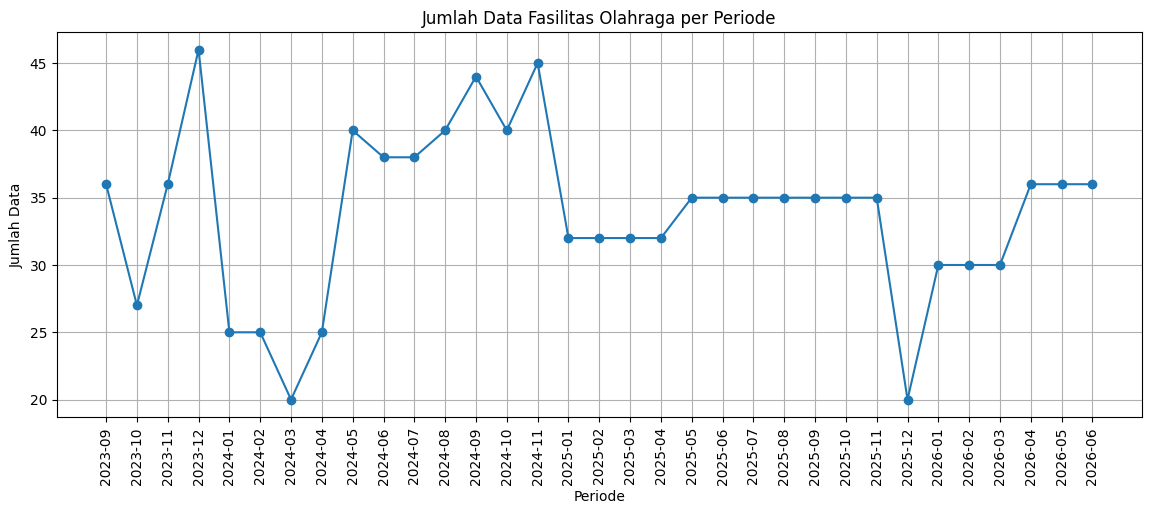

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

plt.plot(
    jumlah_per_periode["periode"],
    jumlah_per_periode["jumlah_data"],
    marker="o"
)

plt.xlabel("Periode")
plt.ylabel("Jumlah Data")
plt.title("Jumlah Data Fasilitas Olahraga per Periode")
plt.xticks(rotation=90)
plt.grid(True)
plt.show()

In [ ]:
print("Jumlah jenis olahraga:", df_final["jenis_olahraga"].nunique())

display(
    df_final["jenis_olahraga"]
    .value_counts()
    .to_frame("jumlah")
)

Jumlah jenis olahraga: 16


,jumlah
jenis_olahraga,
Futsal,563
Bola Volley,175
Sepak Bola,151
Bola Basket,99
Bulutangkis,37
Tenis,25
Gedung Serbaguna,12
Hockey,9
Softball,8


In [ ]:
print("Jumlah kecamatan:", df_final["kecamatan"].nunique())
print("Jumlah kelurahan:", df_final["kelurahan"].nunique())

display(
    df_final.groupby("kecamatan")["kelurahan"]
    .nunique()
    .sort_values(ascending=False)
    .to_frame("jumlah_kelurahan")
)

Jumlah kecamatan: 31
Jumlah kelurahan: 121


,jumlah_kelurahan
kecamatan,
Kec. Wonokromo,9
Kec. Rungkut,8
Kec. Pakal,7
Kec. Sukomanunggal,6
Kec. Benowo,6
Kec. Lakarsantri,6
Kec. Wonocolo,6
Kec. Tandes,5
Kec. Wiyung,5


In [ ]:
print("Tipe data luas:", df_final["luas"].dtype)
print("Missing luas:", df_final["luas"].isna().sum())

display(
    df_final["luas"].describe()
)

Tipe data luas: float64
Missing luas: 22


,luas
count,1094.000000
mean,2490.919447
std,7765.987164
min,4.432000
25%,375.000000
50%,504.000000
75%,686.000000
max,63848.000000


In [ ]:
kolom_pembangunan = [
    "deskripsi_pembangunan_atau_peningkatan_prasarana",
    "tahun_dilakukan_pembangunan_atau_peningkatan_prasarana"
]

for col in kolom_pembangunan:
    print("\n", col)
    print(df_final[col].value_counts(dropna=False).head(10))


 deskripsi_pembangunan_atau_peningkatan_prasarana
deskripsi_pembangunan_atau_peningkatan_prasarana
NaN    948
       168
Name: count, dtype: int64

 tahun_dilakukan_pembangunan_atau_peningkatan_prasarana
tahun_dilakukan_pembangunan_atau_peningkatan_prasarana
NaN    948
       168
Name: count, dtype: int64


In [ ]:
display(
    df_final.loc[
        [703],
        [
            "periode",
            "kecamatan",
            "kelurahan",
            "nama_fasilitas_olahraga",
            "alamatlokasi",
            "jenis_olahraga"
        ]
    ]
)

,periode,kecamatan,kelurahan,nama_fasilitas_olahraga,alamatlokasi,jenis_olahraga
703,2026-01,Kec. Dukuh Pakis,Kel. Dukuh Kupang,Lapangan Futsal Ngesong Dukuh Kupang I RT 2,Ngesong Dukuh Kupang I RT 2,Futsal


In [ ]:
cek_fasilitas_bulan = (
    df_final
    .groupby(["periode", "nama_fasilitas_olahraga", "alamatlokasi"])
    .size()
    .reset_index(name="jumlah")
)

duplikat_fasilitas_bulan = cek_fasilitas_bulan[
    cek_fasilitas_bulan["jumlah"] > 1
]

print(
    "Duplikat fasilitas + alamat pada periode yang sama:",
    len(duplikat_fasilitas_bulan)
)

display(duplikat_fasilitas_bulan)

Duplikat fasilitas + alamat pada periode yang sama: 0


,periode,nama_fasilitas_olahraga,alamatlokasi,jumlah


In [ ]:
kolom_kosong = [
    "deskripsi_pembangunan_atau_peningkatan_prasarana",
    "tahun_dilakukan_pembangunan_atau_peningkatan_prasarana"
]

df_final = df_final.drop(columns=kolom_kosong)

In [ ]:
kolom_dashboard = [
    "data_bulan",
    "data_tahun",
    "periode",
    "kecamatan",
    "kelurahan",
    "nama_fasilitas_olahraga",
    "jenis_olahraga",
    "alamatlokasi",
    "luas",
    "dilakukan_penambahan_pembanguna",
    "difasilitasi_dan_dipelihara",
    "tanggal_pemeliharaan_dan_perbai",
    "deskripsi_pemeliharaan",
    "tahun_dilakukan_pemeliharaan",
    "deskripsi_pemanfaatan",
    "tahun_dilakukan_pemanfaatan"
]

df_dashboard = df_final[kolom_dashboard].copy()

print("Ukuran dataset dashboard:", df_dashboard.shape)

Ukuran dataset dashboard: (1116, 16)


In [ ]:
df_dashboard = df_dashboard.sort_values(
    by=["periode", "kecamatan", "kelurahan", "nama_fasilitas_olahraga"],
    ascending=[True, True, True, True]
).reset_index(drop=True)

In [ ]:
from google.colab import files

df_dashboard.to_csv(
    "dataset_dashboard_fasilitas_olahraga_surabaya.csv",
    index=False,
    encoding="utf-8-sig"
)

files.download("dataset_dashboard_fasilitas_olahraga_surabaya.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Exploratory Data Analysis

In [ ]:
df_dashboard["luas"].describe()

,luas
count,1094.000000
mean,2490.919447
std,7765.987164
min,4.432000
25%,375.000000
50%,504.000000
75%,686.000000
max,63848.000000


In [ ]:
(
    df_dashboard
    .groupby("kecamatan")["luas"]
    .sum()
    .sort_values(ascending=False)
)

,luas
kecamatan,
Kec. Pakal,810450.853381
Kec. Tambaksari,569079.000000
Kec. Jambangan,248939.460000
Kec. Bulak,183654.020000
Kec. Benowo,172802.840000
Kec. Sambikerep,136754.400000
Kec. Gubeng,120432.700000
Kec. Lakarsantri,76624.000000
Kec. Wonokromo,69372.432000


In [ ]:
fasilitas_jenis = (
    df_dashboard
    .groupby("jenis_olahraga")
    .size()
    .reset_index(name="jumlah_fasilitas")
    .sort_values("jumlah_fasilitas", ascending=False)
)

display(fasilitas_jenis)

,jenis_olahraga,jumlah_fasilitas
6,Futsal,563
4,Bola Volley,175
13,Sepak Bola,151
3,Bola Basket,99
5,Bulutangkis,37
15,Tenis,25
7,Gedung Serbaguna,12
8,Hockey,9
14,Softball,8
11,Menembak,8


In [ ]:
fasilitas_kecamatan = (
    df_dashboard
    .groupby("kecamatan")
    .size()
    .reset_index(name="jumlah_fasilitas")
    .sort_values("jumlah_fasilitas", ascending=False)
)

display(fasilitas_kecamatan)

,kecamatan,jumlah_fasilitas
16,Kec. Pakal,129
1,Kec. Benowo,112
17,Kec. Rungkut,92
9,Kec. Jambangan,68
25,Kec. Tandes,64
18,Kec. Sambikerep,63
7,Kec. Gubeng,63
13,Kec. Lakarsantri,55
12,Kec. Krembangan,51
30,Kec. Wonokromo,49


In [ ]:
pivot_jenis_kecamatan = pd.pivot_table(
    df_dashboard,
    index="kecamatan",
    columns="jenis_olahraga",
    values="nama_fasilitas_olahraga",
    aggfunc="count",
    fill_value=0
)

display(pivot_jenis_kecamatan)

jenis_olahraga,Atletik,Balap Motor & Drag Race,Basket 3 on 3,Bola Basket,Bola Volley,Bulutangkis,Futsal,Gedung Serbaguna,Hockey,Jogging Track,Judo,Menembak,Renang,Sepak Bola,Softball,Tenis
kecamatan,,,,,,,,,,,,,,,,
Kec. Asemrowo,0,0,0,0,0,2,7,0,0,0,0,0,0,0,0,1
Kec. Benowo,0,0,0,15,18,4,51,0,0,1,0,0,0,22,0,1
Kec. Bubutan,0,0,0,0,0,2,3,0,0,0,0,0,0,0,0,0
Kec. Bulak,0,0,0,0,0,1,21,0,0,0,0,8,0,0,0,0
Kec. Dukuh Pakis,0,0,0,0,0,0,6,0,0,0,0,0,0,0,0,0
Kec. Gayungan,0,0,0,0,5,0,8,0,0,0,0,0,0,1,0,0
Kec. Genteng,0,0,2,4,1,0,9,0,0,0,0,0,0,0,0,0
Kec. Gubeng,0,0,2,9,6,1,13,0,9,0,0,0,0,6,8,9
Kec. Gunung Anyar,0,0,0,0,0,0,5,0,0,0,0,0,0,0,0,0


In [ ]:
variasi_olahraga = (
    df_dashboard
    .groupby("kecamatan")["jenis_olahraga"]
    .nunique()
    .reset_index(name="jumlah_jenis_olahraga")
    .sort_values("jumlah_jenis_olahraga", ascending=False)
)

display(variasi_olahraga)

,kecamatan,jumlah_jenis_olahraga
7,Kec. Gubeng,9
9,Kec. Jambangan,7
1,Kec. Benowo,7
30,Kec. Wonokromo,7
17,Kec. Rungkut,7
12,Kec. Krembangan,6
18,Kec. Sambikerep,6
16,Kec. Pakal,6
23,Kec. Sukomanunggal,6
28,Kec. Wiyung,6


In [ ]:
luas_kecamatan = (
    df_dashboard
    .groupby("kecamatan")["luas"]
    .agg(
        total_luas="sum",
        rata_rata_luas="mean",
        median_luas="median"
    )
    .reset_index()
    .sort_values("total_luas", ascending=False)
)

display(luas_kecamatan)

,kecamatan,total_luas,rata_rata_luas,median_luas
16,Kec. Pakal,810450.853381,6381.502783,510.00
24,Kec. Tambaksari,569079.000000,21887.653846,11000.00
9,Kec. Jambangan,248939.460000,3771.810000,634.24
3,Kec. Bulak,183654.020000,6332.897241,504.00
1,Kec. Benowo,172802.840000,1570.934909,504.00
18,Kec. Sambikerep,136754.400000,2205.716129,504.00
7,Kec. Gubeng,120432.700000,1974.306557,504.00
13,Kec. Lakarsantri,76624.000000,1418.962963,504.00
30,Kec. Wonokromo,69372.432000,1476.009191,504.00
12,Kec. Krembangan,52775.000000,1055.500000,504.00


In [ ]:
df_dashboard["difasilitasi_dan_dipelihara"].value_counts(dropna=False)

,count
difasilitasi_dan_dipelihara,
Ya,871
NaN,198
Tidak,47


In [ ]:
df_dashboard["deskripsi_pemeliharaan"].value_counts()

,count
deskripsi_pemeliharaan,
Pembersihan lapangan,39
Pembersihan Lapangan,18
Pemotongan rumput sekitar,15
Pembersihan dan pemotongan rumput,13
Pemotongan rumput,11
...,...
Pembersihan lapangan dan pengecatan tiang badminton,1
"Pembersihan Lapangan, pengecatan tiang volley",1
"Pembersihan, perbaikan jaring basket",1


In [ ]:
tren_bulanan = (
    df_dashboard
    .groupby("periode")
    .size()
    .reset_index(name="jumlah_data")
    .sort_values("periode")
)

display(tren_bulanan)

,periode,jumlah_data
0,2023-09,36
1,2023-10,27
2,2023-11,36
3,2023-12,46
4,2024-01,25
5,2024-02,25
6,2024-03,20
7,2024-04,25
8,2024-05,40
9,2024-06,38
